
# RA-DI-MDST: Clean Standard-Algorithm Benchmark

This notebook is intentionally **simple and stable**.

It uses only standard `scikit-learn` classifiers:
- Logistic Regression
- Linear SVM
- RBF SVM
- KNN
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting
- AdaBoost
- MLPClassifier

There is **no PyTorch, CUDA, XGBoost, LightGBM, or CatBoost**.

## Comparison
Each classifier is evaluated under:
1. Original data
2. Reconstructed MDST
3. Proposed RA-DI-MDST

## Metrics
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Balanced Accuracy
- Weighted F1
- Per-class Precision / Recall / F1
- Confusion matrices

## Evaluation
Strict 5-fold stratified CV:
**training fold → scaling → RFE-100 → augmentation → classifier → untouched test fold**


In [1]:

# CELL 1 — Configuration
RUN_MODE = "FULL"   # use QUICK only for debugging
RANDOM_STATE = 42
TARGET = "target"

SAMPLERS = ["Original", "MDST", "RA-DI-MDST"]

MODELS = [
    "LogisticRegression",
    "LinearSVM",
    "RBFSVM",
    "KNN",
    "DecisionTree",
    "RandomForest",
    "ExtraTrees",
    "GradientBoosting",
    "AdaBoost",
    "MLP"
]

if RUN_MODE == "QUICK":
    N_SPLITS = 3
    TREE_ESTIMATORS = 100
    MLP_MAX_ITER = 300
else:
    N_SPLITS = 5
    TREE_ESTIMATORS = 300
    MLP_MAX_ITER = 1000

N_RFE_FEATURES = 100
K_MDST = 3
LAMBDA_LOW = 0.30
LAMBDA_HIGH = 0.70

print("Run mode:", RUN_MODE)
print("Folds:", N_SPLITS)
print("Models:", MODELS)


Run mode: FULL
Folds: 5
Models: ['LogisticRegression', 'LinearSVM', 'RBFSVM', 'KNN', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'GradientBoosting', 'AdaBoost', 'MLP']


In [2]:

# CELL 2 — Imports
import os, glob, time, warnings, zipfile
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    pairwise_distances
)
from scipy.stats import wilcoxon

np.random.seed(RANDOM_STATE)

print("Imports complete.")


Imports complete.


In [3]:

# CELL 3 — Load dataset automatically
patterns = [
    "/kaggle/input/**/*.csv",
    "/kaggle/working/*.csv",
    "/mnt/data/*.csv",
    "./*.csv"
]

csv_files = []
for pattern in patterns:
    csv_files += glob.glob(pattern, recursive=True)

preferred = [
    p for p in csv_files
    if "NN_MissingHandlingdataset" in os.path.basename(p)
]

if preferred:
    DATA_PATH = preferred[0]
elif csv_files:
    DATA_PATH = csv_files[0]
else:
    raise FileNotFoundError(
        "CSV not found. Upload NN_MissingHandlingdataset(1).csv to Kaggle."
    )

df = pd.read_csv(DATA_PATH)

# remove exported index columns
df = df.drop(
    columns=[c for c in df.columns if c.lower().startswith("unnamed:")],
    errors="ignore"
)

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

X_df = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(int).to_numpy()

# convert unexpected nonnumeric columns
for c in X_df.select_dtypes(exclude=[np.number]).columns:
    X_df[c], _ = pd.factorize(X_df[c], sort=True)

if X_df.isna().any().any():
    X_df = X_df.fillna(X_df.median(numeric_only=True))

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Predictors:", X_df.shape[1])
print("Class counts:", pd.Series(y).value_counts().sort_index().to_dict())
print("Missing values:", int(X_df.isna().sum().sum()))
display(df.head())


Loaded: /kaggle/input/datasets/furqanrustam118/avcrashold/NN_MissingHandlingdataset.csv
Shape: (324, 190)
Predictors: 189
Class counts: {0: 237, 1: 52, 2: 35}
Missing values: 0


,AV_manufacturer,AVyear,AVmake,AVmodel,AVregloc,AccidentZIPcode,AccidentSTATE,AccidentCOUNTY,AccidentCITY,AccidentADDRESS,...,AccOTHERfactorsENTERINGORLEAVINGRAMP,AccOTHERfactorsPREVIOUSCOLLISION,AccOTHERfactorsUNFAMILIARWITHROAD,AccOTHERfactorsDEFECTIVEWEHEQUIPYes,AccOTHERfactorsDEFECTIVEWEHEQUIPNo,AccOTHERfactorsUNINVOLVEDVEHICLE,AccOTHERfactorsOTHER,AccOTHERfactorsNONEAPPARENT,AccOTHERfactorsRUNAWAYVEHICLE,target
0,0,2010.0,15,20,1,94043.0,0,11,10,283,...,0,0,0,0,0,0,0,0,0,0
1,1,2017.0,11,21,2,94087.0,0,11,11,299,...,0,0,0,0,0,0,0,0,0,0
2,4,2017.0,12,17,2,94107.0,0,9,6,303,...,0,0,0,0,1,0,0,0,0,1
3,5,2020.0,1,2,1,94109.0,0,9,6,204,...,0,0,0,0,0,0,0,0,0,0
4,5,2020.0,2,2,1,94111.0,0,9,6,302,...,0,0,0,0,0,0,0,0,0,0


In [4]:

# CELL 4 — Fold-internal scaling + RFE
def fit_transform_rfe(X_train, y_train, X_test, n_features=100, seed=42):
    scaler = StandardScaler()
    Xtr_scaled = scaler.fit_transform(X_train)
    Xte_scaled = scaler.transform(X_test)

    n_select = min(n_features, Xtr_scaled.shape[1])

    estimator = LinearSVC(
        C=1.0,
        dual=False,
        max_iter=15000,
        random_state=seed
    )

    selector = RFE(
        estimator=estimator,
        n_features_to_select=n_select,
        step=5
    )

    Xtr_rfe = selector.fit_transform(Xtr_scaled, y_train)
    Xte_rfe = selector.transform(Xte_scaled)

    return Xtr_rfe, Xte_rfe, selector, scaler


In [5]:

# CELL 5 — Reconstructed MDST
def reconstructed_mdst(X, y, k=3, random_state=42):
    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)

    classes, counts = np.unique(y, return_counts=True)
    target_n = int(counts.max())

    X_out = [row.copy() for row in X]
    y_out = list(y)

    for cls, n_cls in zip(classes, counts):
        if n_cls >= target_n:
            continue

        B = X[y == cls]
        need = target_n - len(B)

        if len(B) < 2:
            continue

        de = pairwise_distances(B, metric="euclidean")
        dm = pairwise_distances(B, metric="manhattan")
        np.fill_diagonal(de, np.inf)
        np.fill_diagonal(dm, np.inf)

        kk = min(k, len(B) - 1)

        for t in range(need):
            s = int(rng.integers(0, len(B)))

            ne = np.argsort(de[s])[:kk]
            nm = np.argsort(dm[s])[:kk]

            mean_e = np.vstack([B[s], B[ne]]).mean(axis=0)
            mean_m = np.vstack([B[s], B[nm]]).mean(axis=0)

            syn = mean_e if t % 2 == 0 else mean_m

            X_out.append(syn)
            y_out.append(cls)

    return np.asarray(X_out), np.asarray(y_out)


In [6]:

# CELL 6 — Proposed RA-DI-MDST
def ra_di_mdst(
    X,
    y,
    k=3,
    lam_low=0.30,
    lam_high=0.70,
    random_state=42
):
    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)

    classes, counts = np.unique(y, return_counts=True)
    target_n = int(counts.max())

    X_out = [row.copy() for row in X]
    y_out = list(y)
    diagnostics = []

    for cls, n_cls in zip(classes, counts):
        if n_cls >= target_n:
            continue

        B = X[y == cls]
        need = target_n - len(B)

        if len(B) < 2:
            continue

        de = pairwise_distances(B, metric="euclidean")
        dm = pairwise_distances(B, metric="manhattan")
        np.fill_diagonal(de, np.inf)
        np.fill_diagonal(dm, np.inf)

        kk = min(k, len(B) - 1)

        for _ in range(need):
            s = int(rng.integers(0, len(B)))

            eu = list(np.argsort(de[s])[:kk])
            eu_set = set(eu)

            man_rank = list(np.argsort(dm[s]))
            man_exclusive = []

            for idx in man_rank:
                idx = int(idx)
                if idx == s or idx in eu_set:
                    continue

                man_exclusive.append(idx)

                if len(man_exclusive) == kk:
                    break

            pool = eu + man_exclusive

            if not pool:
                continue

            q = int(rng.choice(pool))
            lam = float(rng.uniform(lam_low, lam_high))

            syn = B[s] + lam * (B[q] - B[s])

            top_m = set(np.argsort(dm[s])[:kk])
            overlap = len(eu_set & top_m) / kk

            diagnostics.append({
                "class": int(cls),
                "overlap": float(overlap),
                "pool_size": int(len(set(pool)))
            })

            X_out.append(syn)
            y_out.append(cls)

    return np.asarray(X_out), np.asarray(y_out), pd.DataFrame(diagnostics)


def apply_sampler(name, X_train, y_train, seed):
    if name == "Original":
        return np.asarray(X_train), np.asarray(y_train), None

    if name == "MDST":
        Xr, yr = reconstructed_mdst(
            X_train,
            y_train,
            k=K_MDST,
            random_state=seed
        )
        return Xr, yr, None

    if name == "RA-DI-MDST":
        Xr, yr, diag = ra_di_mdst(
            X_train,
            y_train,
            k=K_MDST,
            lam_low=LAMBDA_LOW,
            lam_high=LAMBDA_HIGH,
            random_state=seed
        )
        return Xr, yr, diag

    raise ValueError(name)


In [7]:

# CELL 7 — Standard classifier factory
def get_model(name, seed=42):
    if name == "LogisticRegression":
        return LogisticRegression(
            C=1.0,
            max_iter=5000,
            random_state=seed
        )

    if name == "LinearSVM":
        return SVC(
            kernel="linear",
            C=1.0,
            random_state=seed
        )

    if name == "RBFSVM":
        return SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=seed
        )

    if name == "KNN":
        return KNeighborsClassifier(
            n_neighbors=5,
            weights="distance"
        )

    if name == "DecisionTree":
        return DecisionTreeClassifier(
            random_state=seed,
            max_depth=None
        )

    if name == "RandomForest":
        return RandomForestClassifier(
            n_estimators=TREE_ESTIMATORS,
            random_state=seed,
            n_jobs=-1
        )

    if name == "ExtraTrees":
        return ExtraTreesClassifier(
            n_estimators=TREE_ESTIMATORS,
            random_state=seed,
            n_jobs=-1
        )

    if name == "GradientBoosting":
        return GradientBoostingClassifier(
            n_estimators=150 if RUN_MODE == "FULL" else 60,
            learning_rate=0.05,
            random_state=seed
        )

    if name == "AdaBoost":
        return AdaBoostClassifier(
            n_estimators=150 if RUN_MODE == "FULL" else 60,
            learning_rate=0.05,
            random_state=seed
        )

    if name == "MLP":
        return MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=1e-4,
            learning_rate_init=1e-3,
            max_iter=MLP_MAX_ITER,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=seed
        )

    raise ValueError(f"Unknown model: {name}")


In [8]:

# CELL 8 — Metrics
CLASS_LABELS = sorted(np.unique(y).tolist())

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "f1_weighted": f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        )
    }


def classwise_metrics(y_true, y_pred):
    P = precision_score(
        y_true, y_pred,
        labels=CLASS_LABELS,
        average=None,
        zero_division=0
    )
    R = recall_score(
        y_true, y_pred,
        labels=CLASS_LABELS,
        average=None,
        zero_division=0
    )
    F = f1_score(
        y_true, y_pred,
        labels=CLASS_LABELS,
        average=None,
        zero_division=0
    )

    rows = []

    for i, c in enumerate(CLASS_LABELS):
        rows.append({
            "class": int(c),
            "precision": float(P[i]),
            "recall": float(R[i]),
            "f1": float(F[i]),
            "support": int((np.asarray(y_true) == c).sum())
        })

    return rows


In [9]:

# CELL 9 — Main strict experiment
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_rows = []
oof_store = {}
all_diagnostics = []

for sampler_name in SAMPLERS:
    for model_name in MODELS:

        print(f"\nRunning: {sampler_name} + {model_name}")

        y_true_all = []
        y_pred_all = []

        for fold, (train_idx, test_idx) in enumerate(
            cv.split(X_df, y),
            start=1
        ):
            X_train_raw = X_df.iloc[train_idx].to_numpy(dtype=float)
            X_test_raw = X_df.iloc[test_idx].to_numpy(dtype=float)
            y_train = y[train_idx]
            y_test = y[test_idx]

            # strict fold-internal preprocessing
            X_train, X_test, selector, scaler = fit_transform_rfe(
                X_train_raw,
                y_train,
                X_test_raw,
                n_features=N_RFE_FEATURES,
                seed=RANDOM_STATE + fold
            )

            # training-fold-only augmentation
            X_aug, y_aug, diag = apply_sampler(
                sampler_name,
                X_train,
                y_train,
                seed=RANDOM_STATE + fold
            )

            if diag is not None and len(diag):
                d = diag.copy()
                d["sampler"] = sampler_name
                d["fold"] = fold
                all_diagnostics.append(d)

            model = get_model(
                model_name,
                seed=RANDOM_STATE + fold
            )

            start = time.time()
            model.fit(X_aug, y_aug)
            pred = model.predict(X_test)
            runtime = time.time() - start

            m = calculate_metrics(y_test, pred)

            fold_rows.append({
                "sampler": sampler_name,
                "model": model_name,
                "fold": fold,
                "train_real_n": len(y_train),
                "train_after_sampling_n": len(y_aug),
                "runtime_sec": runtime,
                **m
            })

            y_true_all.extend(y_test.tolist())
            y_pred_all.extend(pred.tolist())

        oof_store[(sampler_name, model_name)] = {
            "y_true": np.asarray(y_true_all),
            "y_pred": np.asarray(y_pred_all)
        }

fold_df = pd.DataFrame(fold_rows)

print("\nExperiment complete.")
display(fold_df.head())



Running: Original + LogisticRegression

Running: Original + LinearSVM

Running: Original + RBFSVM

Running: Original + KNN

Running: Original + DecisionTree

Running: Original + RandomForest

Running: Original + ExtraTrees

Running: Original + GradientBoosting

Running: Original + AdaBoost

Running: Original + MLP

Running: MDST + LogisticRegression

Running: MDST + LinearSVM

Running: MDST + RBFSVM

Running: MDST + KNN

Running: MDST + DecisionTree

Running: MDST + RandomForest

Running: MDST + ExtraTrees

Running: MDST + GradientBoosting

Running: MDST + AdaBoost

Running: MDST + MLP

Running: RA-DI-MDST + LogisticRegression

Running: RA-DI-MDST + LinearSVM

Running: RA-DI-MDST + RBFSVM

Running: RA-DI-MDST + KNN

Running: RA-DI-MDST + DecisionTree

Running: RA-DI-MDST + RandomForest

Running: RA-DI-MDST + ExtraTrees

Running: RA-DI-MDST + GradientBoosting

Running: RA-DI-MDST + AdaBoost

Running: RA-DI-MDST + MLP

Experiment complete.


,sampler,model,fold,train_real_n,train_after_sampling_n,runtime_sec,accuracy,precision_macro,recall_macro,f1_macro,balanced_accuracy,f1_weighted
0,Original,LogisticRegression,1,259,259,0.021817,0.692308,0.546296,0.568651,0.556287,0.568651,0.688799
1,Original,LogisticRegression,2,259,259,0.012456,0.753846,0.576720,0.567857,0.571868,0.567857,0.750424
2,Original,LogisticRegression,3,259,259,0.010850,0.661538,0.486667,0.455651,0.467518,0.455651,0.650784
3,Original,LogisticRegression,4,259,259,0.013599,0.661538,0.498366,0.455651,0.465039,0.455651,0.649200
4,Original,LogisticRegression,5,260,260,0.011774,0.625000,0.444898,0.417224,0.427778,0.417224,0.618490


In [10]:

# CELL 10 — Overall summary
metric_cols = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "balanced_accuracy",
    "f1_weighted",
    "runtime_sec"
]

summary_rows = []

for (sampler, model), g in fold_df.groupby(["sampler", "model"]):
    row = {
        "sampler": sampler,
        "model": model
    }

    for metric in metric_cols:
        row[f"{metric}_mean"] = g[metric].mean()
        row[f"{metric}_std"] = g[metric].std(ddof=0)

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).sort_values(
    ["f1_macro_mean", "balanced_accuracy_mean", "accuracy_mean"],
    ascending=False
).reset_index(drop=True)

display(
    summary_df[
        [
            "sampler",
            "model",
            "accuracy_mean",
            "precision_macro_mean",
            "recall_macro_mean",
            "f1_macro_mean",
            "balanced_accuracy_mean",
            "f1_weighted_mean",
            "accuracy_std",
            "f1_macro_std"
        ]
    ].round(4)
)

fold_df.to_csv("ALL_FOLD_RESULTS.csv", index=False)
summary_df.to_csv("OVERALL_SUMMARY.csv", index=False)


,sampler,model,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,balanced_accuracy_mean,f1_weighted_mean,accuracy_std,f1_macro_std
0,RA-DI-MDST,DecisionTree,0.6819,0.5283,0.5358,0.5268,0.5358,0.6838,0.0417,0.0556
1,MDST,LinearSVM,0.6725,0.5373,0.5279,0.5238,0.5279,0.6740,0.0558,0.0782
2,Original,LinearSVM,0.6788,0.5354,0.5215,0.5181,0.5215,0.6755,0.0420,0.0766
3,RA-DI-MDST,LinearSVM,0.6695,0.5272,0.5213,0.5159,0.5213,0.6696,0.0511,0.0808
4,MDST,LogisticRegression,0.6479,0.4974,0.5271,0.5057,0.5271,0.6543,0.0526,0.0626
5,RA-DI-MDST,MLP,0.6851,0.5326,0.4895,0.5033,0.4895,0.6769,0.0448,0.0475
6,Original,LogisticRegression,0.6788,0.5106,0.4930,0.4977,0.4930,0.6715,0.0431,0.0562
7,RA-DI-MDST,GradientBoosting,0.6822,0.5227,0.4961,0.4976,0.4961,0.6681,0.0466,0.0425
8,RA-DI-MDST,LogisticRegression,0.6294,0.4816,0.5163,0.4896,0.5163,0.6400,0.0553,0.0656
9,Original,DecisionTree,0.6696,0.4844,0.4907,0.4818,0.4907,0.6692,0.0664,0.0994


In [11]:

# CELL 11 — Per-class Precision / Recall / F1
class_rows = []

for (sampler, model), data in oof_store.items():
    for row in classwise_metrics(
        data["y_true"],
        data["y_pred"]
    ):
        class_rows.append({
            "sampler": sampler,
            "model": model,
            **row
        })

class_df = pd.DataFrame(class_rows)

display(
    class_df.sort_values(
        ["model", "sampler", "class"]
    ).round(4)
)

class_df.to_csv(
    "CLASSWISE_PRECISION_RECALL_F1.csv",
    index=False
)


,sampler,model,class,precision,recall,f1,support
54,MDST,AdaBoost,0,0.7300,0.7300,0.7300,237
55,MDST,AdaBoost,1,0.2041,0.1923,0.1980,52
56,MDST,AdaBoost,2,0.2368,0.2571,0.2466,35
24,Original,AdaBoost,0,0.7315,1.0000,0.8449,237
25,Original,AdaBoost,1,0.0000,0.0000,0.0000,52
...,...,...,...,...,...,...,...
16,Original,RandomForest,1,0.6000,0.0577,0.1053,52
17,Original,RandomForest,2,0.8333,0.1429,0.2439,35
75,RA-DI-MDST,RandomForest,0,0.7535,0.9156,0.8267,237
76,RA-DI-MDST,RandomForest,1,0.3750,0.1154,0.1765,52


In [12]:

# CELL 12 — Direct MDST vs RA-DI-MDST comparison
comparison_rows = []

for model_name in MODELS:
    mdst = summary_df[
        (summary_df["sampler"] == "MDST") &
        (summary_df["model"] == model_name)
    ]

    radi = summary_df[
        (summary_df["sampler"] == "RA-DI-MDST") &
        (summary_df["model"] == model_name)
    ]

    if len(mdst) == 0 or len(radi) == 0:
        continue

    a = mdst.iloc[0]
    b = radi.iloc[0]

    comparison_rows.append({
        "model": model_name,
        "MDST_accuracy": a["accuracy_mean"],
        "RA_DI_accuracy": b["accuracy_mean"],
        "delta_accuracy": b["accuracy_mean"] - a["accuracy_mean"],

        "MDST_precision_macro": a["precision_macro_mean"],
        "RA_DI_precision_macro": b["precision_macro_mean"],
        "delta_precision_macro":
            b["precision_macro_mean"] - a["precision_macro_mean"],

        "MDST_recall_macro": a["recall_macro_mean"],
        "RA_DI_recall_macro": b["recall_macro_mean"],
        "delta_recall_macro":
            b["recall_macro_mean"] - a["recall_macro_mean"],

        "MDST_f1_macro": a["f1_macro_mean"],
        "RA_DI_f1_macro": b["f1_macro_mean"],
        "delta_f1_macro":
            b["f1_macro_mean"] - a["f1_macro_mean"],

        "MDST_balanced_accuracy": a["balanced_accuracy_mean"],
        "RA_DI_balanced_accuracy": b["balanced_accuracy_mean"],
        "delta_balanced_accuracy":
            b["balanced_accuracy_mean"] - a["balanced_accuracy_mean"]
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    "delta_f1_macro",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

comparison_df.to_csv(
    "MDST_VS_RA_DI_ALL_MODELS.csv",
    index=False
)


,model,MDST_accuracy,RA_DI_accuracy,delta_accuracy,MDST_precision_macro,RA_DI_precision_macro,delta_precision_macro,MDST_recall_macro,RA_DI_recall_macro,delta_recall_macro,MDST_f1_macro,RA_DI_f1_macro,delta_f1_macro,MDST_balanced_accuracy,RA_DI_balanced_accuracy,delta_balanced_accuracy
0,RBFSVM,0.7130,0.7191,0.0062,0.3553,0.5467,0.1914,0.3516,0.4161,0.0644,0.3268,0.4327,0.1060,0.3516,0.4161,0.0644
1,DecisionTree,0.6262,0.6819,0.0556,0.4451,0.5283,0.0832,0.4609,0.5358,0.0748,0.4457,0.5268,0.0811,0.4609,0.5358,0.0748
2,RandomForest,0.7376,0.7191,-0.0186,0.4807,0.5224,0.0417,0.3814,0.4392,0.0578,0.3681,0.4480,0.0799,0.3814,0.4392,0.0578
3,ExtraTrees,0.7252,0.7099,-0.0154,0.5089,0.5074,-0.0016,0.3937,0.4257,0.0320,0.3927,0.4373,0.0446,0.3937,0.4257,0.0320
4,GradientBoosting,0.6914,0.6822,-0.0092,0.5093,0.5227,0.0134,0.4423,0.4961,0.0538,0.4564,0.4976,0.0412,0.4423,0.4961,0.0538
5,MLP,0.6821,0.6851,0.0030,0.4993,0.5326,0.0334,0.4504,0.4895,0.0391,0.4645,0.5033,0.0388,0.4504,0.4895,0.0391
6,AdaBoost,0.5925,0.5275,-0.0650,0.3803,0.4205,0.0402,0.3941,0.4625,0.0684,0.3786,0.4121,0.0334,0.3941,0.4625,0.0684
7,KNN,0.4630,0.4878,0.0248,0.4736,0.4523,-0.0213,0.5838,0.5445,-0.0394,0.4305,0.4336,0.0031,0.5838,0.5445,-0.0394
8,LinearSVM,0.6725,0.6695,-0.0030,0.5373,0.5272,-0.0101,0.5279,0.5213,-0.0066,0.5238,0.5159,-0.0079,0.5279,0.5213,-0.0066
9,LogisticRegression,0.6479,0.6294,-0.0186,0.4974,0.4816,-0.0158,0.5271,0.5163,-0.0108,0.5057,0.4896,-0.0162,0.5271,0.5163,-0.0108


In [13]:

# CELL 13 — Paired-fold Wilcoxon tests
stats_rows = []

for model_name in MODELS:
    mdst = fold_df[
        (fold_df["sampler"] == "MDST") &
        (fold_df["model"] == model_name)
    ].sort_values("fold")

    radi = fold_df[
        (fold_df["sampler"] == "RA-DI-MDST") &
        (fold_df["model"] == model_name)
    ].sort_values("fold")

    if len(mdst) != len(radi) or len(mdst) < 2:
        continue

    for metric in [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro",
        "balanced_accuracy"
    ]:
        try:
            stat, p = wilcoxon(
                radi[metric].values,
                mdst[metric].values,
                alternative="greater"
            )
        except Exception:
            stat, p = np.nan, np.nan

        stats_rows.append({
            "model": model_name,
            "metric": metric,
            "MDST_mean": mdst[metric].mean(),
            "RA_DI_mean": radi[metric].mean(),
            "delta": radi[metric].mean() - mdst[metric].mean(),
            "wilcoxon_p_one_sided": p
        })

stats_df = pd.DataFrame(stats_rows)

display(
    stats_df[
        stats_df["metric"] == "f1_macro"
    ].sort_values(
        "delta",
        ascending=False
    ).round(5)
)

stats_df.to_csv(
    "WILCOXON_MDST_VS_RA_DI.csv",
    index=False
)


,model,metric,MDST_mean,RA_DI_mean,delta,wilcoxon_p_one_sided
13,RBFSVM,f1_macro,0.32676,0.43274,0.10598,0.06250
23,DecisionTree,f1_macro,0.44565,0.52677,0.08112,0.15625
28,RandomForest,f1_macro,0.36809,0.44800,0.07991,0.03125
33,ExtraTrees,f1_macro,0.39266,0.43730,0.04464,0.15625
38,GradientBoosting,f1_macro,0.45641,0.49759,0.04118,0.09375
48,MLP,f1_macro,0.46450,0.50326,0.03876,0.31250
43,AdaBoost,f1_macro,0.37861,0.41205,0.03344,0.15625
18,KNN,f1_macro,0.43055,0.43365,0.00310,0.50000
8,LinearSVM,f1_macro,0.52375,0.51587,-0.00789,1.00000
3,LogisticRegression,f1_macro,0.50572,0.48955,-0.01617,0.93750


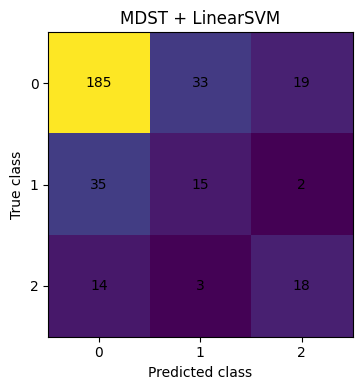

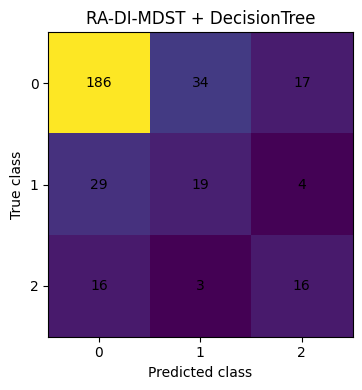

In [14]:

# CELL 14 — Best-model confusion matrices
for sampler_name in ["MDST", "RA-DI-MDST"]:
    best_row = summary_df[
        summary_df["sampler"] == sampler_name
    ].sort_values(
        ["f1_macro_mean", "balanced_accuracy_mean"],
        ascending=False
    ).iloc[0]

    key = (sampler_name, best_row["model"])
    y_true = oof_store[key]["y_true"]
    y_pred = oof_store[key]["y_pred"]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_LABELS
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm)
    ax.set_title(
        f'{sampler_name} + {best_row["model"]}'
    )
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(CLASS_LABELS)))
    ax.set_xticklabels(CLASS_LABELS)
    ax.set_yticks(range(len(CLASS_LABELS)))
    ax.set_yticklabels(CLASS_LABELS)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()
    fname = (
        f'CONFUSION_{sampler_name.replace("-", "_")}_'
        f'{best_row["model"]}.png'
    )
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()


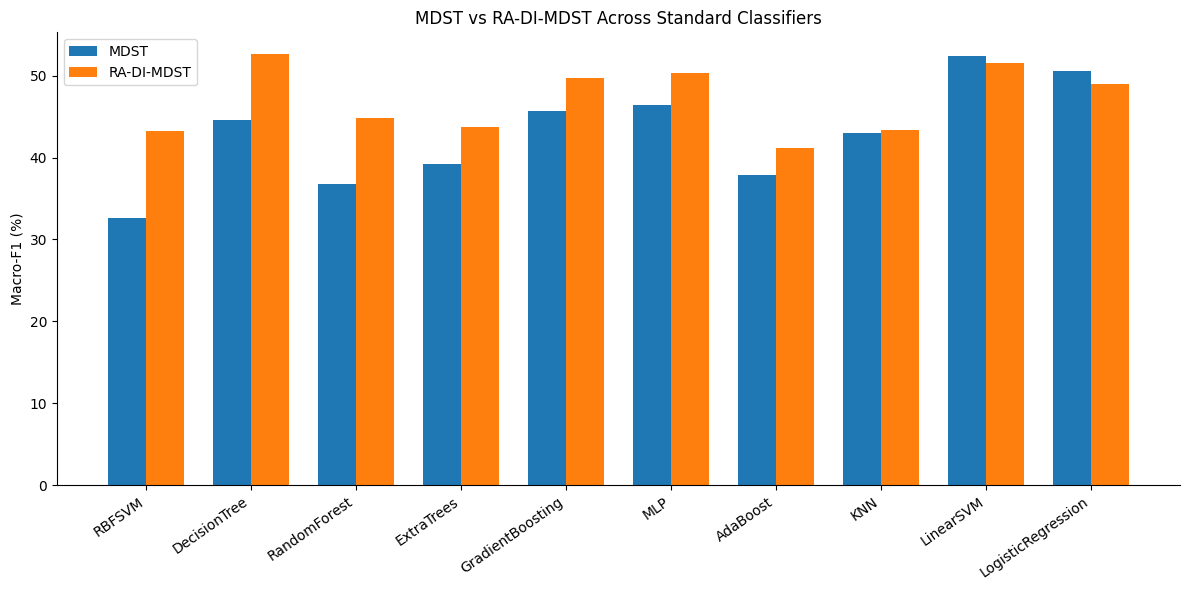

In [15]:

# CELL 15 — Macro-F1 comparison chart
plot_df = comparison_df.copy()

x = np.arange(len(plot_df))
w = 0.36

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - w/2,
    plot_df["MDST_f1_macro"] * 100,
    width=w,
    label="MDST"
)

ax.bar(
    x + w/2,
    plot_df["RA_DI_f1_macro"] * 100,
    width=w,
    label="RA-DI-MDST"
)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["model"],
    rotation=35,
    ha="right"
)

ax.set_ylabel("Macro-F1 (%)")
ax.set_title(
    "MDST vs RA-DI-MDST Across Standard Classifiers"
)

ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "FIG_MDST_VS_RA_DI_MACRO_F1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [16]:

# CELL 16 — Exact RA-DI overlap diagnostics
if all_diagnostics:
    diag_df = pd.concat(
        all_diagnostics,
        ignore_index=True
    )

    print("Mean overlap:", round(diag_df["overlap"].mean(), 4))
    print("Median overlap:", round(diag_df["overlap"].median(), 4))
    print(
        "Mean diversified pool size:",
        round(diag_df["pool_size"].mean(), 4)
    )

    display(
        diag_df.groupby("fold")[
            ["overlap", "pool_size"]
        ].mean().round(4)
    )

    diag_df.to_csv(
        "RA_DI_NEIGHBOR_DIAGNOSTICS.csv",
        index=False
    )


Mean overlap: 0.7554
Median overlap: 0.6667
Mean diversified pool size: 6.0


,overlap,pool_size
fold,,
1,0.7381,6.0
2,0.7305,6.0
3,0.7728,6.0
4,0.7428,6.0
5,0.7925,6.0


In [17]:

# CELL 17 — Export paper-ready tables and ZIP
summary_df.to_csv(
    "TABLE_A_OVERALL_PERFORMANCE.csv",
    index=False
)

class_df.to_csv(
    "TABLE_B_CLASSWISE_PRECISION_RECALL_F1.csv",
    index=False
)

comparison_df.to_csv(
    "TABLE_C_MDST_VS_RA_DI.csv",
    index=False
)

output_files = [
    "ALL_FOLD_RESULTS.csv",
    "OVERALL_SUMMARY.csv",
    "CLASSWISE_PRECISION_RECALL_F1.csv",
    "MDST_VS_RA_DI_ALL_MODELS.csv",
    "WILCOXON_MDST_VS_RA_DI.csv",
    "RA_DI_NEIGHBOR_DIAGNOSTICS.csv",
    "TABLE_A_OVERALL_PERFORMANCE.csv",
    "TABLE_B_CLASSWISE_PRECISION_RECALL_F1.csv",
    "TABLE_C_MDST_VS_RA_DI.csv",
    "FIG_MDST_VS_RA_DI_MACRO_F1.png"
]

with zipfile.ZipFile(
    "RA_DI_STANDARD_ALGORITHMS_RESULTS.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for f in output_files:
        if os.path.exists(f):
            z.write(f)

print("Created: RA_DI_STANDARD_ALGORITHMS_RESULTS.zip")


Created: RA_DI_STANDARD_ALGORITHMS_RESULTS.zip



# What to send back after running

Please send either:

- the executed notebook, or
- `RA_DI_STANDARD_ALGORITHMS_RESULTS.zip`

The most important output for the reviewer is:

1. `TABLE_A_OVERALL_PERFORMANCE.csv`
2. `TABLE_B_CLASSWISE_PRECISION_RECALL_F1.csv`
3. `TABLE_C_MDST_VS_RA_DI.csv`

The key question is whether RA-DI-MDST improves **Macro Precision, Macro Recall, Macro-F1, and Balanced Accuracy across multiple classifier families**, not only Linear SVM.


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 18,
    "font.weight": "semibold",
    "axes.titleweight": "bold",
    "figure.dpi": 300,
})

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
fig.patch.set_facecolor("white")

navy = "#17365D"
green = "#2CA43B"
magenta = "#D92C83"
orange = "#FF7F0E"
red = "#C62828"
blue = "#245A9B"

seed = np.array([0.0, 0.0])

def base_panel(ax, title):
    ax.set_title(title, fontsize=26, pad=16)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-1.42, 1.42)
    ax.set_ylim(-1.25, 1.25)
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ["top", "right", "bottom", "left"]:
        ax.spines[side].set_visible(False)
    ax.scatter(*seed, s=520, marker="*", color="black", edgecolor="white",
               linewidth=1.8, zorder=8)
    ax.text(seed[0] + 0.07, seed[1] + 0.08, "Seed", fontsize=21,
            fontweight="bold", ha="left", va="bottom", zorder=9)

def edge(ax, p, color, linestyle, width=4.0, z=2):
    ax.plot([seed[0], p[0]], [seed[1], p[1]], color=color,
            linestyle=linestyle, linewidth=width, zorder=z,
            solid_capstyle="round", dash_capstyle="round")

def point(ax, p, color, marker="o", size=230, z=6):
    ax.scatter(*p, s=size, marker=marker, color=color, edgecolor="white",
               linewidth=1.8, zorder=z)

# -------------------- (a) Original MDST --------------------
ax = axes[0]
base_panel(ax, "(a) Original MDST")

e1 = np.array([-1.03, 0.62])
e2 = np.array([0.58, 0.93])
e3 = np.array([0.98, -0.28])
m3 = np.array([-0.78, -0.88])

# Green Euclidean edges first; magenta duplicates are drawn on top.
for p in [e1, e2, e3]:
    edge(ax, p, green, "--", 4.2, 2)
for p in [e1, e2, m3]:
    edge(ax, p, magenta, ":", 4.6, 3)

point(ax, e1, magenta)
point(ax, e2, magenta)
point(ax, e3, green)
point(ax, m3, magenta)

ax.text(e1[0]-0.05, e1[1]+0.18, "E1 / M1", fontsize=20, ha="center")
ax.text(e2[0]+0.03, e2[1]+0.17, "E2 / M2", fontsize=20, ha="center")
ax.text(e3[0]+0.08, e3[1]+0.02, "E3", fontsize=20, ha="left")
ax.text(m3[0]-0.02, m3[1]-0.18, "M3", fontsize=20, ha="center")

ax.text(0.50, -0.05,
        "Two Manhattan neighbors duplicate\nEuclidean selections",
        transform=ax.transAxes, ha="center", va="center", fontsize=19,
        fontweight="bold", color=red,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="#FFF3F3",
                  edgecolor="#D9534F", linewidth=2.2))

# -------------------- (b) Proposed RA-MDST --------------------
ax = axes[1]
base_panel(ax, "(b) Proposed RA-MDST")

eu = [np.array([-0.98, 0.58]), np.array([0.10, 1.00]), np.array([1.02, -0.25])]
mn = [np.array([0.92, 0.56]), np.array([-0.88, -0.86]), np.array([0.18, -1.00])]

for p in eu:
    edge(ax, p, green, "--", 4.2, 2)
for p in mn:
    edge(ax, p, magenta, ":", 4.6, 3)

for p in eu:
    point(ax, p, green)
for p in mn:
    point(ax, p, magenta)

labels_e = [("E1", eu[0], (-0.07, 0.18)),
            ("E2", eu[1], (0.03, 0.17)),
            ("E3", eu[2], (0.08, 0.02))]
for label, p, off in labels_e:
    ax.text(p[0]+off[0], p[1]+off[1], label, fontsize=20, ha="center")

ax.text(mn[0][0]+0.08, mn[0][1]+0.12, r"$M_{1}^{\mathrm{excl}}$", fontsize=20, ha="left")
ax.text(mn[1][0]-0.08, mn[1][1]-0.03, r"$M_{2}^{\mathrm{excl}}$", fontsize=20, ha="right")
ax.text(mn[2][0], mn[2][1]-0.20, r"$M_{3}^{\mathrm{excl}}$", fontsize=20, ha="center")

# Bounded interpolation from seed toward one exclusive candidate.
chosen = mn[2]
lam = 0.48
syn = seed + lam * (chosen - seed)
ax.plot([seed[0], syn[0]], [seed[1], syn[1]], color=orange,
        linewidth=5.0, zorder=5, solid_capstyle="round")
point(ax, syn, orange, marker="D", size=260, z=7)
ax.text(syn[0]+0.10, syn[1]-0.02, r"$X_{\mathrm{syn}}$", fontsize=21,
        color=orange, fontweight="bold", ha="left", va="center")

ax.text(0.50, -0.05,
        "Six distinct candidates enable\nbounded pairwise interpolation",
        transform=ax.transAxes, ha="center", va="center", fontsize=19,
        fontweight="bold", color=blue,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="#F0F6FF",
                  edgecolor="#4A90E2", linewidth=2.2))

# Larger, clearer legend.
legend_handles = [
    Line2D([0], [0], marker="*", color="none", markerfacecolor="black",
           markeredgecolor="white", markersize=22, label="Seed observation"),
    Line2D([0], [0], marker="o", color=green, linestyle="--", linewidth=3.5,
           markerfacecolor=green, markeredgecolor="white", markersize=14,
           label="Euclidean neighbor"),
    Line2D([0], [0], marker="o", color=magenta, linestyle=":", linewidth=3.8,
           markerfacecolor=magenta, markeredgecolor="white", markersize=14,
           label="Manhattan neighbor"),
    Line2D([0], [0], marker="D", color=orange, linestyle="-", linewidth=3.8,
           markerfacecolor=orange, markeredgecolor="white", markersize=14,
           label="Synthetic observation"),
]

fig.legend(handles=legend_handles, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, 0.015), fontsize=18,
           frameon=True, fancybox=True, edgecolor="#BFBFBF",
           handlelength=2.0, handletextpad=0.55, columnspacing=1.25,
           borderpad=0.65)

plt.subplots_adjust(left=0.025, right=0.985, top=0.91, bottom=0.235, wspace=0.08)
plt.savefig("fig3_mdst_vs_ra_mdst_revised.png", dpi=300, facecolor="white")
plt.savefig("fig3_mdst_vs_ra_mdst_revised.pdf", facecolor="white")
plt.close()

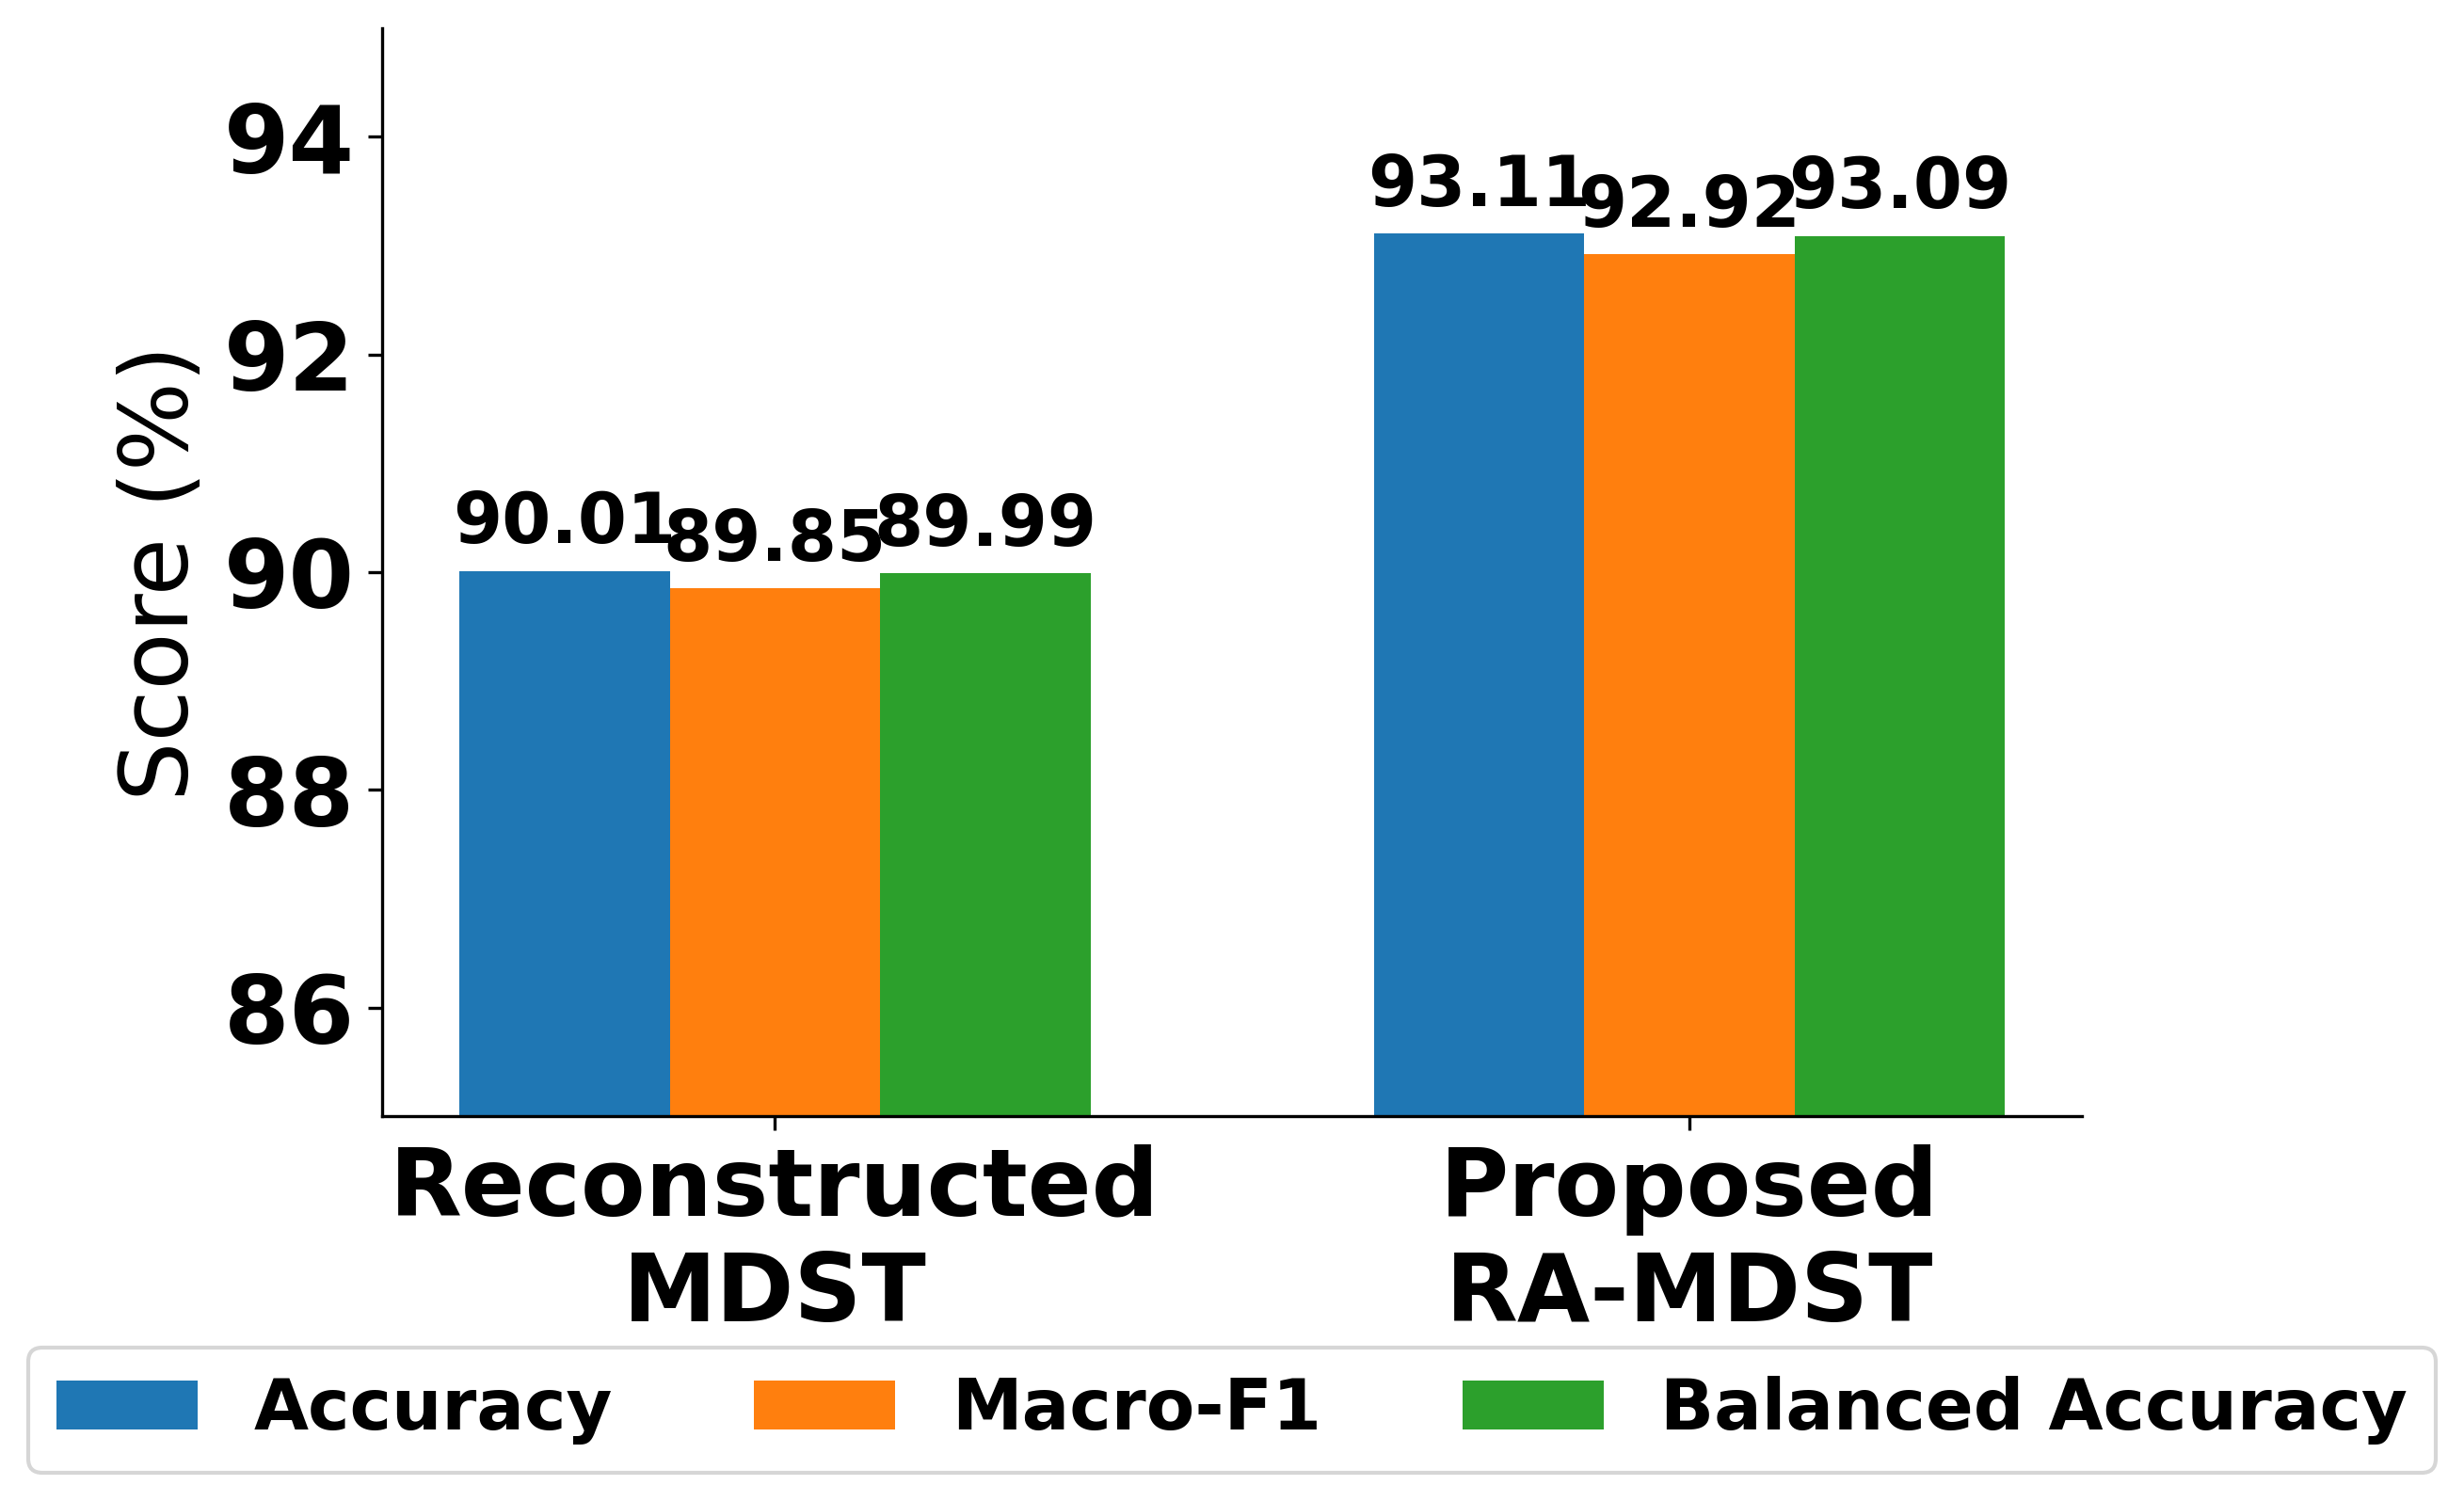

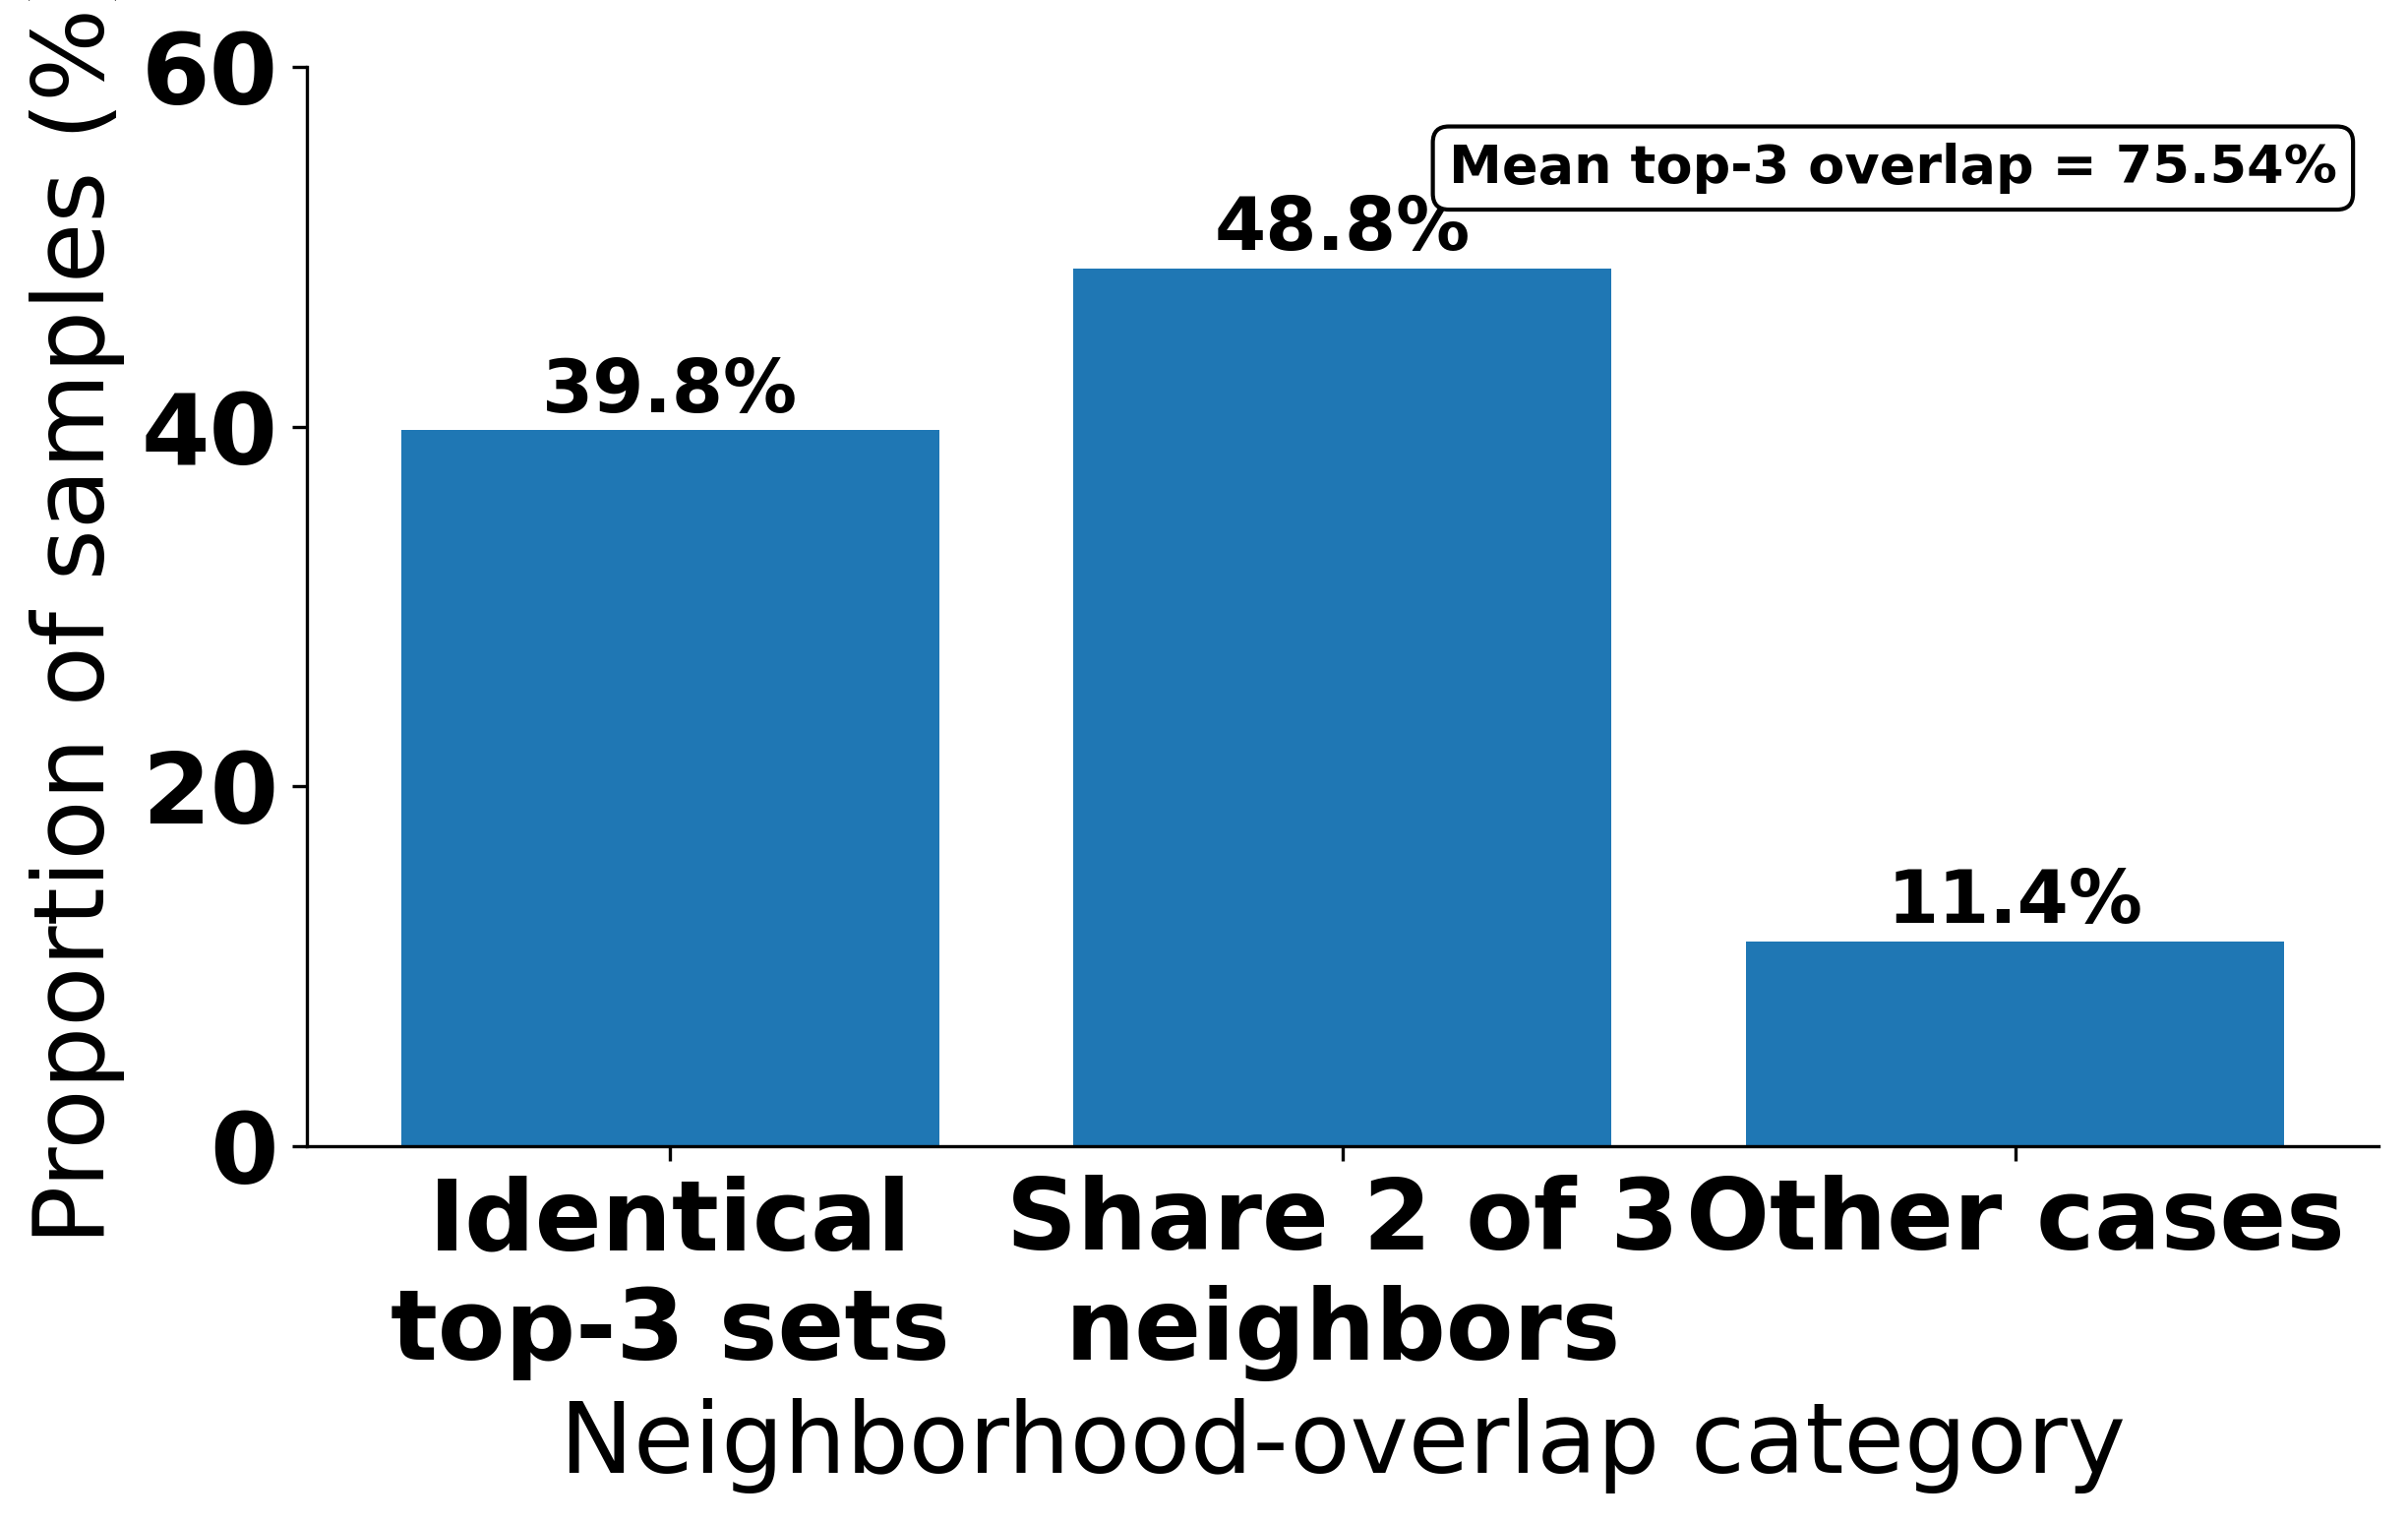

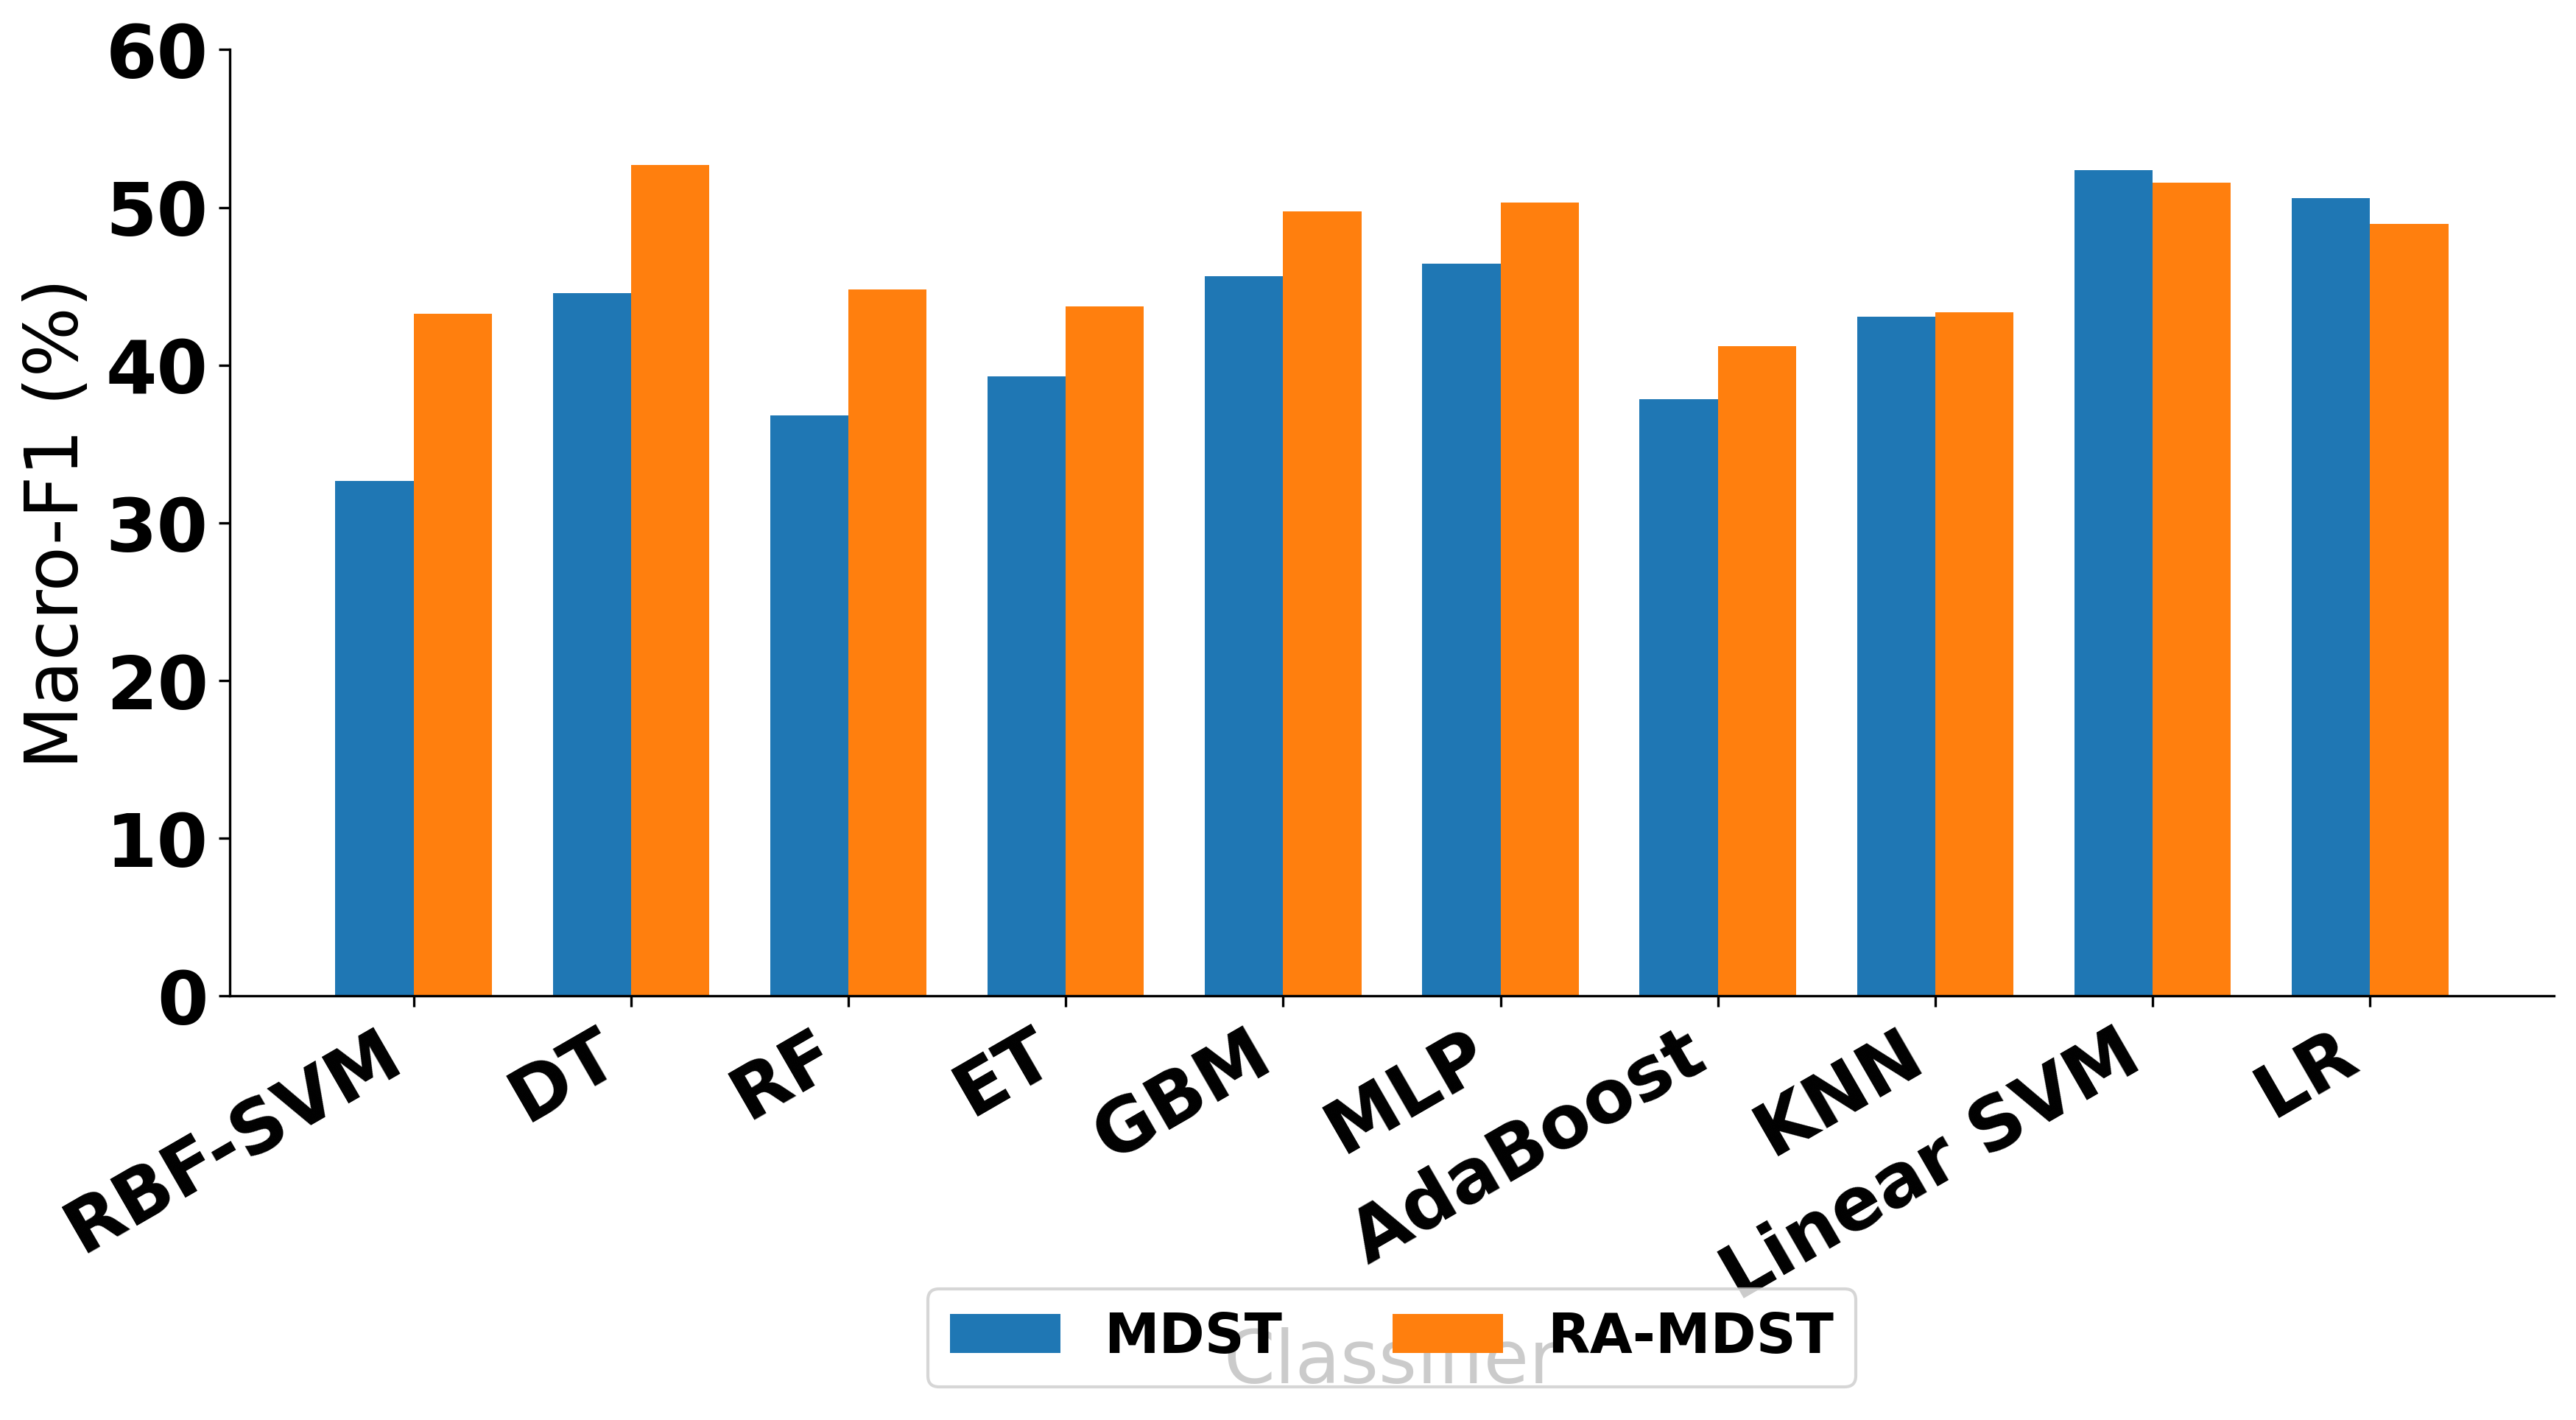

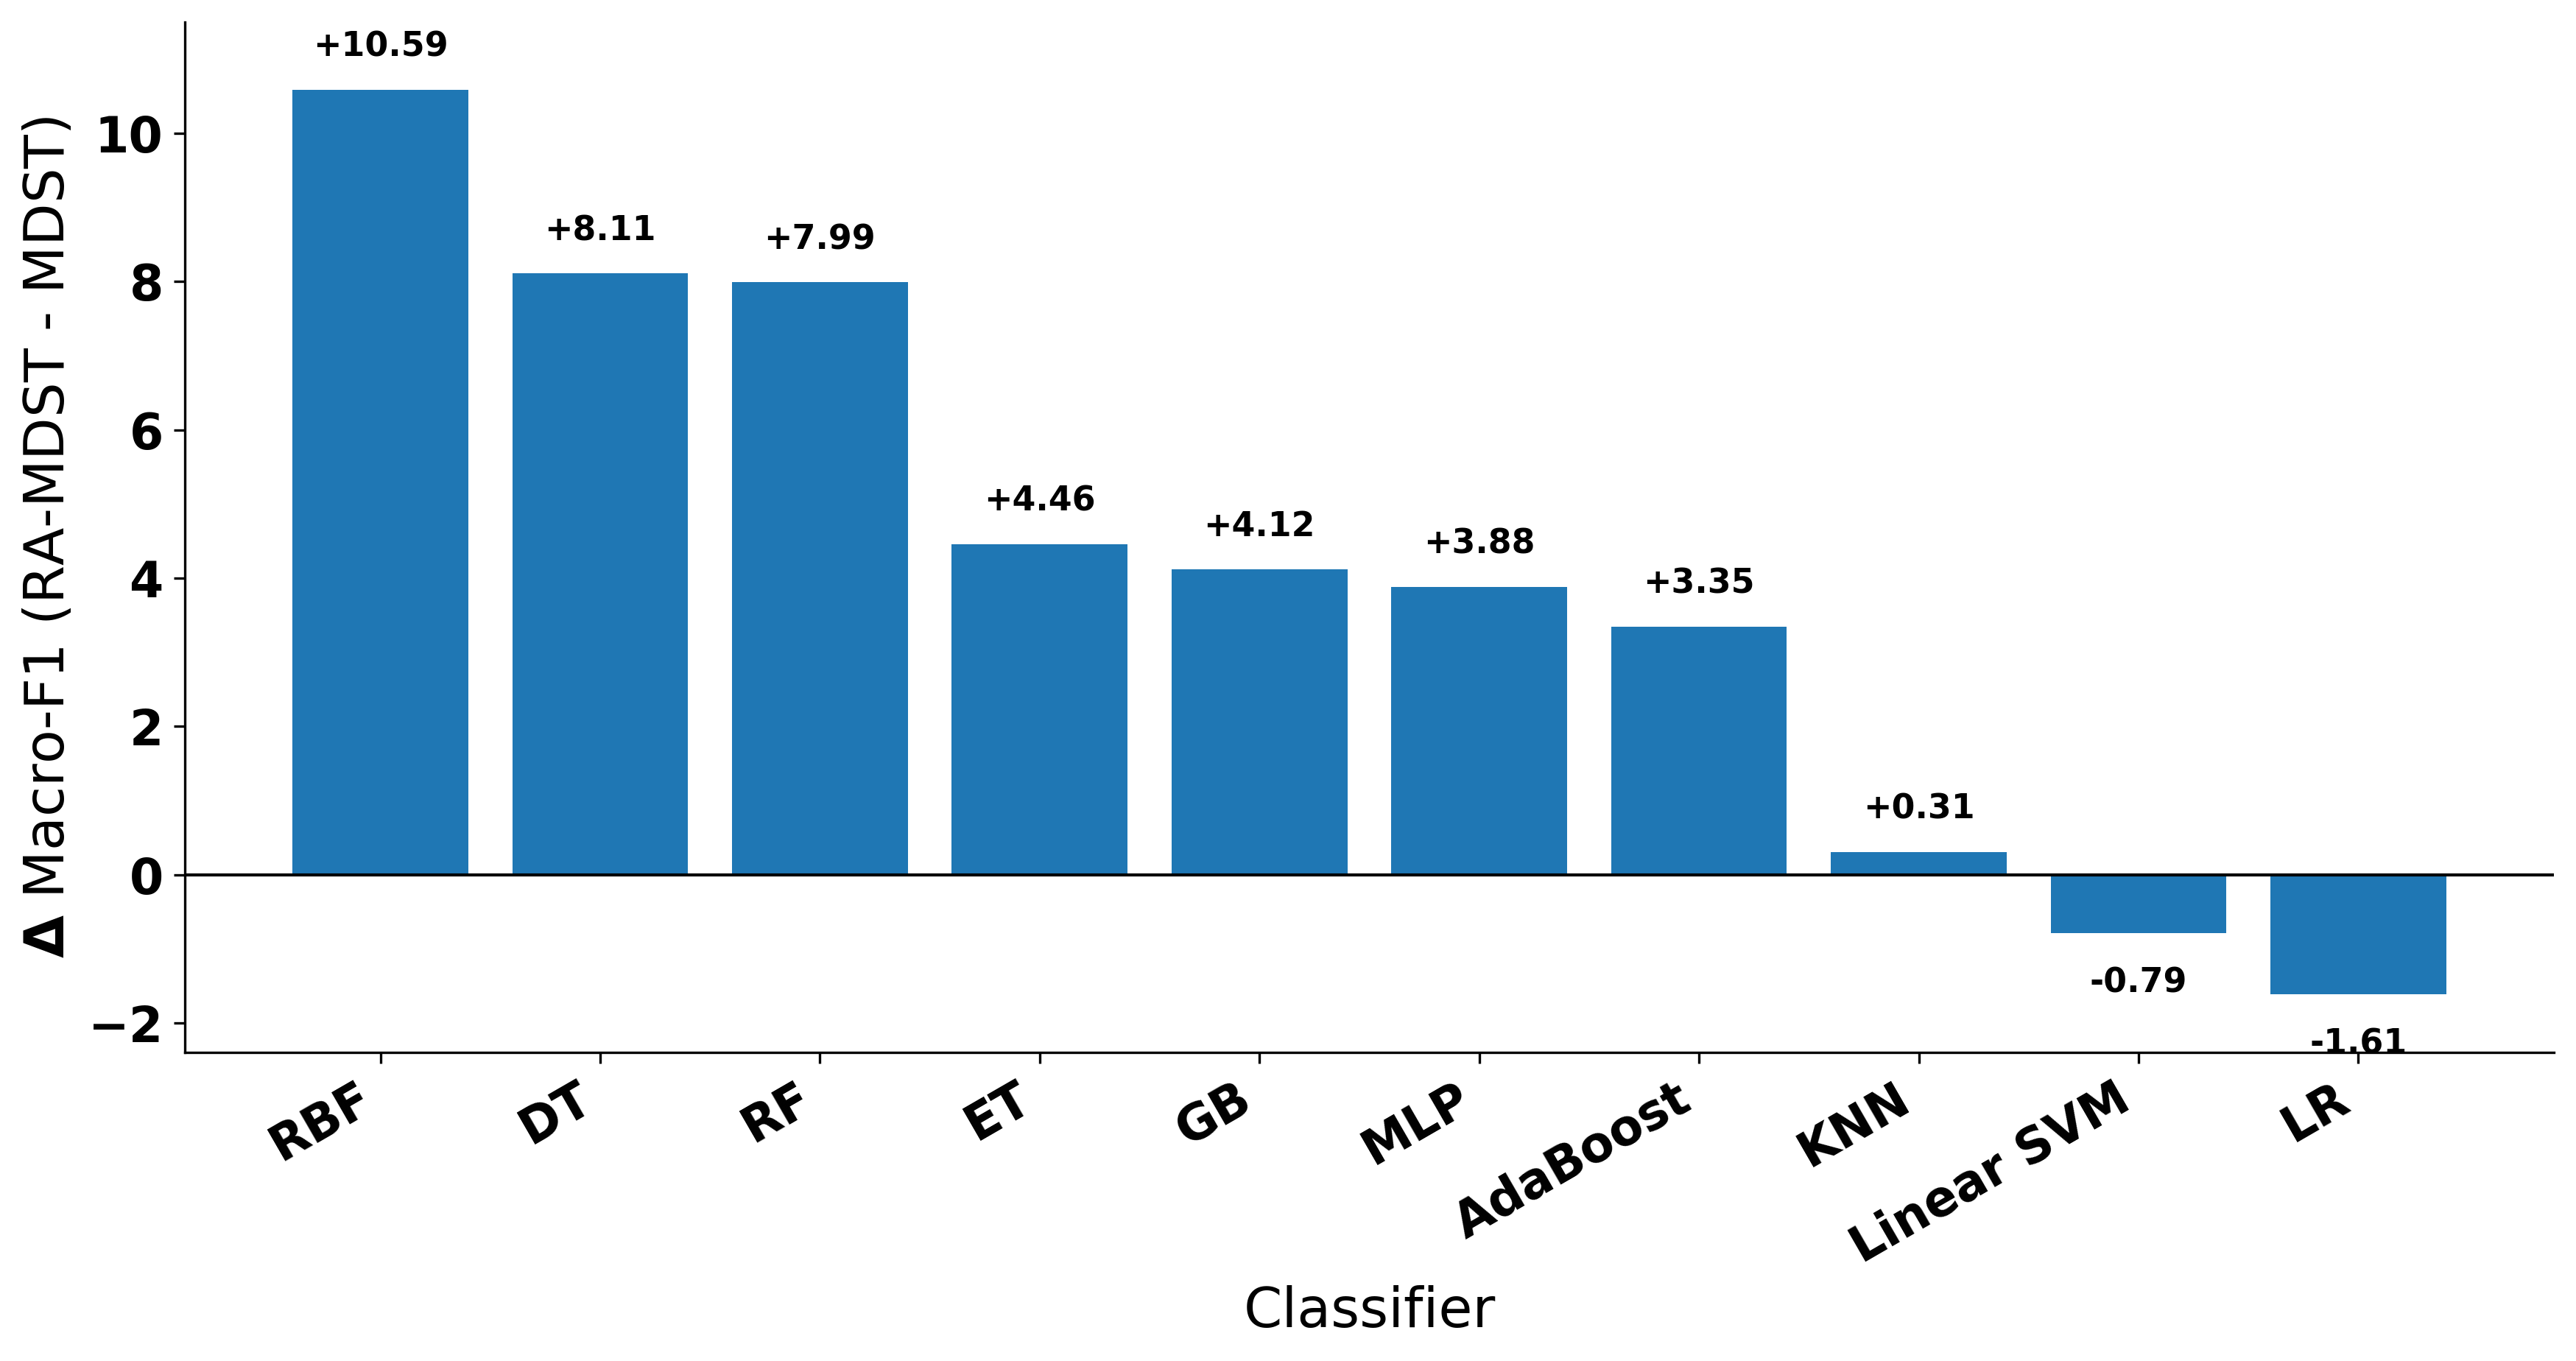

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Global settings
# ============================================================
AXIS_LABEL_SIZE = 24   # x/y axis label size
TICK_SIZE = 24         # x/y tick size
LEGEND_SIZE = 18
ANNOT_SIZE = 18
FIG_DPI = 300

plt.rcParams["font.family"] = "DejaVu Sans"


# ============================================================
# FIGURE 6
# Equal-budget comparison of reconstructed MDST and proposed RA-MDST
# ============================================================
def make_figure_6():
    methods = ["Reconstructed\nMDST", "Proposed\nRA-MDST"]
    accuracy = [90.01, 93.11]
    macro_f1 = [89.85, 92.92]
    bal_acc = [89.99, 93.09]

    x = np.arange(len(methods))
    width = 0.23

    fig, ax = plt.subplots(figsize=(8.5, 5.5))

    b1 = ax.bar(x - width, accuracy, width, label="Accuracy")
    b2 = ax.bar(x, macro_f1, width, label="Macro-F1")
    b3 = ax.bar(x + width, bal_acc, width, label="Balanced Accuracy")

    ax.set_xticks(x)
    ax.set_xticklabels(methods, fontsize=TICK_SIZE)
    ax.set_ylabel("Score (%)", fontsize=AXIS_LABEL_SIZE)
    # No title

    ax.set_ylim(85, 95)

    # Legend outside graph
    ax.legend(
        fontsize=LEGEND_SIZE,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=True
    )

    for bars in [b1, b2, b3]:
        for bar in bars:
            h = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2,
                h + 0.12,
                f"{h:.2f}",
                ha="center",
                va="bottom",
                fontsize=ANNOT_SIZE
            )

    ax.tick_params(axis='y', labelsize=TICK_SIZE)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.25)
    plt.savefig("Figure6_EqualBudget_MDST_vs_RAMDST.png", dpi=FIG_DPI, bbox_inches="tight")
    plt.savefig("Figure6_EqualBudget_MDST_vs_RAMDST.pdf", bbox_inches="tight")
    plt.show()


# ============================================================
# FIGURE 7
# Empirical neighborhood-overlap evidence motivating RA-MDST
# ============================================================
def make_figure_7():
    categories = [
        "Identical\ntop-3 sets",
        "Share 2 of 3\nneighbors",
        "Other cases"
    ]
    values = [39.8, 48.8, 11.4]

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    bars = ax.bar(categories, values)

    ax.set_ylabel("Proportion of samples (%)", fontsize=AXIS_LABEL_SIZE)
    ax.set_xlabel("Neighborhood-overlap category", fontsize=AXIS_LABEL_SIZE)
    # No title
    ax.set_ylim(0, 60)

    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 1.0,
            f"{h:.1f}%",
            ha="center",
            fontsize=ANNOT_SIZE
        )

    ax.text(
        0.98, 0.93,
        "Mean top-3 overlap = 75.54%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=13,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black")
    )

    ax.tick_params(axis='x', labelsize=TICK_SIZE)
    ax.tick_params(axis='y', labelsize=TICK_SIZE)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("Figure7_Neighborhood_Overlap_Evidence.png", dpi=FIG_DPI, bbox_inches="tight")
    plt.savefig("Figure7_Neighborhood_Overlap_Evidence.pdf", bbox_inches="tight")
    plt.show()


# ============================================================
# FIGURE 8
# Macro-F1 comparison between MDST and RA-MDST across ten classifiers
# ============================================================
def make_figure_8():
    classifiers = [
        "RBF-SVM", "DT", "RF", "ET",
        "GBM", "MLP", "AdaBoost", "KNN",
        "Linear SVM", "LR"
    ]

    mdst_f1 = [32.68, 44.57, 36.81, 39.27, 45.64, 46.45, 37.86, 43.05, 52.38, 50.57]
    ramdst_f1 = [43.27, 52.68, 44.80, 43.73, 49.76, 50.33, 41.21, 43.36, 51.59, 48.96]

    x = np.arange(len(classifiers))
    width = 0.36

    fig, ax = plt.subplots(figsize=(12, 6.5))

    ax.bar(x - width/2, mdst_f1, width, label="MDST")
    ax.bar(x + width/2, ramdst_f1, width, label="RA-MDST")

    ax.set_xticks(x)
    ax.set_xticklabels(classifiers, rotation=30, ha="right", fontsize=TICK_SIZE)
    ax.set_ylabel("Macro-F1 (%)", fontsize=AXIS_LABEL_SIZE)
    ax.set_xlabel("Classifier", fontsize=AXIS_LABEL_SIZE)
    # No title
    ax.set_ylim(0, 60)

    # Legend outside graph
    ax.legend(
        fontsize=LEGEND_SIZE,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.28),
        ncol=2,
        frameon=True
    )

    ax.tick_params(axis='y', labelsize=TICK_SIZE)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.28)
    plt.savefig("Figure8_MacroF1_Comparison_All_Classifiers.png", dpi=FIG_DPI, bbox_inches="tight")
    plt.savefig("Figure8_MacroF1_Comparison_All_Classifiers.pdf", bbox_inches="tight")
    plt.show()


# ============================================================
# FIGURE 9
# Change in Macro-F1 after replacing MDST with RA-MDST
# ============================================================
def make_figure_9():
    import numpy as np
    import matplotlib.pyplot as plt

    # Abbreviated classifier names
    classifiers = [
        "RBF", "DT", "RF", "ET",
        "GB", "MLP", "AdaBoost", "KNN",
        "Linear SVM", "LR"
    ]

    mdst_f1 = np.array([32.68, 44.57, 36.81, 39.27, 45.64, 46.45, 37.86, 43.05, 52.38, 50.57])
    ramdst_f1 = np.array([43.27, 52.68, 44.80, 43.73, 49.76, 50.33, 41.21, 43.36, 51.59, 48.96])
    delta = ramdst_f1 - mdst_f1

    x = np.arange(len(classifiers))

    fig, ax = plt.subplots(figsize=(12, 6.5))
    bars = ax.bar(classifiers, delta)

    ax.axhline(0, color="black", linewidth=1)
    ax.set_ylabel(r"$\Delta$ Macro-F1 (RA-MDST - MDST)", fontsize=18)
    ax.set_xlabel("Classifier", fontsize=18)

    ax.set_xticks(x)
    ax.set_xticklabels(classifiers, rotation=30, ha="right", fontsize=16)
    ax.tick_params(axis='y', labelsize=16)

    # Give extra lower margin so negative labels do not touch the line/bottom
    ax.set_ylim(-2.4, 11.5)

    for bar, val in zip(bars, delta):
        y = bar.get_height()

        if y >= 0:
            ypos = y + 0.35
            va = "bottom"
        else:
            ypos = y - 0.45   # more gap for negative bars
            va = "top"

        ax.text(
            bar.get_x() + bar.get_width()/2,
            ypos,
            f"{val:+.2f}",
            ha="center",
            va=va,
            fontsize=11
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("Figure9_MacroF1_Change_RAMDST_minus_MDST.png", dpi=300, bbox_inches="tight")
    plt.savefig("Figure9_MacroF1_Change_RAMDST_minus_MDST.pdf", bbox_inches="tight")
    plt.show()


# ============================================================
# Run all figures
# ============================================================
if __name__ == "__main__":
    make_figure_6()
    make_figure_7()
    make_figure_8()
    make_figure_9()

In [20]:
# ============================================================
# PAPER-READY ADDITIONAL ANALYSIS
# 1. MDST vs RA-MDST confusion matrices
# 2. ROC curves
# 3. Precision-Recall curves
# 4. Computational-time comparison
#
# Protocol B:
# Train fold -> Scaling -> RFE -> Oversampling -> SVM
# -> untouched real test fold
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------
CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Paper names
METHODS = {
    "MDST": "MDST",
    "RA-DI-MDST": "RA-MDST"
}

classes = np.sort(np.unique(y))
n_classes = len(classes)

# Change only if you want different display names
CLASS_NAMES = [
    "Minor",
    "Moderate",
    "None"
]

results = {}

# ------------------------------------------------------------
# STRICT FOLD-INTERNAL EVALUATION
# ------------------------------------------------------------
for sampler_internal, sampler_display in METHODS.items():

    print("\nRunning:", sampler_display)

    y_true_all = []
    y_pred_all = []
    score_all = []

    sampling_times = []
    training_times = []
    prediction_times = []
    total_times = []

    fold_metrics = []

    for fold, (train_idx, test_idx) in enumerate(
        CV.split(X_df, y),
        start=1
    ):

        fold_start = time.perf_counter()

        # ----------------------------------------
        # Real train/test split
        # ----------------------------------------
        X_train_raw = X_df.iloc[train_idx].to_numpy(dtype=float)
        X_test_raw  = X_df.iloc[test_idx].to_numpy(dtype=float)

        y_train = y[train_idx]
        y_test  = y[test_idx]

        # ----------------------------------------
        # Fold-internal scaling + RFE
        # ----------------------------------------
        X_train, X_test, selector, scaler = fit_transform_rfe(
            X_train_raw,
            y_train,
            X_test_raw,
            n_features=N_RFE_FEATURES,
            seed=42 + fold
        )

        # ----------------------------------------
        # Oversampling time
        # ----------------------------------------
        t0 = time.perf_counter()

        X_aug, y_aug, diag = apply_sampler(
            sampler_internal,
            X_train,
            y_train,
            seed=42 + fold
        )

        sampling_time = time.perf_counter() - t0

        # ----------------------------------------
        # Linear SVM
        #
        # probability=False avoids expensive
        # Platt calibration. decision_function
        # scores are sufficient for ROC and PR.
        # ----------------------------------------
        model = SVC(
            kernel="linear",
            C=1.0,
            decision_function_shape="ovr",
            probability=False,
            random_state=42 + fold
        )

        # Training time
        t1 = time.perf_counter()
        model.fit(X_aug, y_aug)
        training_time = time.perf_counter() - t1

        # Prediction time
        t2 = time.perf_counter()

        pred = model.predict(X_test)
        scores = model.decision_function(X_test)

        prediction_time = time.perf_counter() - t2

        total_time = time.perf_counter() - fold_start

        # ----------------------------------------
        # Store OOF results
        # ----------------------------------------
        y_true_all.extend(y_test)
        y_pred_all.extend(pred)
        score_all.append(scores)

        sampling_times.append(sampling_time)
        training_times.append(training_time)
        prediction_times.append(prediction_time)
        total_times.append(total_time)

        fold_metrics.append({
            "fold": fold,
            "accuracy": accuracy_score(y_test, pred),
            "macro_f1": f1_score(
                y_test,
                pred,
                average="macro"
            ),
            "balanced_accuracy":
                balanced_accuracy_score(
                    y_test,
                    pred
                )
        })

        print(
            f"Fold {fold}: "
            f"Sampling={sampling_time:.4f}s | "
            f"Training={training_time:.4f}s | "
            f"Prediction={prediction_time:.4f}s"
        )

    # Convert to arrays
    y_true_all = np.asarray(y_true_all)
    y_pred_all = np.asarray(y_pred_all)
    score_all = np.vstack(score_all)

    results[sampler_display] = {
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "scores": score_all,
        "sampling_time": np.asarray(sampling_times),
        "training_time": np.asarray(training_times),
        "prediction_time": np.asarray(prediction_times),
        "total_time": np.asarray(total_times),
        "fold_metrics": pd.DataFrame(fold_metrics)
    }

print("\nAll evaluations completed.")


Running: MDST
Fold 1: Sampling=0.0166s | Training=0.0142s | Prediction=0.0013s
Fold 2: Sampling=0.0170s | Training=0.0192s | Prediction=0.0014s
Fold 3: Sampling=0.0165s | Training=0.0123s | Prediction=0.0013s
Fold 4: Sampling=0.0175s | Training=0.0171s | Prediction=0.0013s
Fold 5: Sampling=0.0187s | Training=0.0146s | Prediction=0.0014s

Running: RA-MDST
Fold 1: Sampling=0.0188s | Training=0.0267s | Prediction=0.0017s
Fold 2: Sampling=0.0193s | Training=0.0252s | Prediction=0.0017s
Fold 3: Sampling=0.0190s | Training=0.0154s | Prediction=0.0018s
Fold 4: Sampling=0.0198s | Training=0.0196s | Prediction=0.0020s
Fold 5: Sampling=0.0178s | Training=0.0134s | Prediction=0.0019s

All evaluations completed.


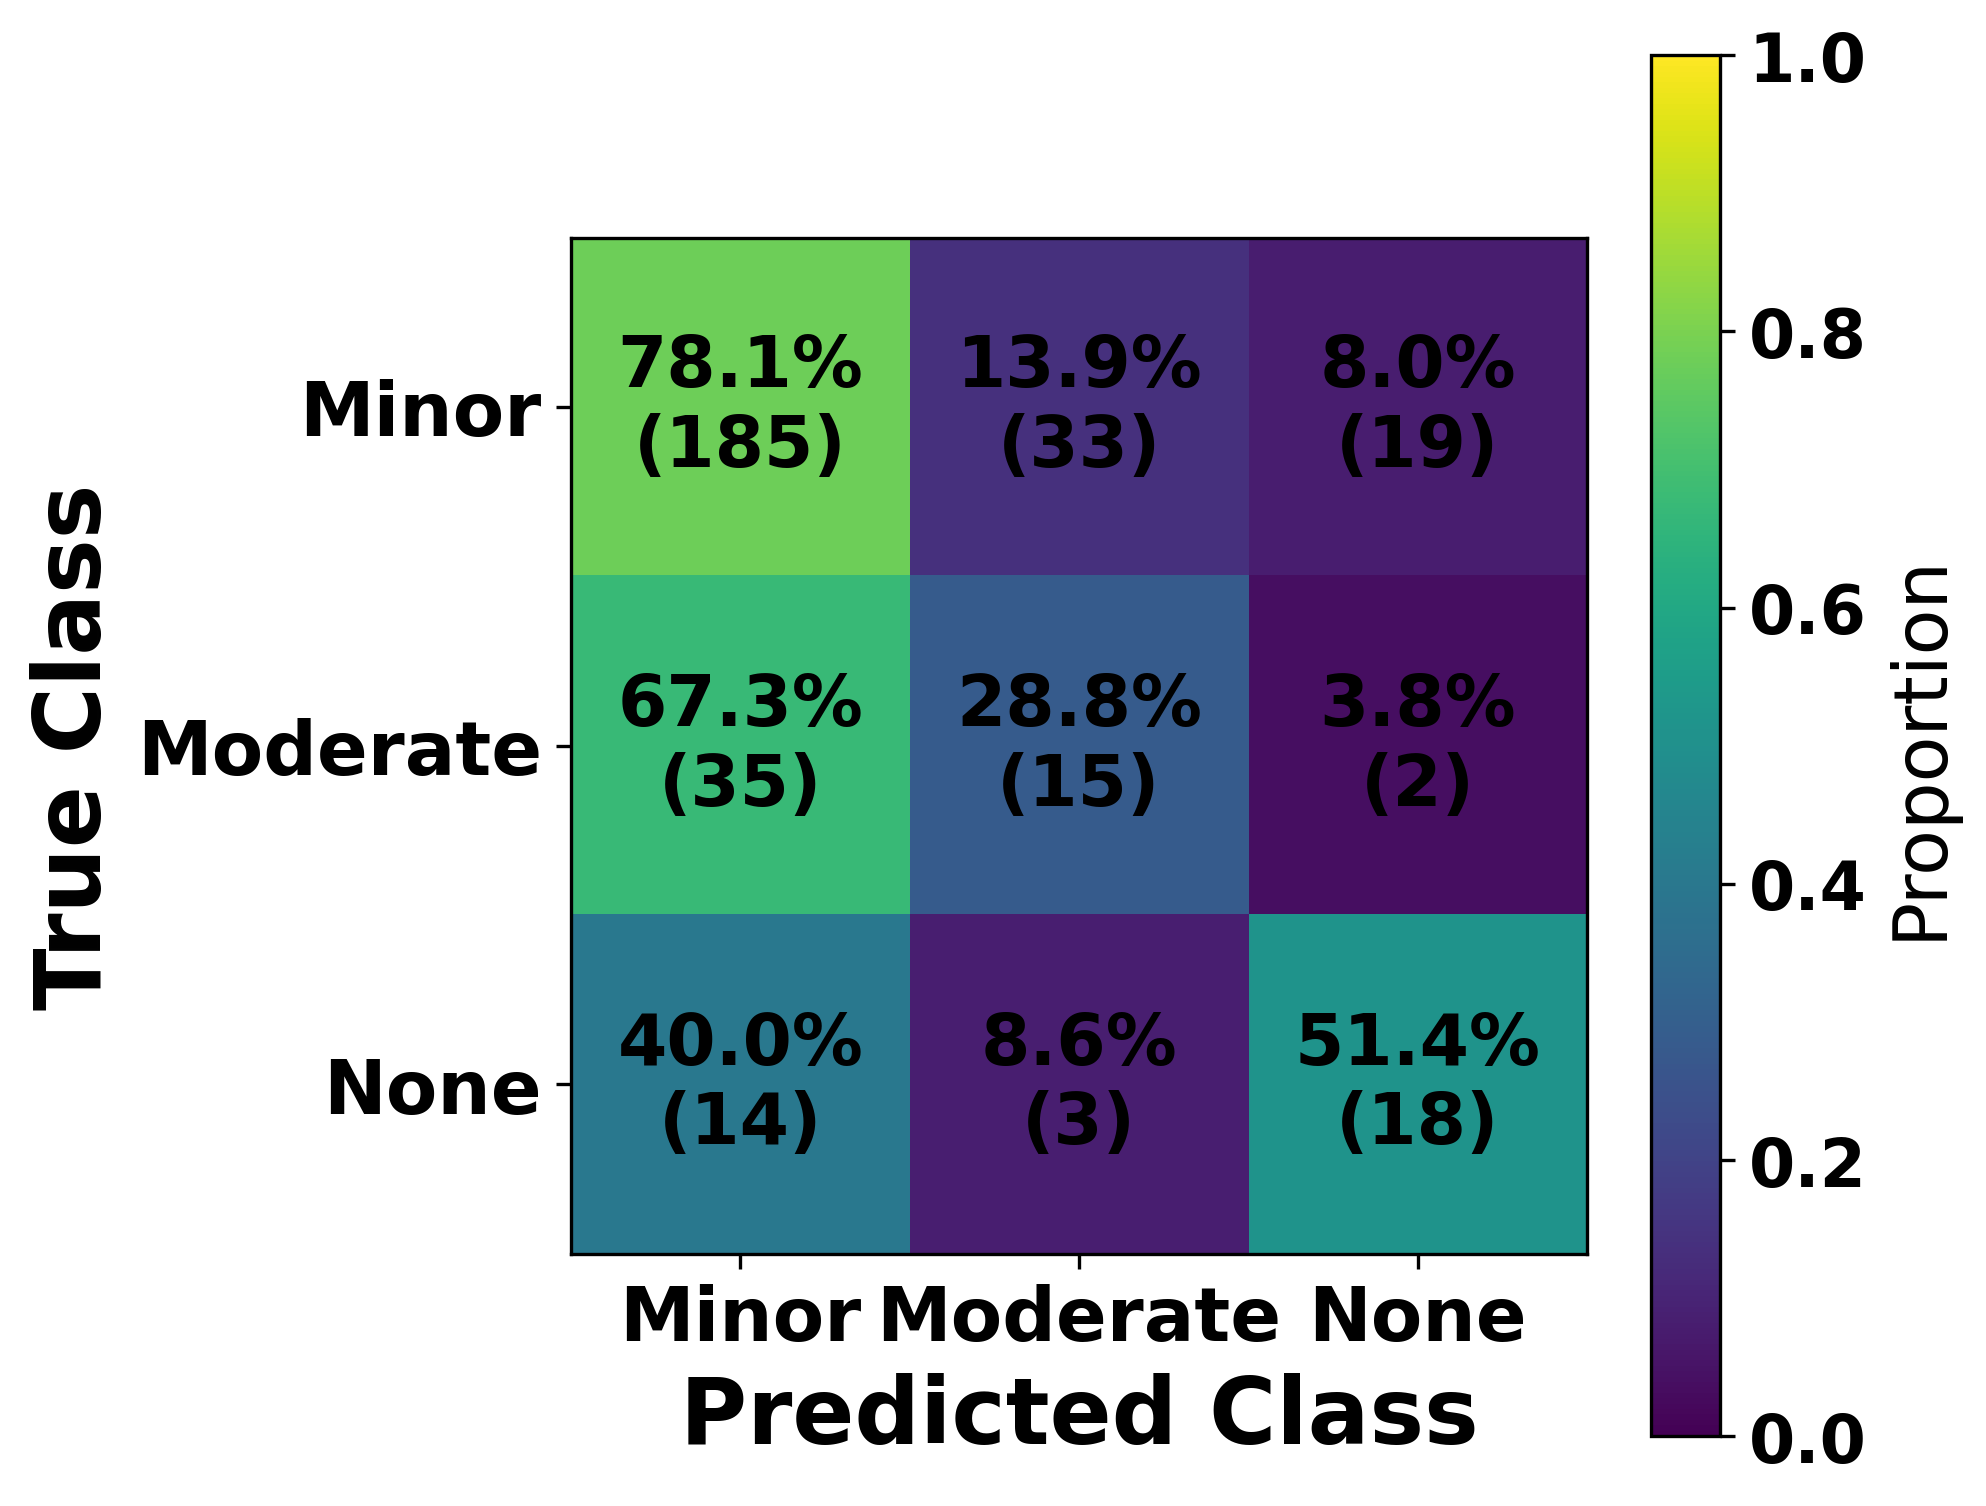

Saved: Fig_Confusion_Matrix_MDST.png


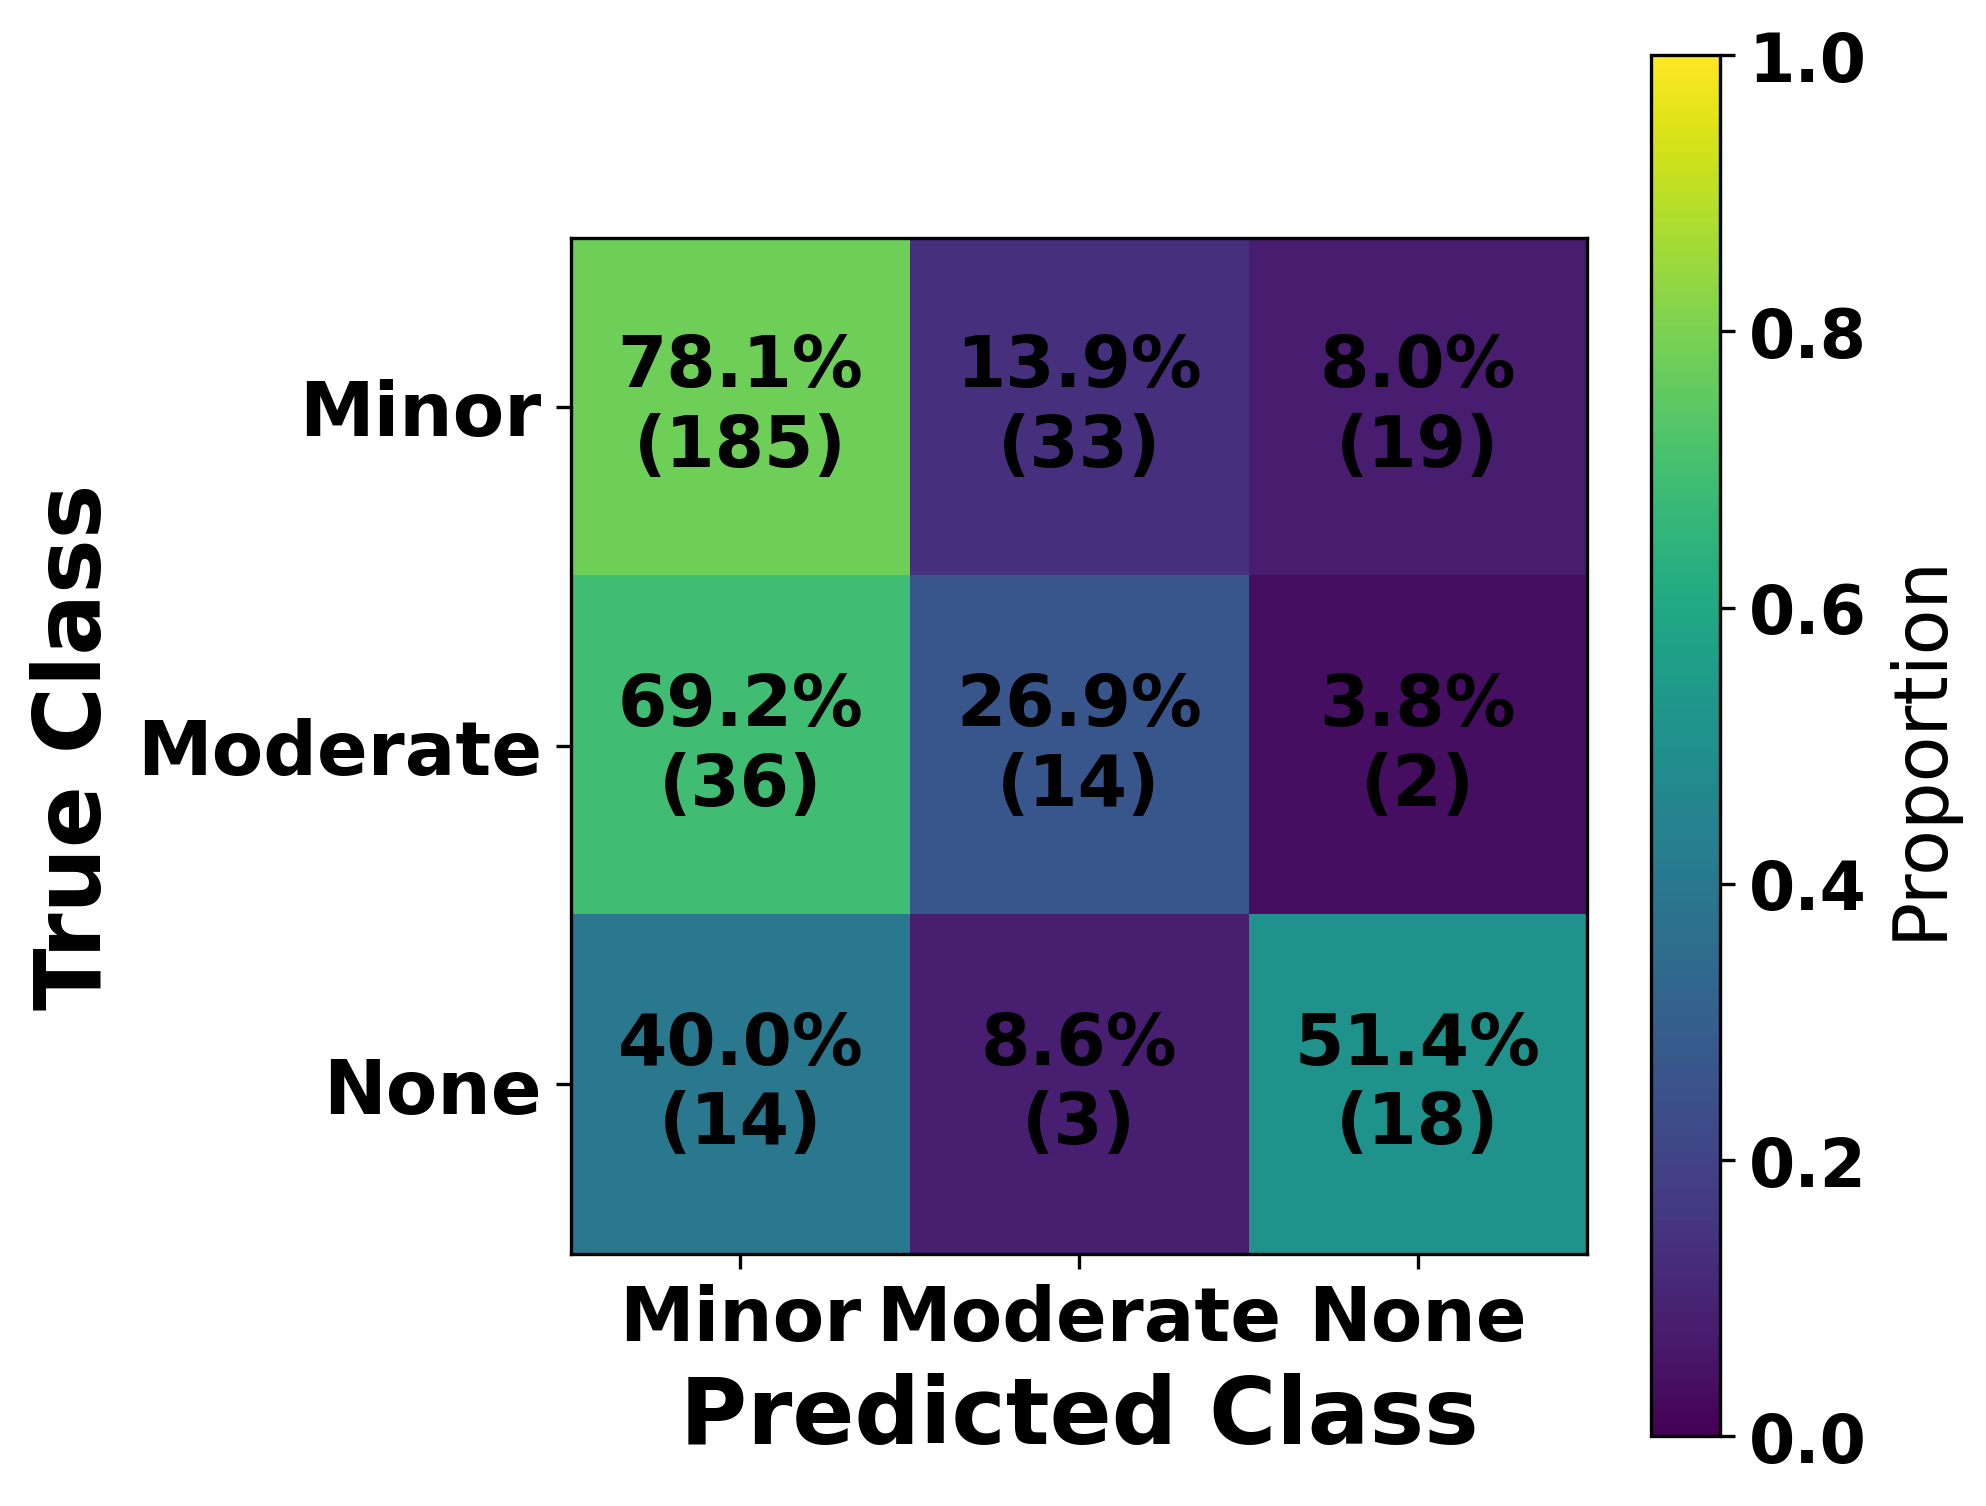

Saved: Fig_Confusion_Matrix_RA_MDST.png


In [21]:
# ============================================================
# FIGURE: NORMALIZED CONFUSION MATRICES
# ============================================================

for method in ["MDST", "RA-MDST"]:

    y_true = results[method]["y_true"]
    y_pred = results[method]["y_pred"]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes
    )

    # Row normalization = recall for each true class
    cm_norm = cm.astype(float) / cm.sum(
        axis=1,
        keepdims=True
    )

    fig, ax = plt.subplots(figsize=(6.8, 5.8))

    im = ax.imshow(
        cm_norm,
        vmin=0,
        vmax=1
    )

    # Large paper-ready fonts
    ax.set_xlabel(
        "Predicted Class",
        fontsize=22,
        fontweight="bold"
    )

    ax.set_ylabel(
        "True Class",
        fontsize=22,
        fontweight="bold"
    )

    ax.set_xticks(range(n_classes))
    ax.set_yticks(range(n_classes))

    ax.set_xticklabels(
        CLASS_NAMES,
        fontsize=18
    )

    ax.set_yticklabels(
        CLASS_NAMES,
        fontsize=18
    )

    # Show normalized % + raw count
    for i in range(n_classes):
        for j in range(n_classes):

            txt = (
                f"{cm_norm[i,j]*100:.1f}%\n"
                f"({cm[i,j]})"
            )

            ax.text(
                j,
                i,
                txt,
                ha="center",
                va="center",
                fontsize=17,
                fontweight="bold"
            )

    cbar = fig.colorbar(im, ax=ax)

    cbar.ax.tick_params(
        labelsize=16
    )

    cbar.set_label(
        "Proportion",
        fontsize=18
    )

    plt.tight_layout()

    fname = (
        f"Fig_Confusion_Matrix_"
        f"{method.replace('-', '_')}.png"
    )

    plt.savefig(
        fname,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", fname)

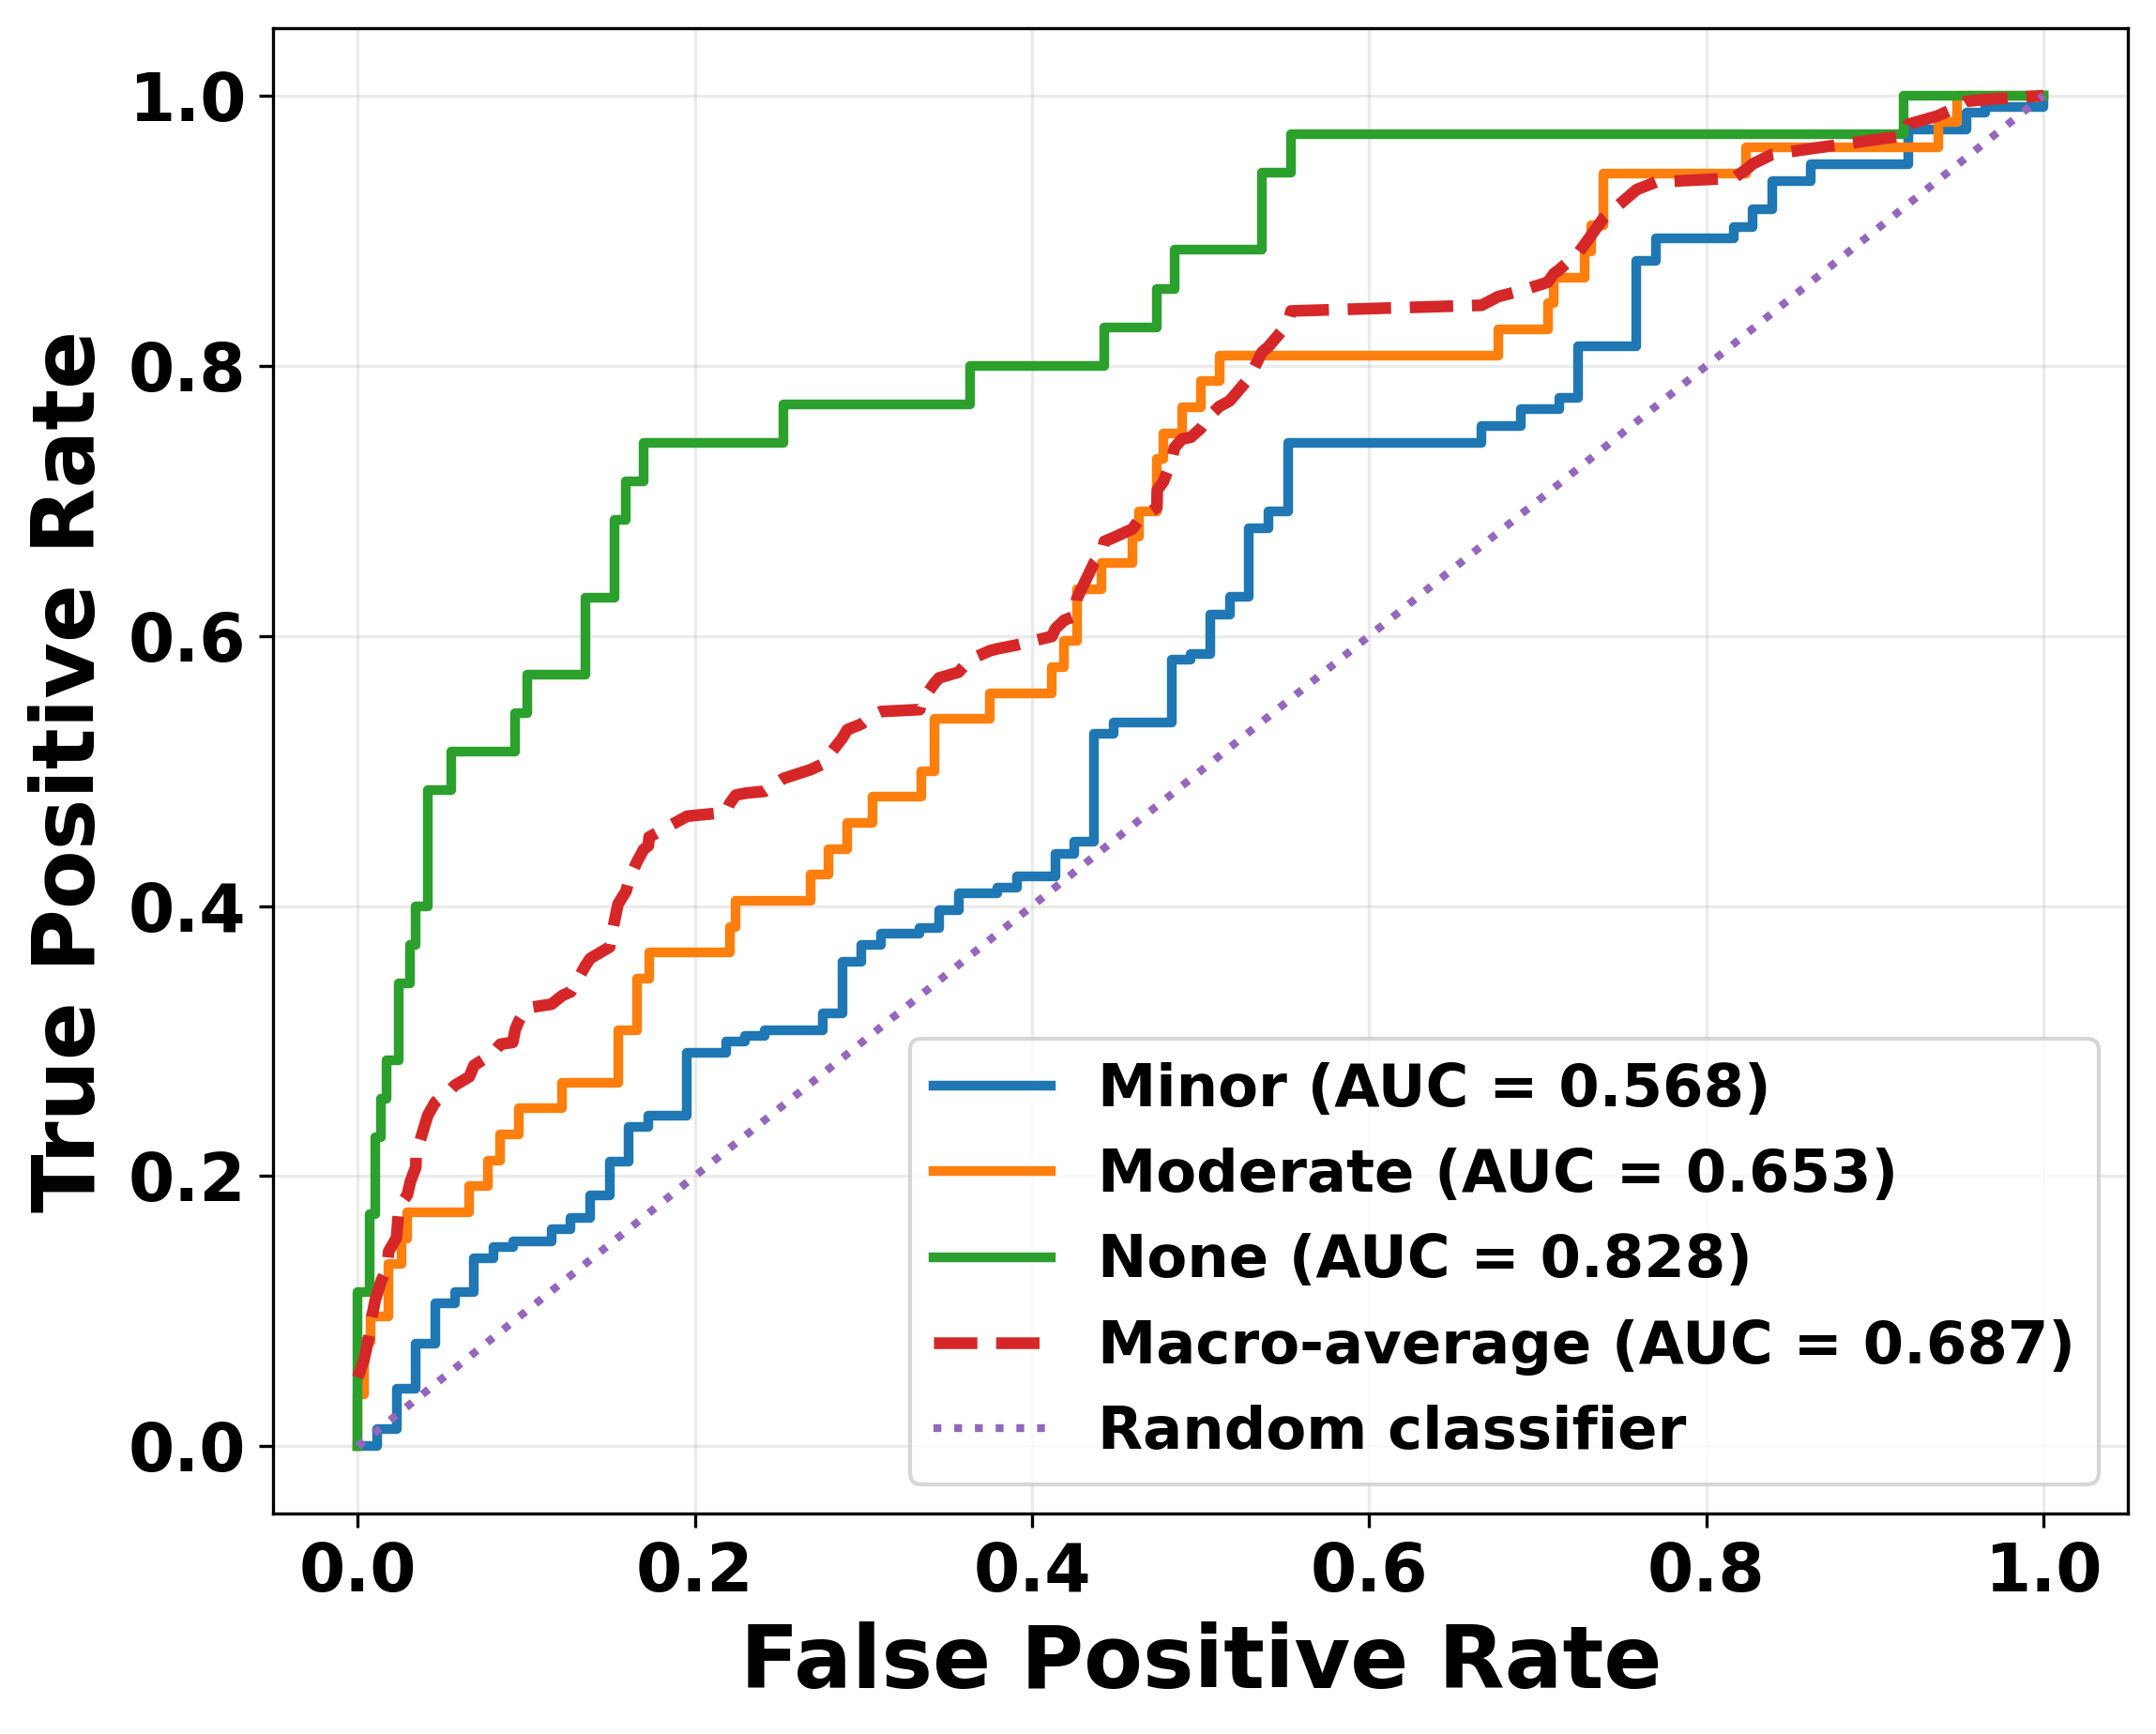


Class-wise ROC-AUC:
Minor: 0.5684
Moderate: 0.6527
None: 0.8281
Macro-average ROC-AUC: 0.6867


In [22]:
# ============================================================
# FIGURE: MULTICLASS ROC CURVES FOR RA-MDST
# ============================================================

method = "RA-MDST"

y_true = results[method]["y_true"]
scores = results[method]["scores"]

# One-hot encode true labels
y_bin = label_binarize(
    y_true,
    classes=classes
)

fig, ax = plt.subplots(figsize=(8, 6.5))

roc_auc_values = {}

for i, class_name in enumerate(CLASS_NAMES):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        scores[:, i]
    )

    roc_auc = auc(fpr, tpr)

    roc_auc_values[class_name] = roc_auc

    ax.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Macro-average ROC
all_fpr = np.unique(
    np.concatenate([
        roc_curve(
            y_bin[:, i],
            scores[:, i]
        )[0]
        for i in range(n_classes)
    ])
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        scores[:, i]
    )

    mean_tpr += np.interp(
        all_fpr,
        fpr,
        tpr
    )

mean_tpr /= n_classes

macro_auc = auc(
    all_fpr,
    mean_tpr
)

ax.plot(
    all_fpr,
    mean_tpr,
    linewidth=3,
    linestyle="--",
    label=f"Macro-average (AUC = {macro_auc:.3f})"
)

# Random-classification line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    linewidth=2,
    label="Random classifier"
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=22,
    fontweight="bold"
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=22,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=17
)

ax.legend(
    fontsize=15,
    loc="lower right"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Fig_RA_MDST_ROC_Curve.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nClass-wise ROC-AUC:")
for k, v in roc_auc_values.items():
    print(f"{k}: {v:.4f}")

print(
    f"Macro-average ROC-AUC: {macro_auc:.4f}"
)

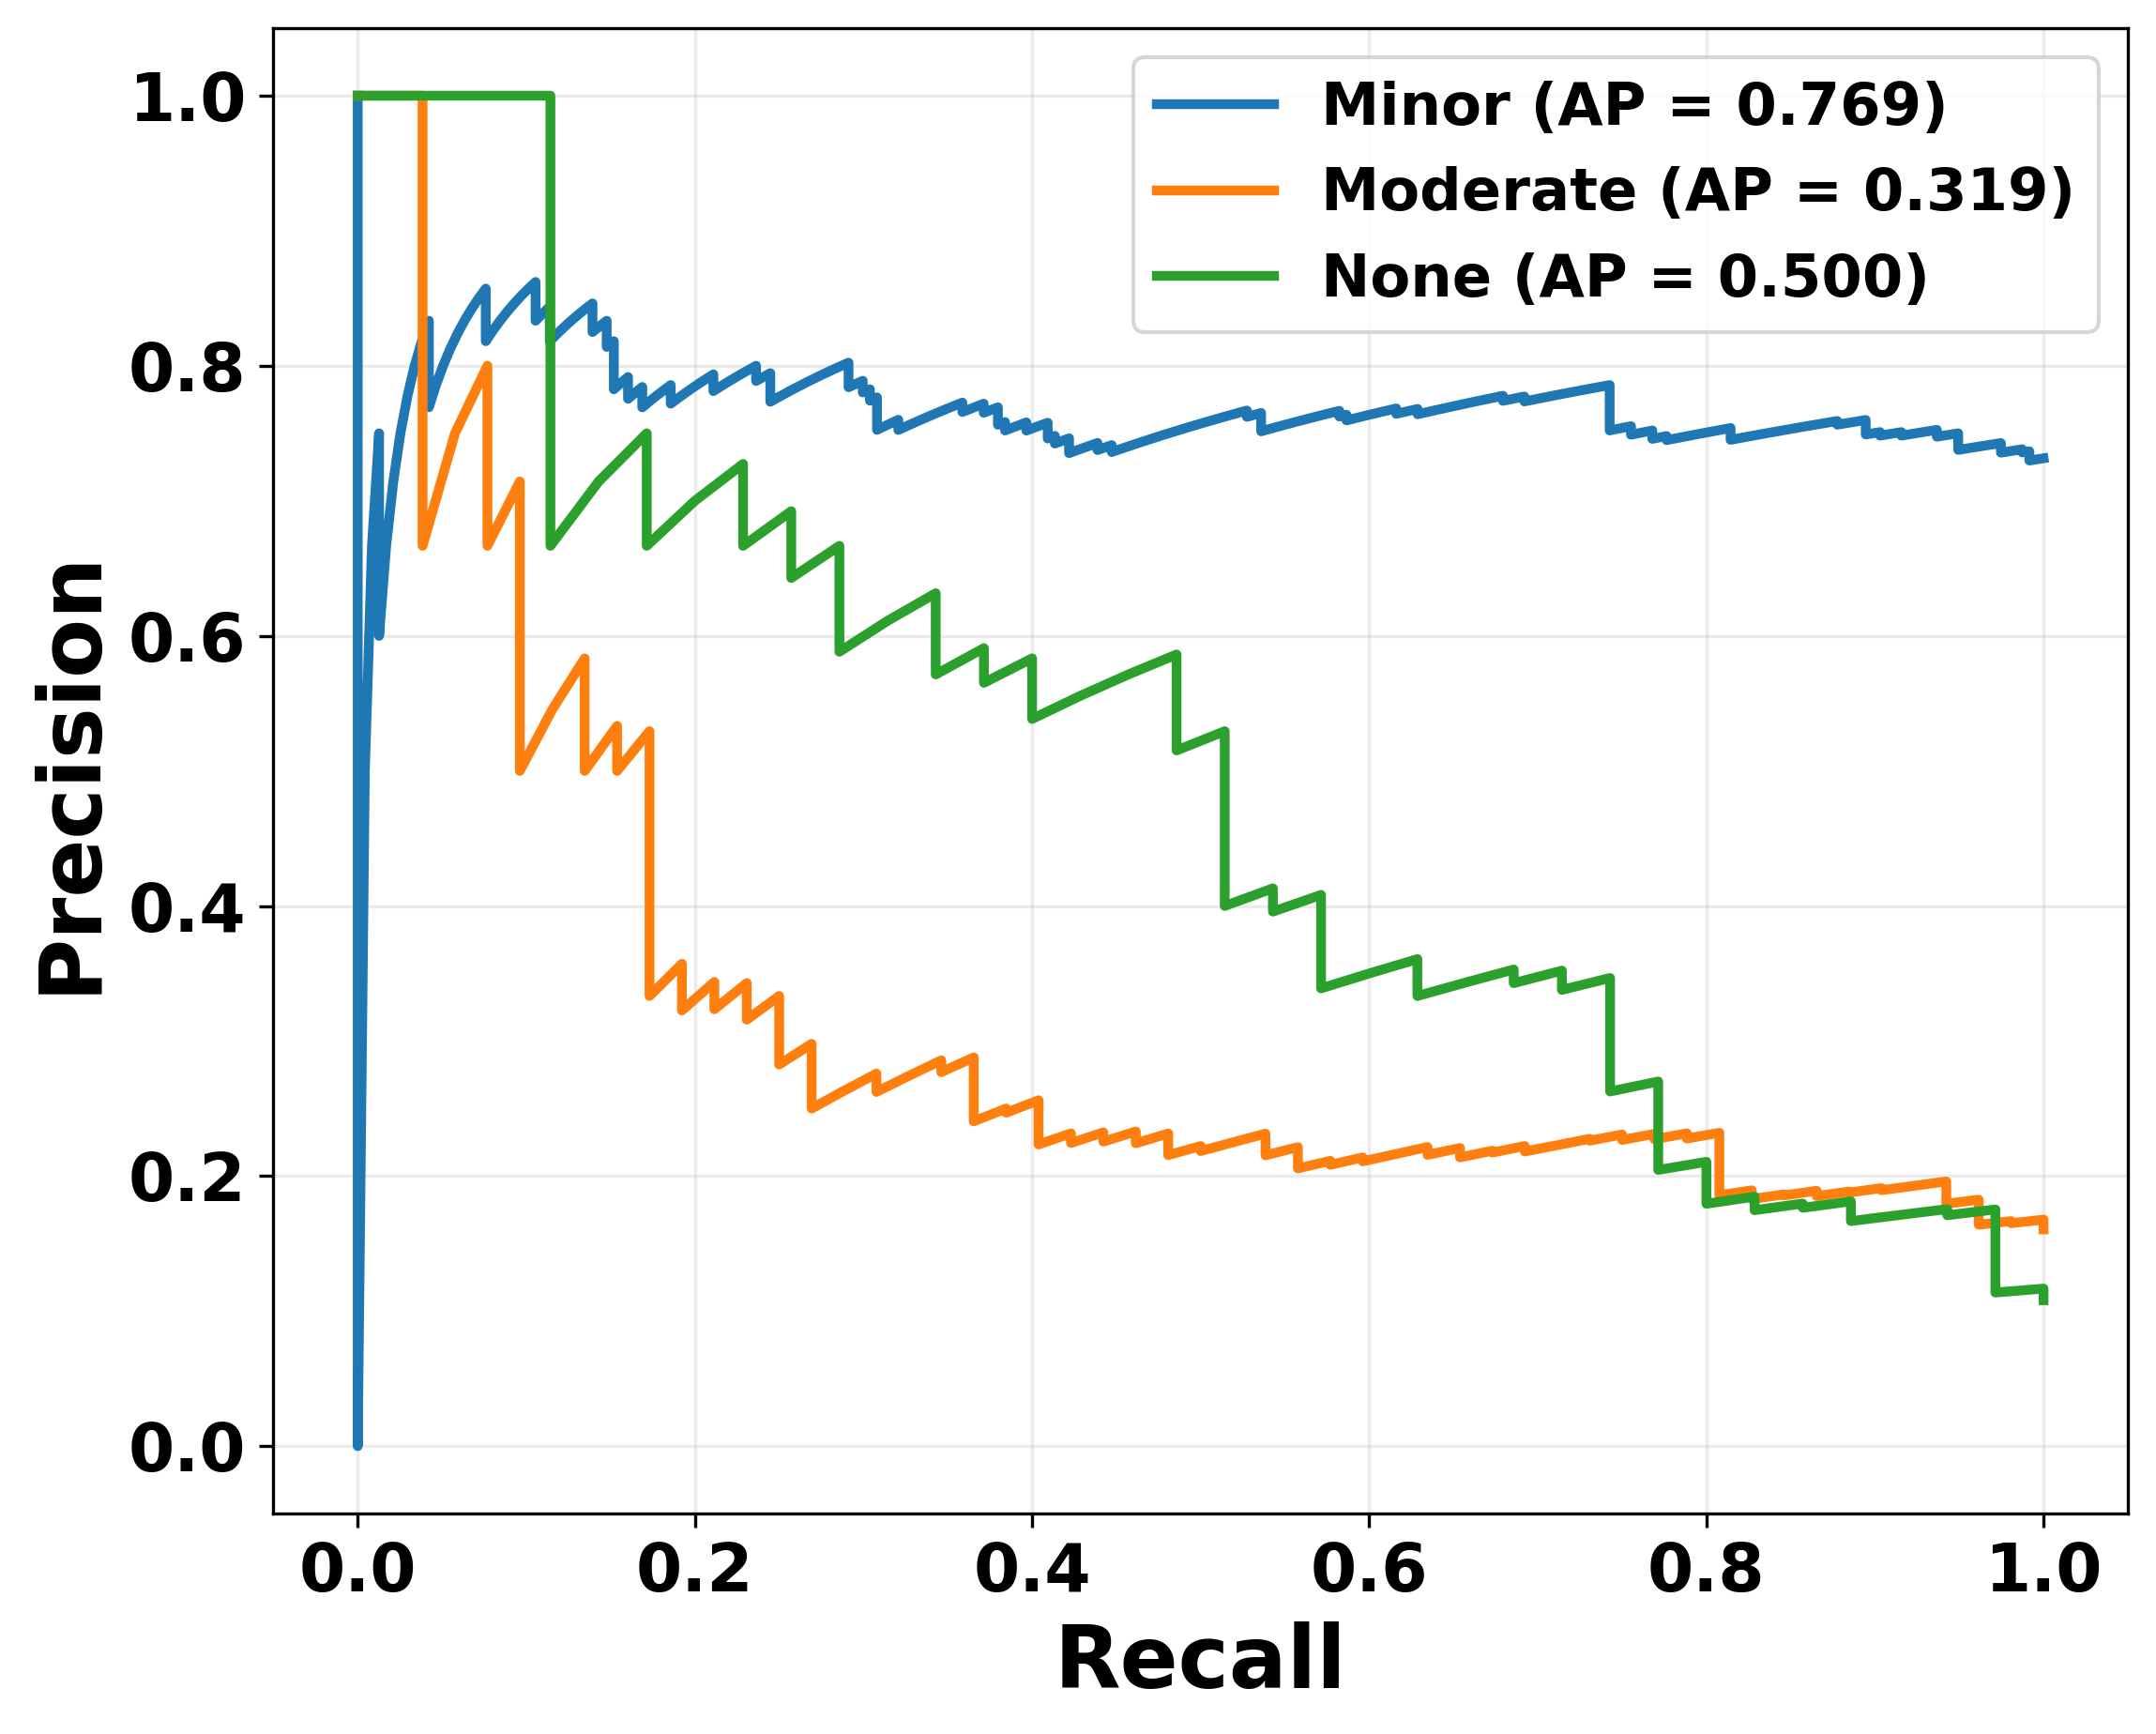

Macro Average Precision = 0.5296


In [23]:
# ============================================================
# FIGURE: PRECISION-RECALL CURVES FOR RA-MDST
# ============================================================

method = "RA-MDST"

y_true = results[method]["y_true"]
scores = results[method]["scores"]

y_bin = label_binarize(
    y_true,
    classes=classes
)

fig, ax = plt.subplots(figsize=(8, 6.5))

ap_values = []

for i, class_name in enumerate(CLASS_NAMES):

    precision, recall, _ = precision_recall_curve(
        y_bin[:, i],
        scores[:, i]
    )

    ap = average_precision_score(
        y_bin[:, i],
        scores[:, i]
    )

    ap_values.append(ap)

    ax.plot(
        recall,
        precision,
        linewidth=2.5,
        label=f"{class_name} (AP = {ap:.3f})"
    )

macro_ap = np.mean(ap_values)

ax.set_xlabel(
    "Recall",
    fontsize=22,
    fontweight="bold"
)

ax.set_ylabel(
    "Precision",
    fontsize=22,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=17
)

ax.legend(
    fontsize=15,
    loc="best"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Fig_RA_MDST_Precision_Recall_Curve.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    f"Macro Average Precision = {macro_ap:.4f}"
)

,Method,Sampling Time,Training Time,Prediction Time,Total Fold Time
0,MDST,0.01727,0.01548,0.00134,3.33088
1,RA-MDST,0.01895,0.02002,0.00181,3.35419


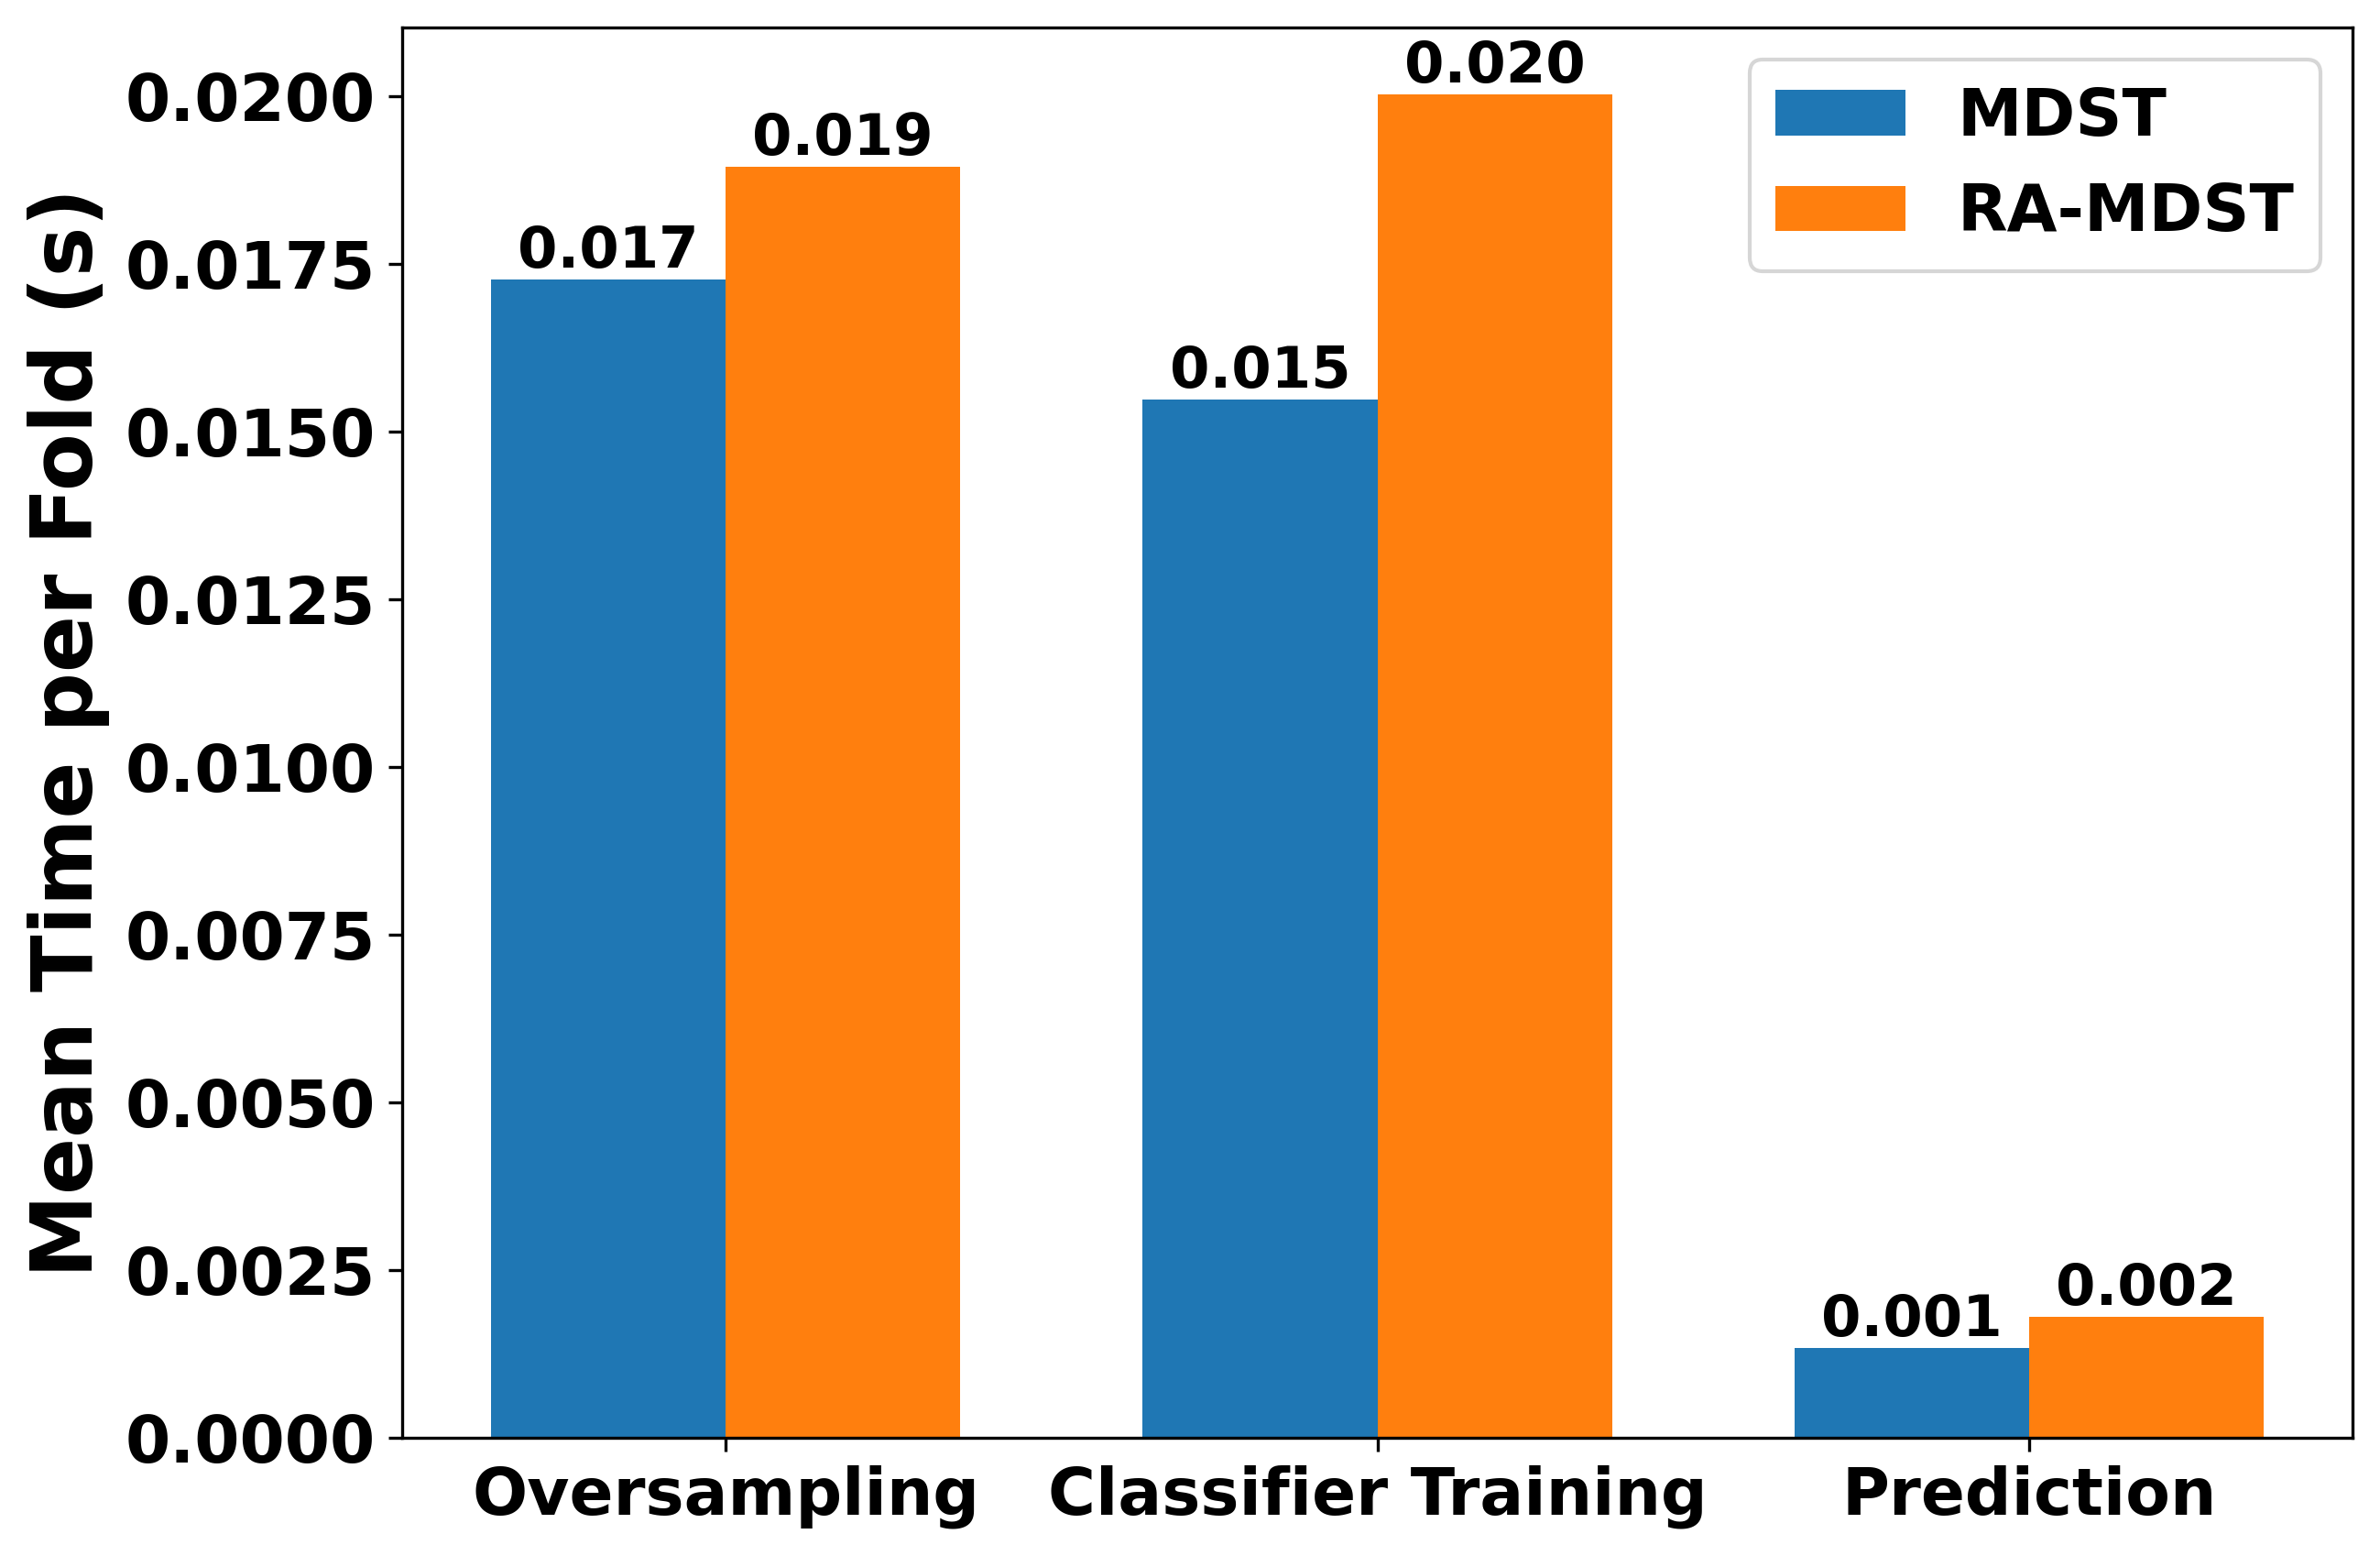

In [24]:
# ============================================================
# FIGURE: COMPUTATIONAL COST
# ============================================================

time_rows = []

for method in ["MDST", "RA-MDST"]:

    r = results[method]

    time_rows.append({
        "Method": method,

        "Sampling Time":
            np.mean(r["sampling_time"]),

        "Training Time":
            np.mean(r["training_time"]),

        "Prediction Time":
            np.mean(r["prediction_time"]),

        "Total Fold Time":
            np.mean(r["total_time"])
    })

time_df = pd.DataFrame(time_rows)

display(
    time_df.round(5)
)

# Save numeric results
time_df.to_csv(
    "TABLE_Computational_Time.csv",
    index=False
)

# Plot
metrics = [
    "Sampling Time",
    "Training Time",
    "Prediction Time"
]

x = np.arange(len(metrics))
width = 0.36

mdst_values = (
    time_df[
        time_df["Method"] == "MDST"
    ][metrics]
    .iloc[0]
    .to_numpy(dtype=float)
)

ra_values = (
    time_df[
        time_df["Method"] == "RA-MDST"
    ][metrics]
    .iloc[0]
    .to_numpy(dtype=float)
)

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width/2,
    mdst_values,
    width,
    label="MDST"
)

bars2 = ax.bar(
    x + width/2,
    ra_values,
    width,
    label="RA-MDST"
)

ax.set_ylabel(
    "Mean Time per Fold (s)",
    fontsize=22,
    fontweight="bold"
)

ax.set_xticks(x)

ax.set_xticklabels(
    [
        "Oversampling",
        "Classifier Training",
        "Prediction"
    ],
    fontsize=17
)

ax.tick_params(
    axis="y",
    labelsize=17
)

ax.legend(
    fontsize=17
)

# Values above bars
for bars in [bars1, bars2]:

    for bar in bars:

        h = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            h,
            f"{h:.3f}",
            ha="center",
            va="bottom",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    "Fig_MDST_RA_MDST_Computational_Cost.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

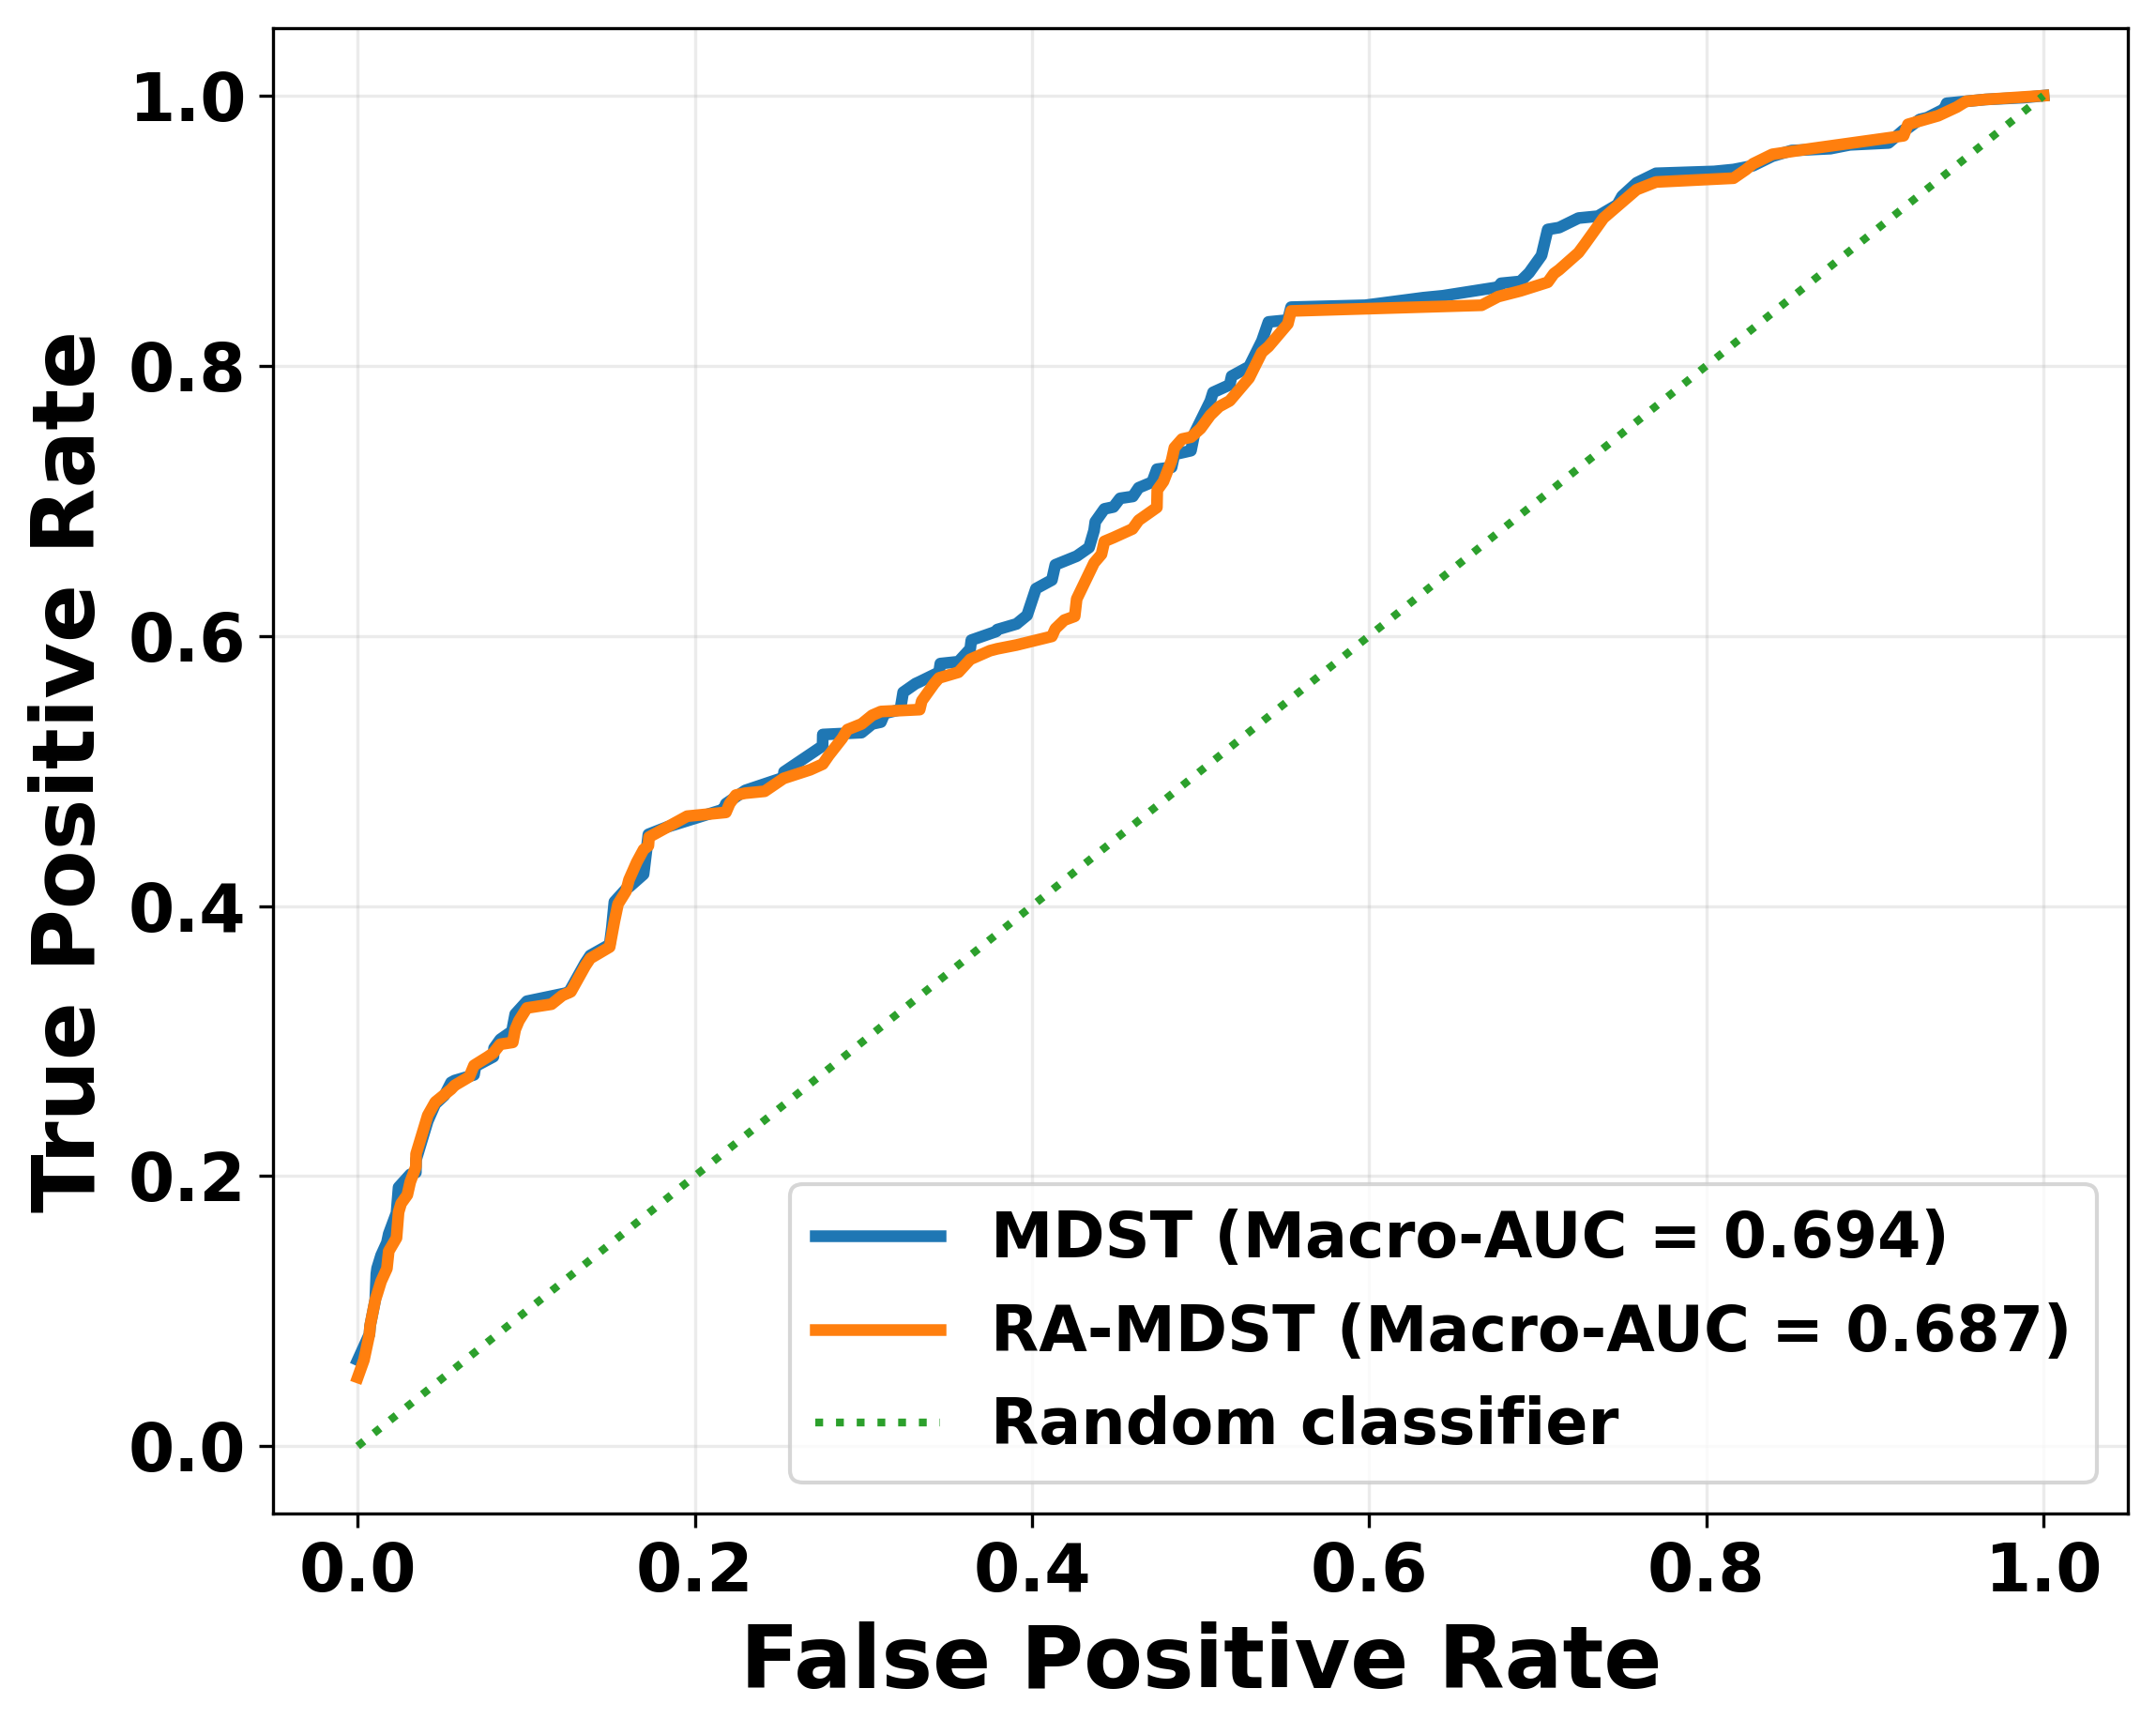

{'MDST': np.float64(0.6936515726785879), 'RA-MDST': np.float64(0.6866967181032325)}


In [25]:
# ============================================================
# MACRO-AVERAGE ROC: MDST VS RA-MDST
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6.5))

auc_summary = {}

for method in ["MDST", "RA-MDST"]:

    y_true = results[method]["y_true"]
    scores = results[method]["scores"]

    y_bin = label_binarize(
        y_true,
        classes=classes
    )

    all_fpr = np.unique(
        np.concatenate([
            roc_curve(
                y_bin[:, i],
                scores[:, i]
            )[0]
            for i in range(n_classes)
        ])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(n_classes):

        fpr, tpr, _ = roc_curve(
            y_bin[:, i],
            scores[:, i]
        )

        mean_tpr += np.interp(
            all_fpr,
            fpr,
            tpr
        )

    mean_tpr /= n_classes

    macro_auc = auc(
        all_fpr,
        mean_tpr
    )

    auc_summary[method] = macro_auc

    ax.plot(
        all_fpr,
        mean_tpr,
        linewidth=3,
        label=f"{method} (Macro-AUC = {macro_auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    linewidth=2,
    label="Random classifier"
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=22,
    fontweight="bold"
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=22,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=17
)

ax.legend(
    fontsize=16,
    loc="lower right"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Fig_MDST_vs_RA_MDST_Macro_ROC.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(auc_summary)

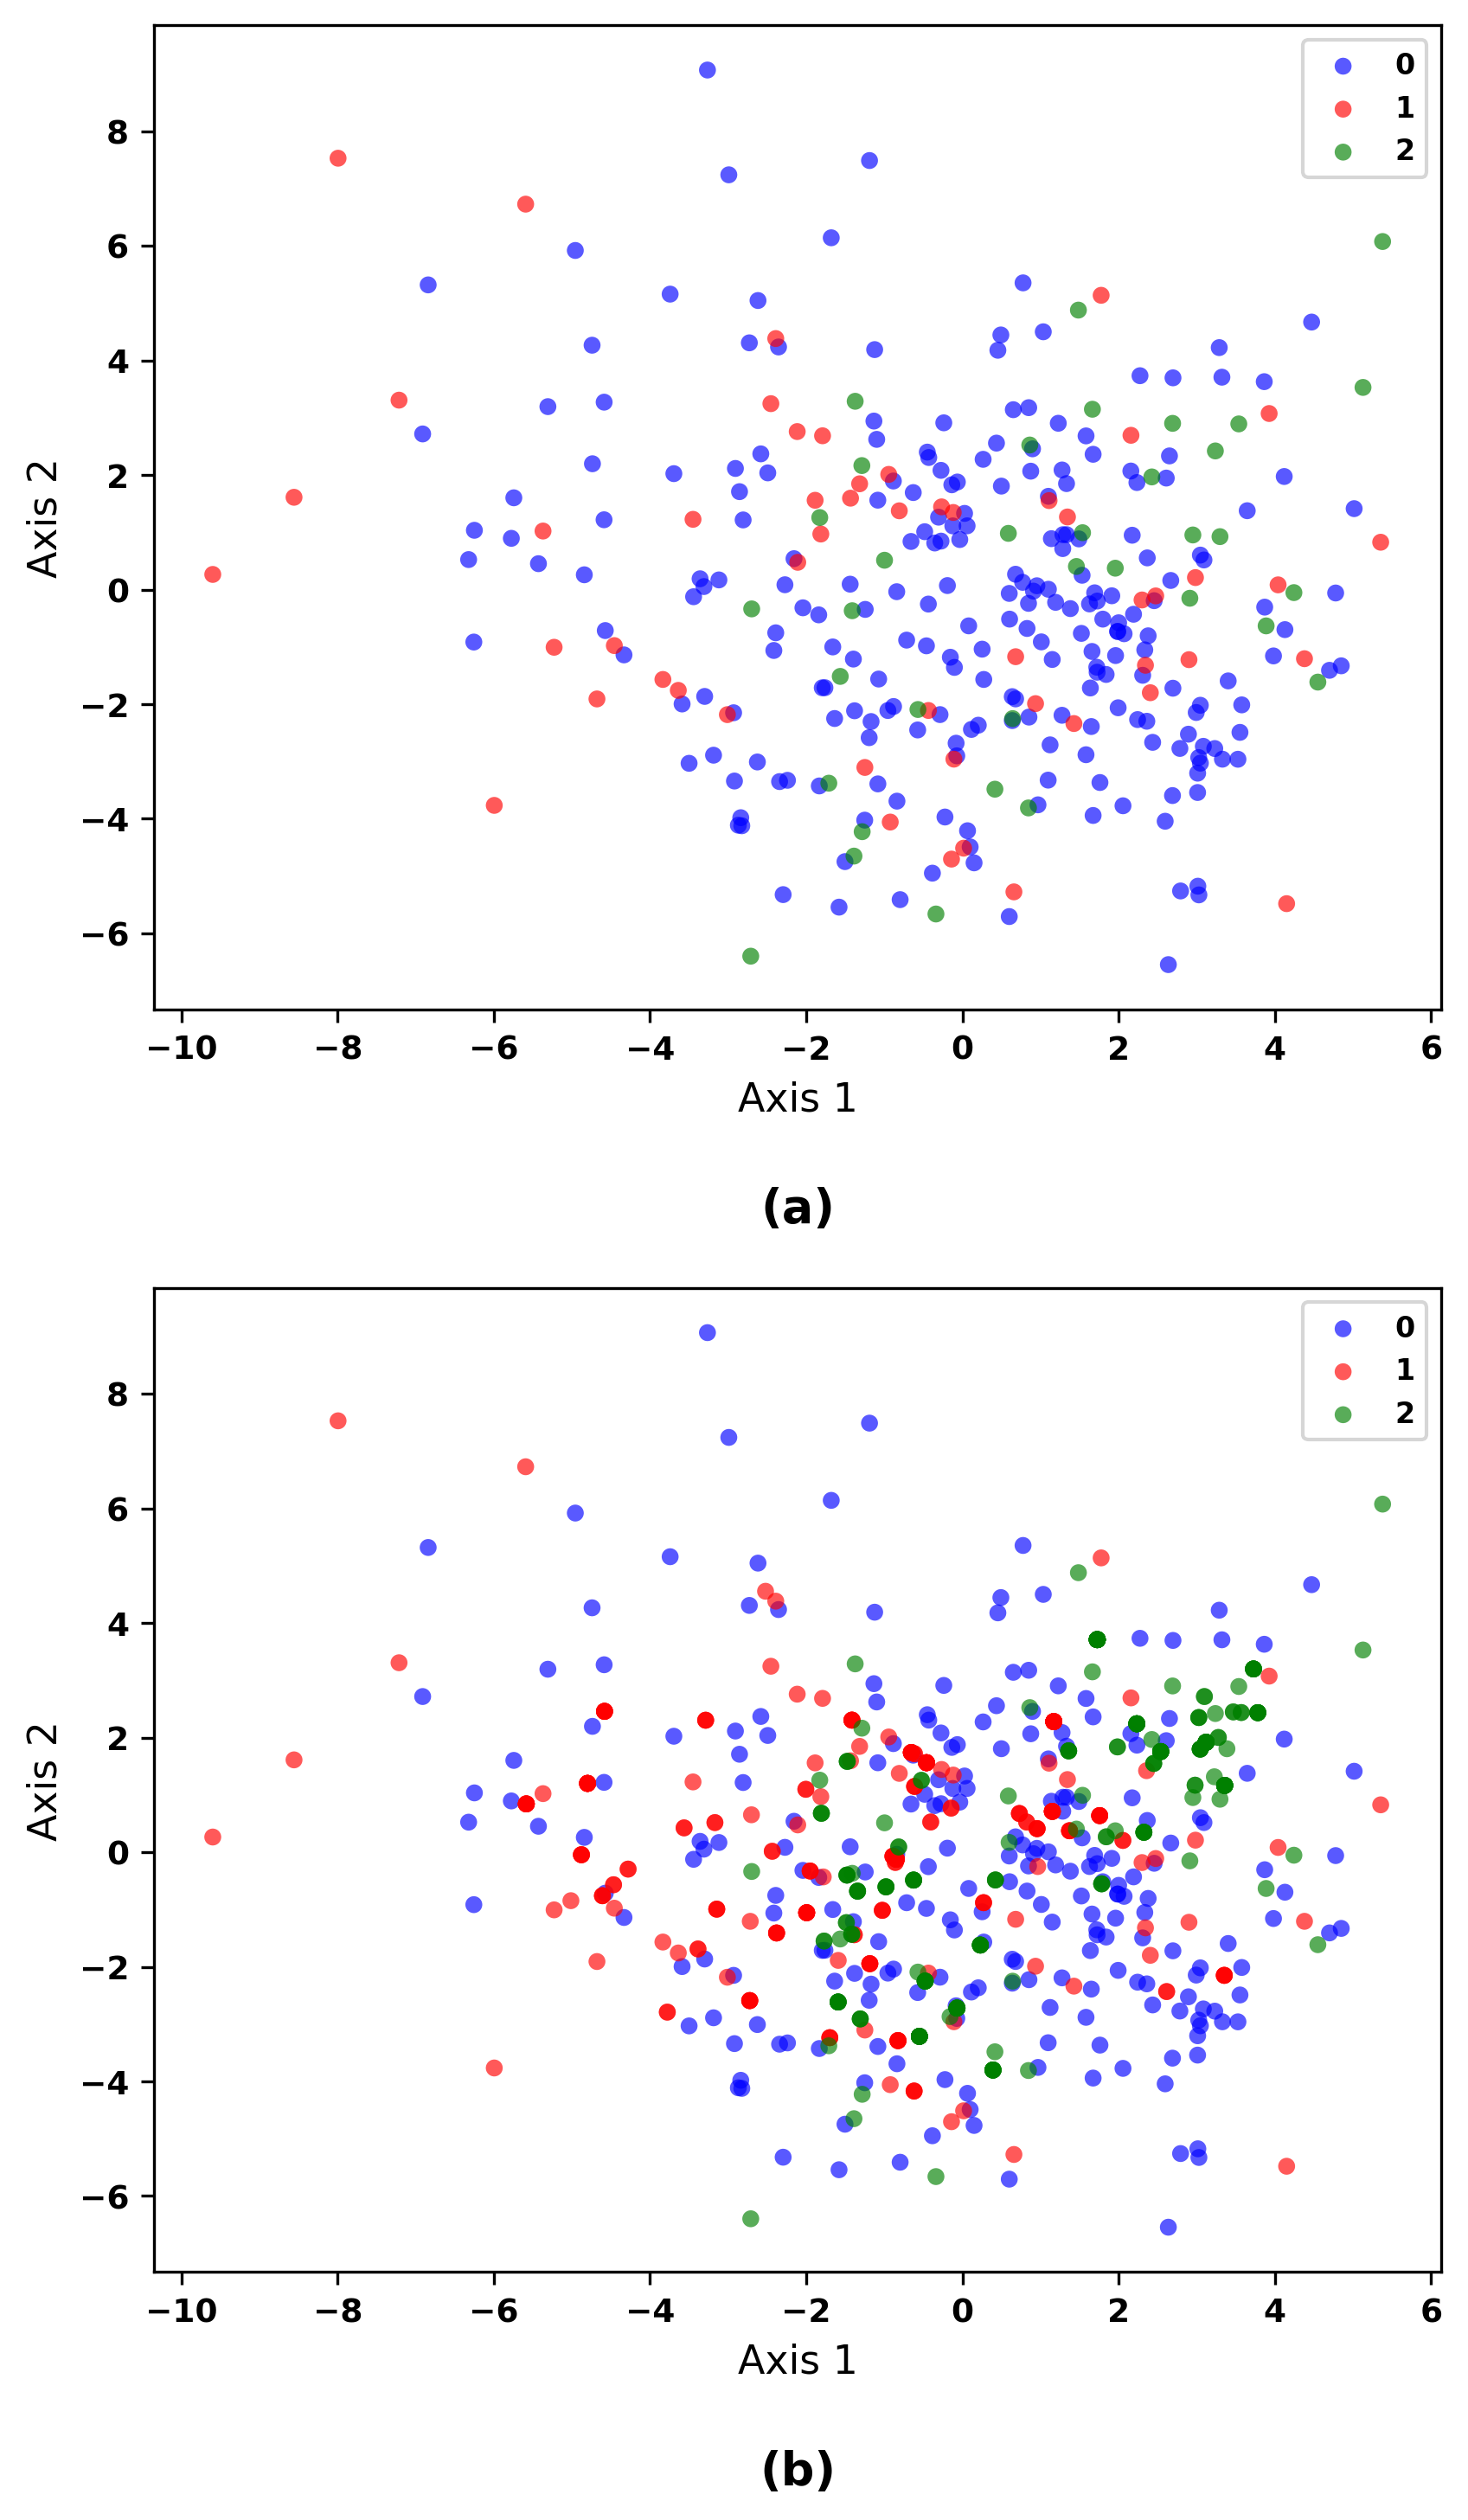

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ============================================================
# INPUTS YOU MUST ALREADY HAVE
# ============================================================
# X_df : pandas DataFrame of features
# y    : numpy array or pandas Series of class labels
#
# and your existing sampler function:
# apply_sampler(sampler_name, X_train, y_train, seed)
#
# Example sampler names used in your notebook:
# "MDST"
# "RA-DI-MDST"  # if old notebook naming still exists
# ============================================================

RANDOM_STATE = 42

# If y is a pandas Series, convert to numpy
if hasattr(y, "to_numpy"):
    y = y.to_numpy()

# ------------------------------------------------------------
# Original data
# ------------------------------------------------------------
X_orig = X_df.to_numpy(dtype=float)
y_orig = y.copy()

# ------------------------------------------------------------
# Generate MDST-balanced data
# ------------------------------------------------------------
X_mdst, y_mdst, _ = apply_sampler("MDST", X_orig, y_orig, seed=RANDOM_STATE)

# ------------------------------------------------------------
# Fit PCA on combined data so both plots use same projection space
# ------------------------------------------------------------
X_all = np.vstack([X_orig, X_mdst])

scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_all_2d = pca.fit_transform(X_all_scaled)

# Split back
n_orig = len(X_orig)
X_orig_2d = X_all_2d[:n_orig]
X_mdst_2d = X_all_2d[n_orig:]

# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------
class_labels = np.unique(y_orig)
colors = ['blue', 'red', 'green']   # class 0,1,2

fig, axes = plt.subplots(2, 1, figsize=(6, 10))

# -------------------------
# (a) Original dataset
# -------------------------
ax = axes[0]
for cls, color in zip(class_labels, colors):
    idx = (y_orig == cls)
    ax.scatter(
        X_orig_2d[idx, 0],
        X_orig_2d[idx, 1],
        s=22,
        alpha=0.65,
        c=color,
        label=str(cls),
        edgecolors='none'
    )

ax.set_xlabel("Axis 1", fontsize=11)
ax.set_ylabel("Axis 2", fontsize=11)
ax.legend(fontsize=8, loc="upper right")
ax.tick_params(labelsize=9)
ax.text(0.5, -0.18, "(a)", transform=ax.transAxes,
        ha="center", va="top", fontsize=13, fontweight="bold")

# -------------------------
# (b) MDST dataset
# -------------------------
ax = axes[1]
for cls, color in zip(np.unique(y_mdst), colors):
    idx = (y_mdst == cls)
    ax.scatter(
        X_mdst_2d[idx, 0],
        X_mdst_2d[idx, 1],
        s=22,
        alpha=0.65,
        c=color,
        label=str(cls),
        edgecolors='none'
    )

ax.set_xlabel("Axis 1", fontsize=11)
ax.set_ylabel("Axis 2", fontsize=11)
ax.legend(fontsize=8, loc="upper right")
ax.tick_params(labelsize=9)
ax.text(0.5, -0.18, "(b)", transform=ax.transAxes,
        ha="center", va="top", fontsize=13, fontweight="bold")

plt.tight_layout()

plt.savefig("Class_Distribution_Original_vs_MDST.png", dpi=300, bbox_inches="tight")
plt.savefig("Class_Distribution_Original_vs_MDST.pdf", bbox_inches="tight")

plt.show()

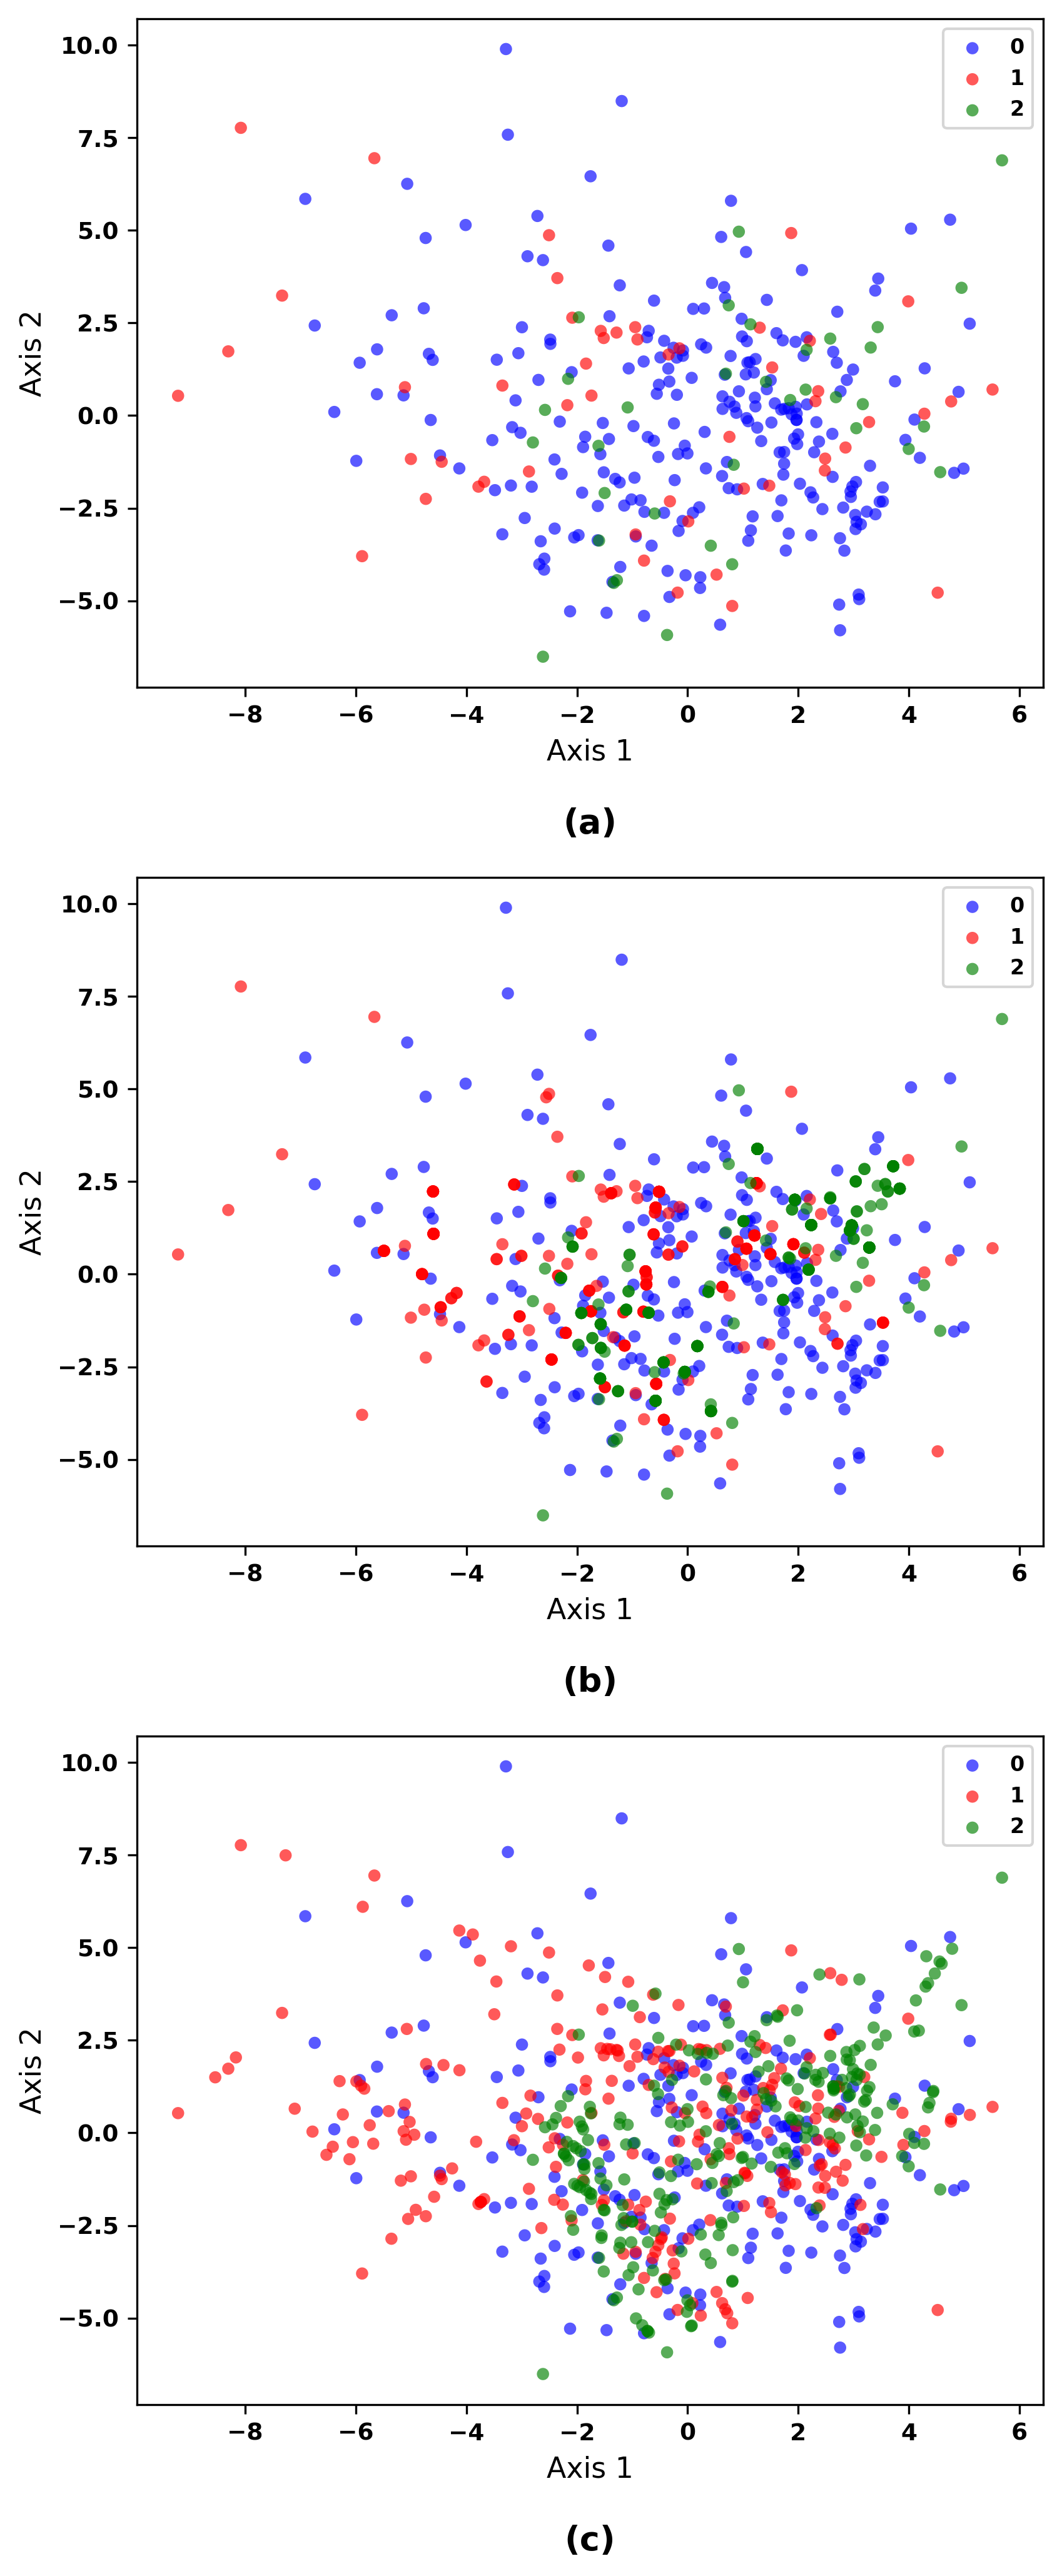

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_STATE = 42

if hasattr(y, "to_numpy"):
    y = y.to_numpy()

X_orig = X_df.to_numpy(dtype=float)
y_orig = y.copy()

# MDST
X_mdst, y_mdst, _ = apply_sampler("MDST", X_orig, y_orig, seed=RANDOM_STATE)

# RA-MDST
# IMPORTANT:
# If your notebook still uses old naming, keep "RA-DI-MDST"
X_ramdst, y_ramdst, _ = apply_sampler("RA-DI-MDST", X_orig, y_orig, seed=RANDOM_STATE)

# Combined PCA space
X_all = np.vstack([X_orig, X_mdst, X_ramdst])

scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_all_2d = pca.fit_transform(X_all_scaled)

n1 = len(X_orig)
n2 = len(X_mdst)
n3 = len(X_ramdst)

X_orig_2d = X_all_2d[:n1]
X_mdst_2d = X_all_2d[n1:n1+n2]
X_ramdst_2d = X_all_2d[n1+n2:n1+n2+n3]

class_labels = np.unique(y_orig)
colors = ['blue', 'red', 'green']

fig, axes = plt.subplots(3, 1, figsize=(6, 14))

datasets = [
    (X_orig_2d, y_orig, "(a)", "Original"),
    (X_mdst_2d, y_mdst, "(b)", "MDST"),
    (X_ramdst_2d, y_ramdst, "(c)", "RA-MDST")
]

for ax, (X2d, yy, panel, title) in zip(axes, datasets):
    for cls, color in zip(np.unique(yy), colors):
        idx = (yy == cls)
        ax.scatter(
            X2d[idx, 0],
            X2d[idx, 1],
            s=22,
            alpha=0.65,
            c=color,
            label=str(cls),
            edgecolors='none'
        )

    ax.set_xlabel("Axis 1", fontsize=11)
    ax.set_ylabel("Axis 2", fontsize=11)
    ax.legend(fontsize=8, loc="upper right")
    ax.tick_params(labelsize=9)
    ax.text(0.5, -0.18, panel, transform=ax.transAxes,
            ha="center", va="top", fontsize=13, fontweight="bold")

plt.tight_layout()

plt.savefig("Class_Distribution_Original_MDST_RAMDST.png", dpi=300, bbox_inches="tight")
plt.savefig("Class_Distribution_Original_MDST_RAMDST.pdf", bbox_inches="tight")

plt.show()

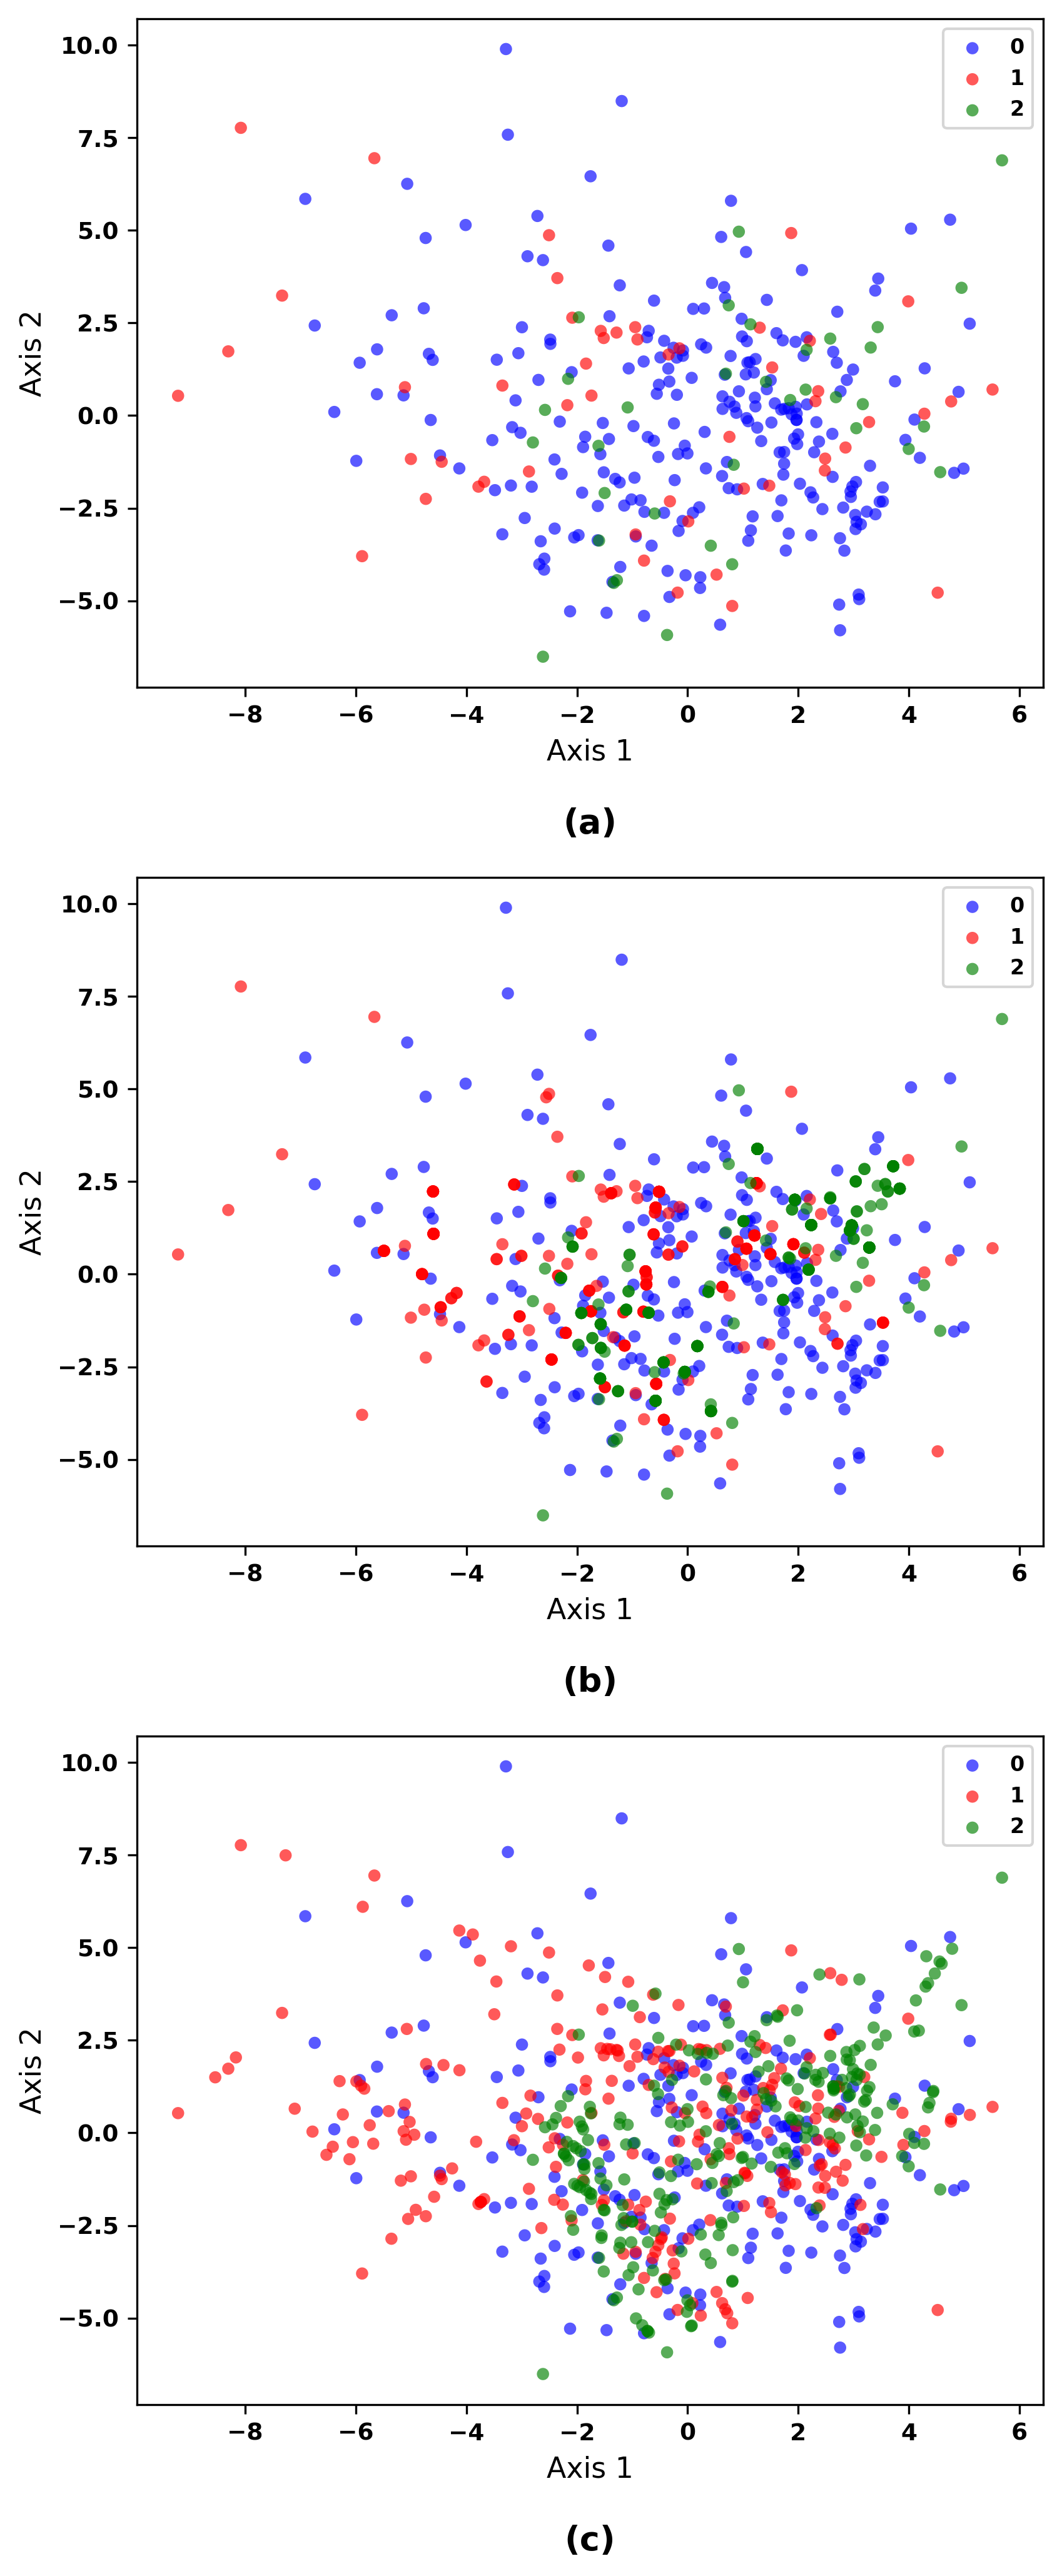

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_STATE = 42

if hasattr(y, "to_numpy"):
    y = y.to_numpy()

X_orig = X_df.to_numpy(dtype=float)
y_orig = y.copy()

# MDST
X_mdst, y_mdst, _ = apply_sampler("MDST", X_orig, y_orig, seed=RANDOM_STATE)

# RA-MDST
# IMPORTANT:
# If your notebook still uses old naming, keep "RA-DI-MDST"
X_ramdst, y_ramdst, _ = apply_sampler("RA-DI-MDST", X_orig, y_orig, seed=RANDOM_STATE)

# Combined PCA space
X_all = np.vstack([X_orig, X_mdst, X_ramdst])

scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_all_2d = pca.fit_transform(X_all_scaled)

n1 = len(X_orig)
n2 = len(X_mdst)
n3 = len(X_ramdst)

X_orig_2d = X_all_2d[:n1]
X_mdst_2d = X_all_2d[n1:n1+n2]
X_ramdst_2d = X_all_2d[n1+n2:n1+n2+n3]

class_labels = np.unique(y_orig)
colors = ['blue', 'red', 'green']

fig, axes = plt.subplots(3, 1, figsize=(6, 14))

datasets = [
    (X_orig_2d, y_orig, "(a)", "Original"),
    (X_mdst_2d, y_mdst, "(b)", "MDST"),
    (X_ramdst_2d, y_ramdst, "(c)", "RA-MDST")
]

for ax, (X2d, yy, panel, title) in zip(axes, datasets):
    for cls, color in zip(np.unique(yy), colors):
        idx = (yy == cls)
        ax.scatter(
            X2d[idx, 0],
            X2d[idx, 1],
            s=22,
            alpha=0.65,
            c=color,
            label=str(cls),
            edgecolors='none'
        )

    ax.set_xlabel("Axis 1", fontsize=11)
    ax.set_ylabel("Axis 2", fontsize=11)
    ax.legend(fontsize=8, loc="upper right")
    ax.tick_params(labelsize=9)
    ax.text(0.5, -0.18, panel, transform=ax.transAxes,
            ha="center", va="top", fontsize=13, fontweight="bold")

plt.tight_layout()

plt.savefig("Class_Distribution_Original_MDST_RAMDST.png", dpi=300, bbox_inches="tight")
plt.savefig("Class_Distribution_Original_MDST_RAMDST.pdf", bbox_inches="tight")

plt.show()

Index(['sampler', 'model', 'class', 'precision', 'recall', 'f1', 'support'], dtype='object')


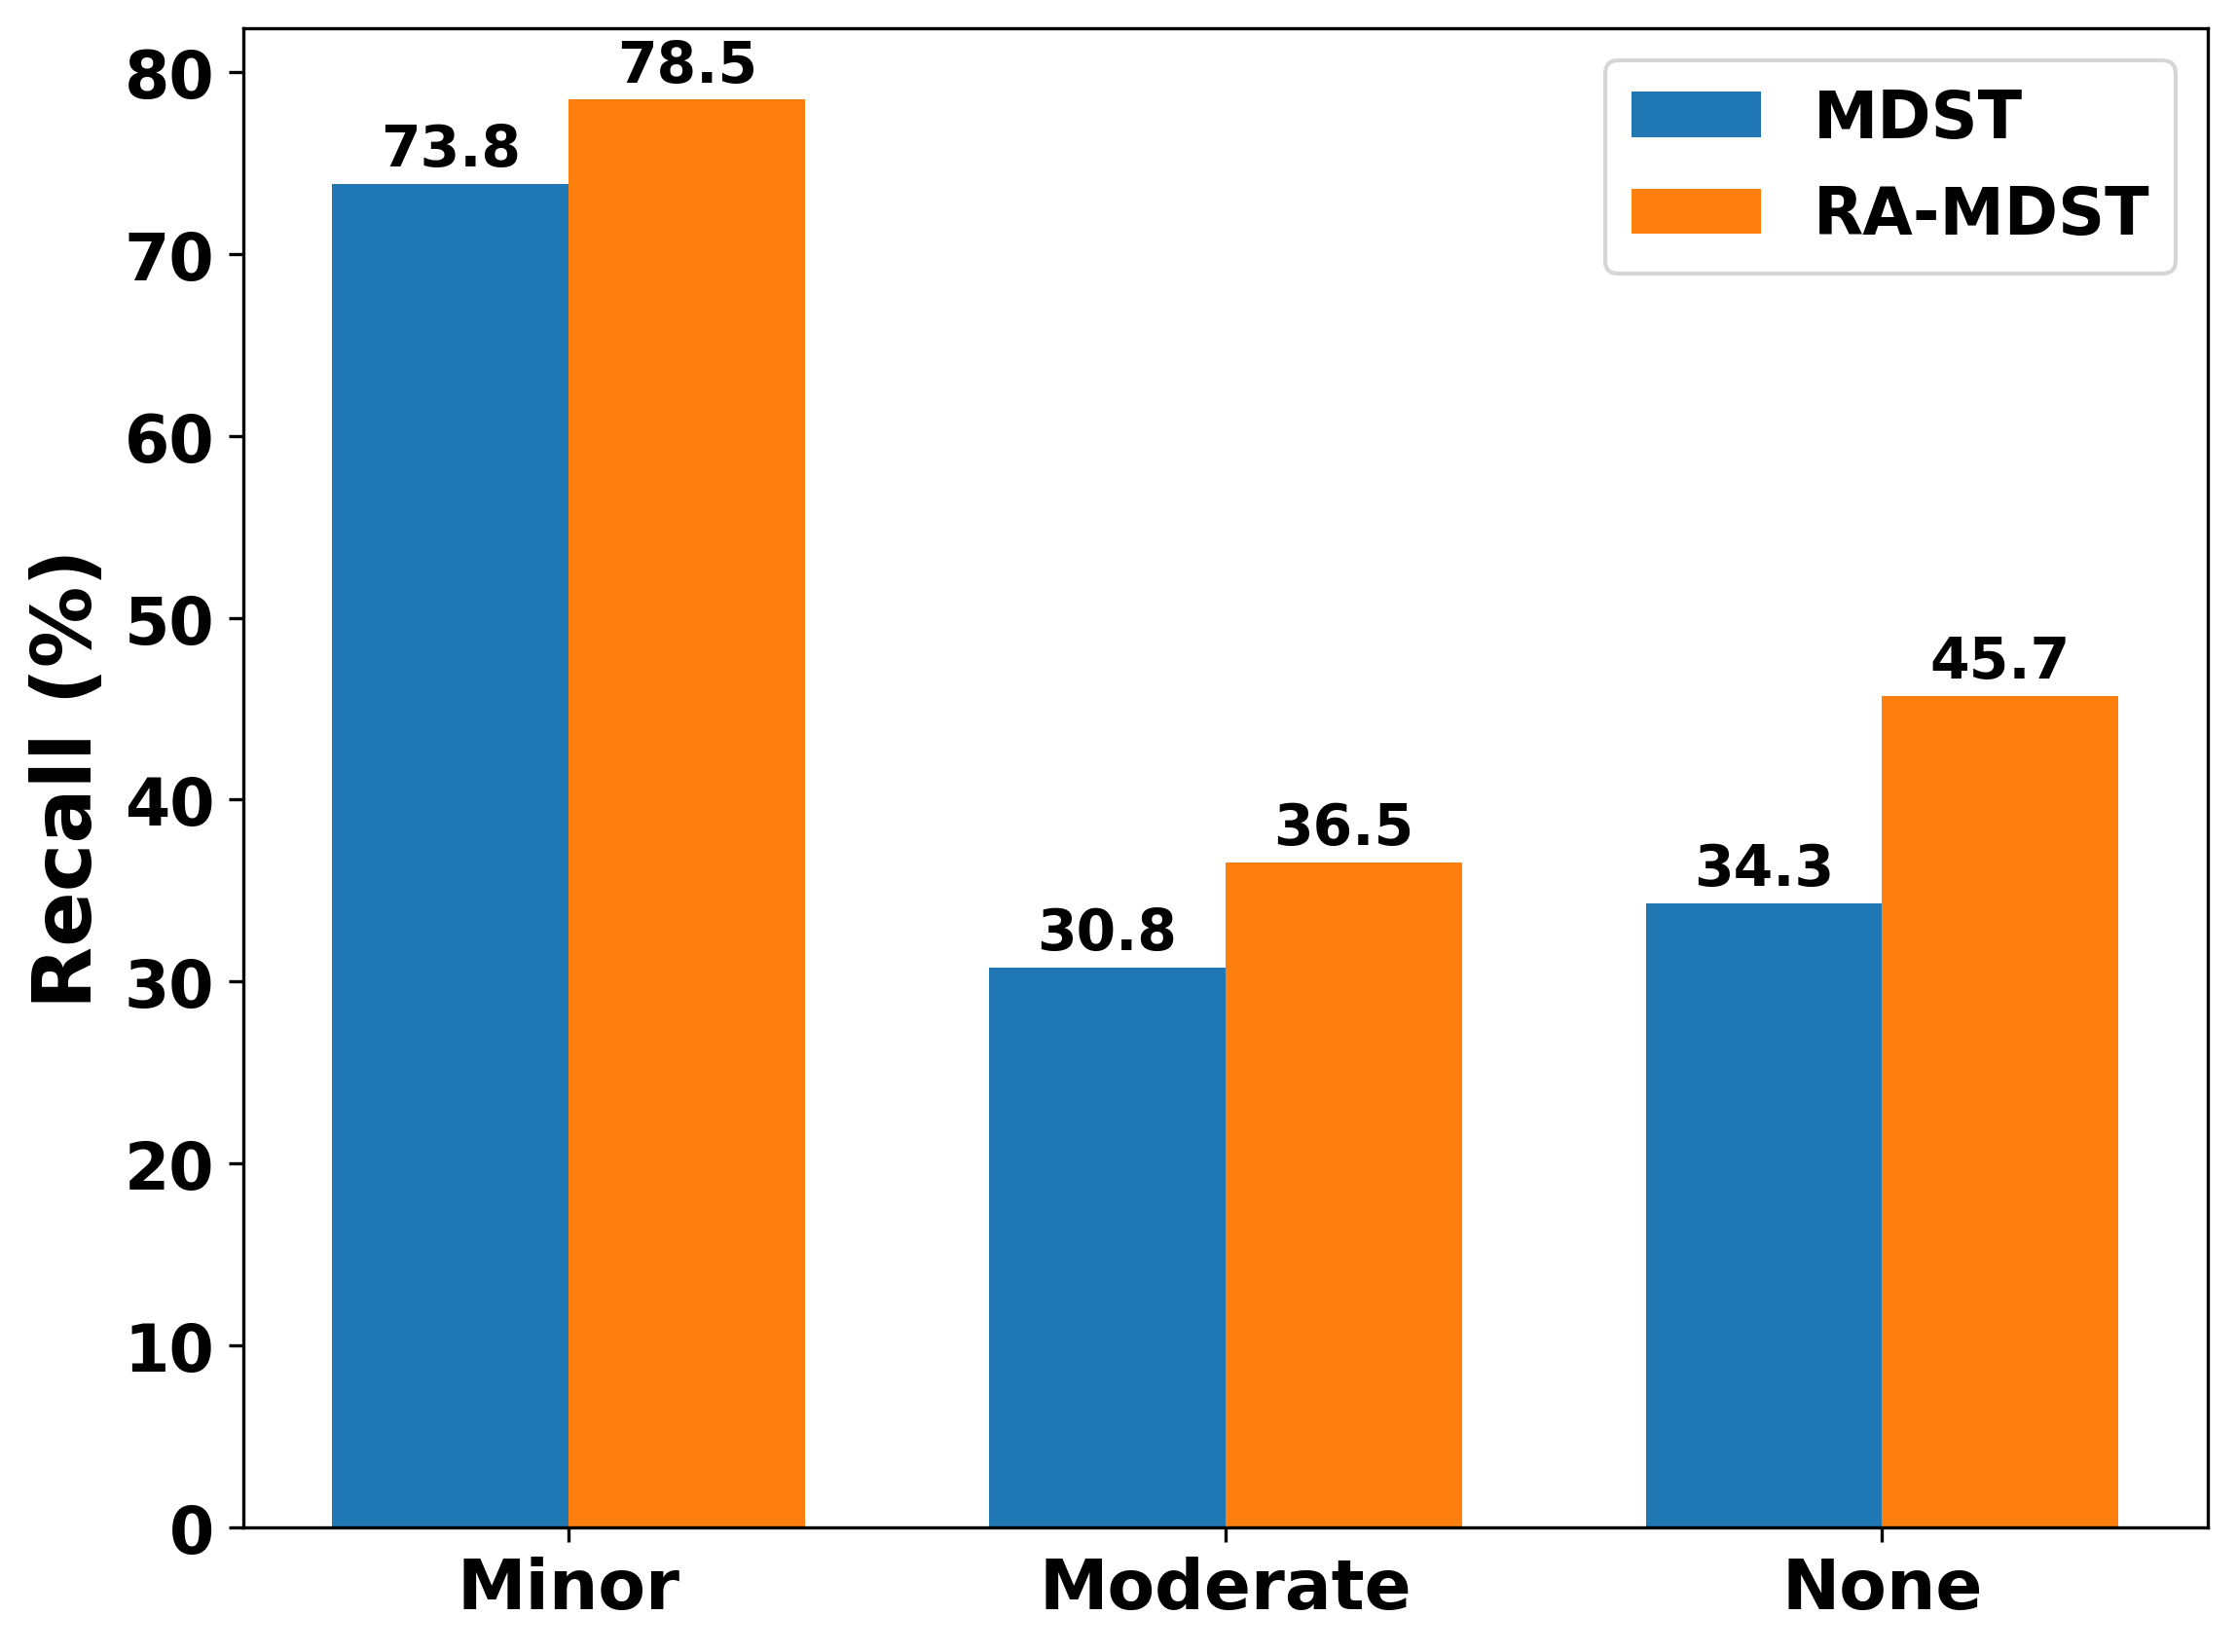

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PER-CLASS RECALL: MDST vs RA-MDST
# ============================================================

# Change this if your dataframe has a different name
df = class_df.copy()

# Check available columns
print(df.columns)

# Expected columns similar to:
# sampler, model, class, recall

# Rename old method for publication display
df["sampler_display"] = df["sampler"].replace({
    "RA-DI-MDST": "RA-MDST"
})

# Example: choose one strong classifier
MODEL_TO_PLOT = "DecisionTree"

p = df[
    (df["model"] == MODEL_TO_PLOT) &
    (df["sampler"].isin(["MDST", "RA-DI-MDST"]))
].copy()

# If class column is numeric
class_map = {
    0: "Minor",
    1: "Moderate",
    2: "None"
}

p["class_name"] = p["class"].map(class_map)

classes_plot = ["Minor", "Moderate", "None"]

mdst_vals = []
ra_vals = []

for cls in classes_plot:

    mdst_vals.append(
        p[
            (p["sampler"] == "MDST") &
            (p["class_name"] == cls)
        ]["recall"].mean() * 100
    )

    ra_vals.append(
        p[
            (p["sampler"] == "RA-DI-MDST") &
            (p["class_name"] == cls)
        ]["recall"].mean() * 100
    )

x = np.arange(len(classes_plot))
w = 0.36

fig, ax = plt.subplots(figsize=(8, 6))

b1 = ax.bar(
    x - w/2,
    mdst_vals,
    width=w,
    label="MDST"
)

b2 = ax.bar(
    x + w/2,
    ra_vals,
    width=w,
    label="RA-MDST"
)

ax.set_xticks(x)
ax.set_xticklabels(
    classes_plot,
    fontsize=17
)

ax.set_ylabel(
    "Recall (%)",
    fontsize=20,
    fontweight="bold"
)

ax.tick_params(axis='y', labelsize=16)

ax.legend(fontsize=16)

for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 1,
            f"{h:.1f}",
            ha="center",
            fontsize=14
        )

plt.tight_layout()

plt.savefig(
    "Fig_Classwise_Recall_MDST_RA_MDST.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

MDST mean distance: 6.072850098251279
RA-MDST mean distance: 5.3624539870205785


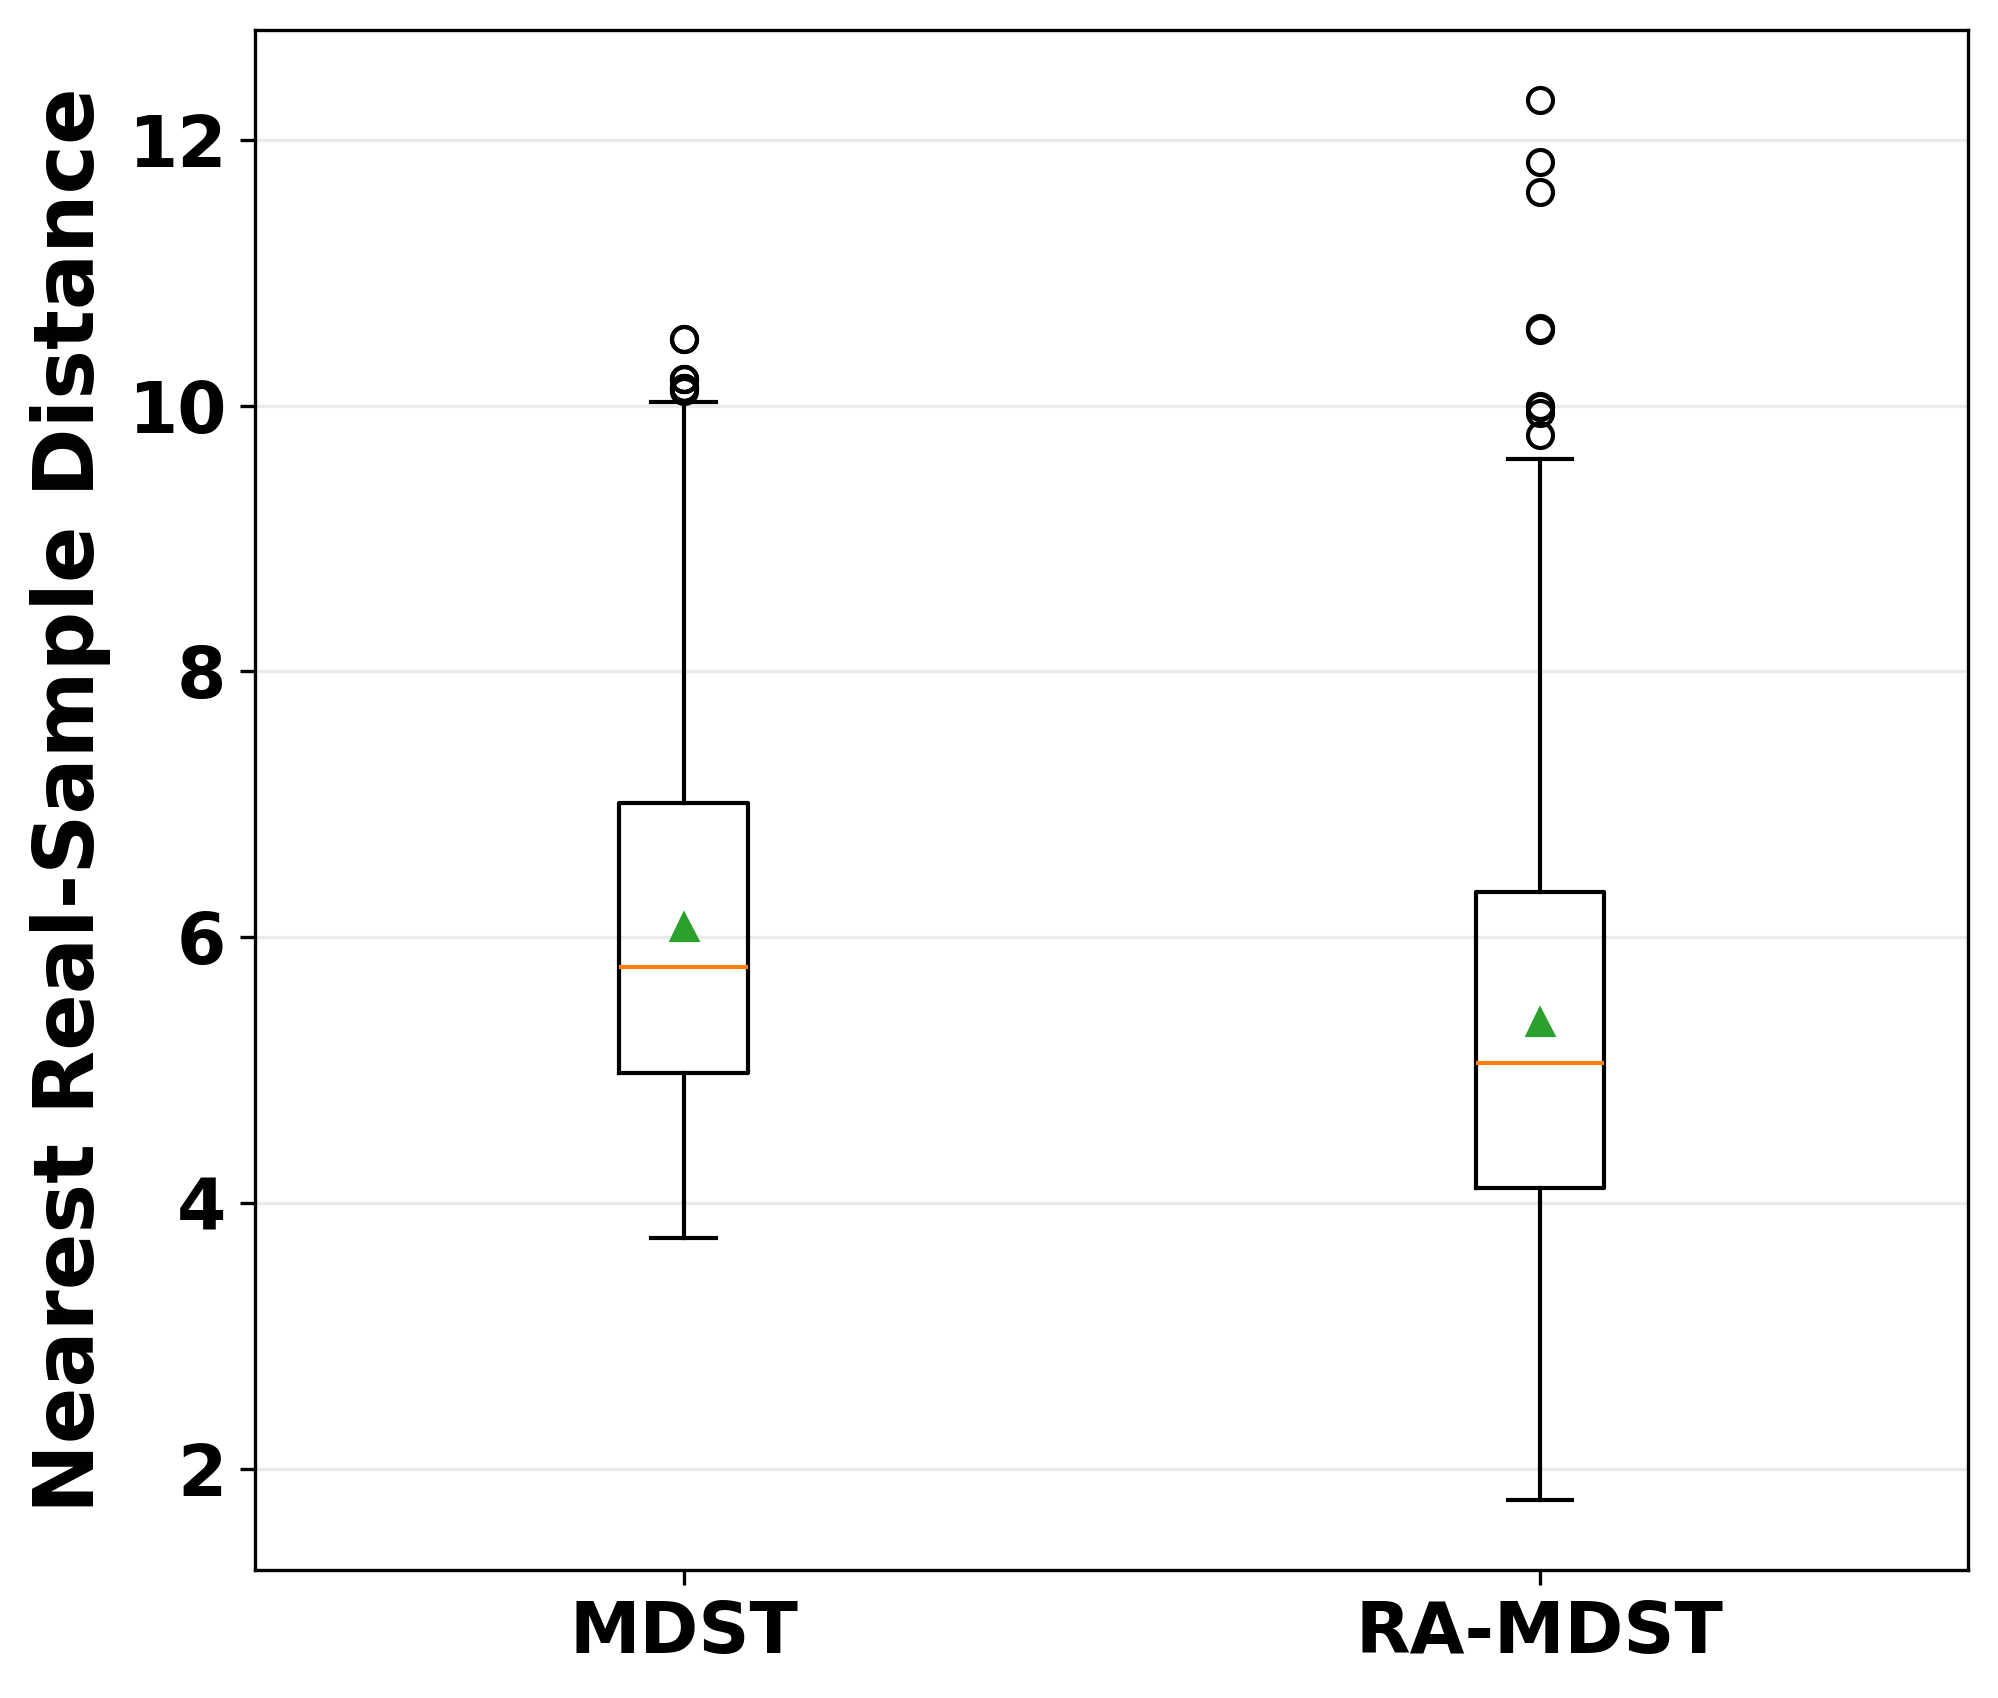

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

# ============================================================
# SYNTHETIC-TO-REAL NEAREST-NEIGHBOR DISTANCE
# MDST vs RA-MDST
# ============================================================

SEED = 42

X_real = X_df.to_numpy(dtype=float)
y_real = np.asarray(y)

# Standardize once for visualization diagnostic
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_real)

# Generate balanced datasets
X_mdst, y_mdst, _ = apply_sampler(
    "MDST",
    X_scaled,
    y_real,
    seed=SEED
)

X_ra, y_ra, _ = apply_sampler(
    "RA-DI-MDST",
    X_scaled,
    y_real,
    seed=SEED
)

n_real = len(X_scaled)

# Samplers append synthetic observations after real data
X_syn_mdst = X_mdst[n_real:]
y_syn_mdst = y_mdst[n_real:]

X_syn_ra = X_ra[n_real:]
y_syn_ra = y_ra[n_real:]


def nearest_real_distance(X_syn, y_syn, X_real, y_real):

    distances = []

    for x, cls in zip(X_syn, y_syn):

        real_same = X_real[y_real == cls]

        d = pairwise_distances(
            x.reshape(1, -1),
            real_same,
            metric="euclidean"
        )

        distances.append(d.min())

    return np.asarray(distances)


d_mdst = nearest_real_distance(
    X_syn_mdst,
    y_syn_mdst,
    X_scaled,
    y_real
)

d_ra = nearest_real_distance(
    X_syn_ra,
    y_syn_ra,
    X_scaled,
    y_real
)

print("MDST mean distance:", d_mdst.mean())
print("RA-MDST mean distance:", d_ra.mean())

# ------------------------------------------------------------
# Boxplot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))

bp = ax.boxplot(
    [d_mdst, d_ra],
    labels=["MDST", "RA-MDST"],
    showmeans=True
)

ax.set_ylabel(
    "Nearest Real-Sample Distance",
    fontsize=20,
    fontweight="bold"
)

ax.tick_params(
    axis='both',
    labelsize=17
)

ax.grid(
    axis='y',
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Fig_Synthetic_Diversity_Distance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

   class   overlap  pool_size
0      1  0.666667          6
1      1  1.000000          6
2      1  0.666667          6
3      1  0.666667          6
4      1  1.000000          6
pool_size
6    387
Name: count, dtype: int64


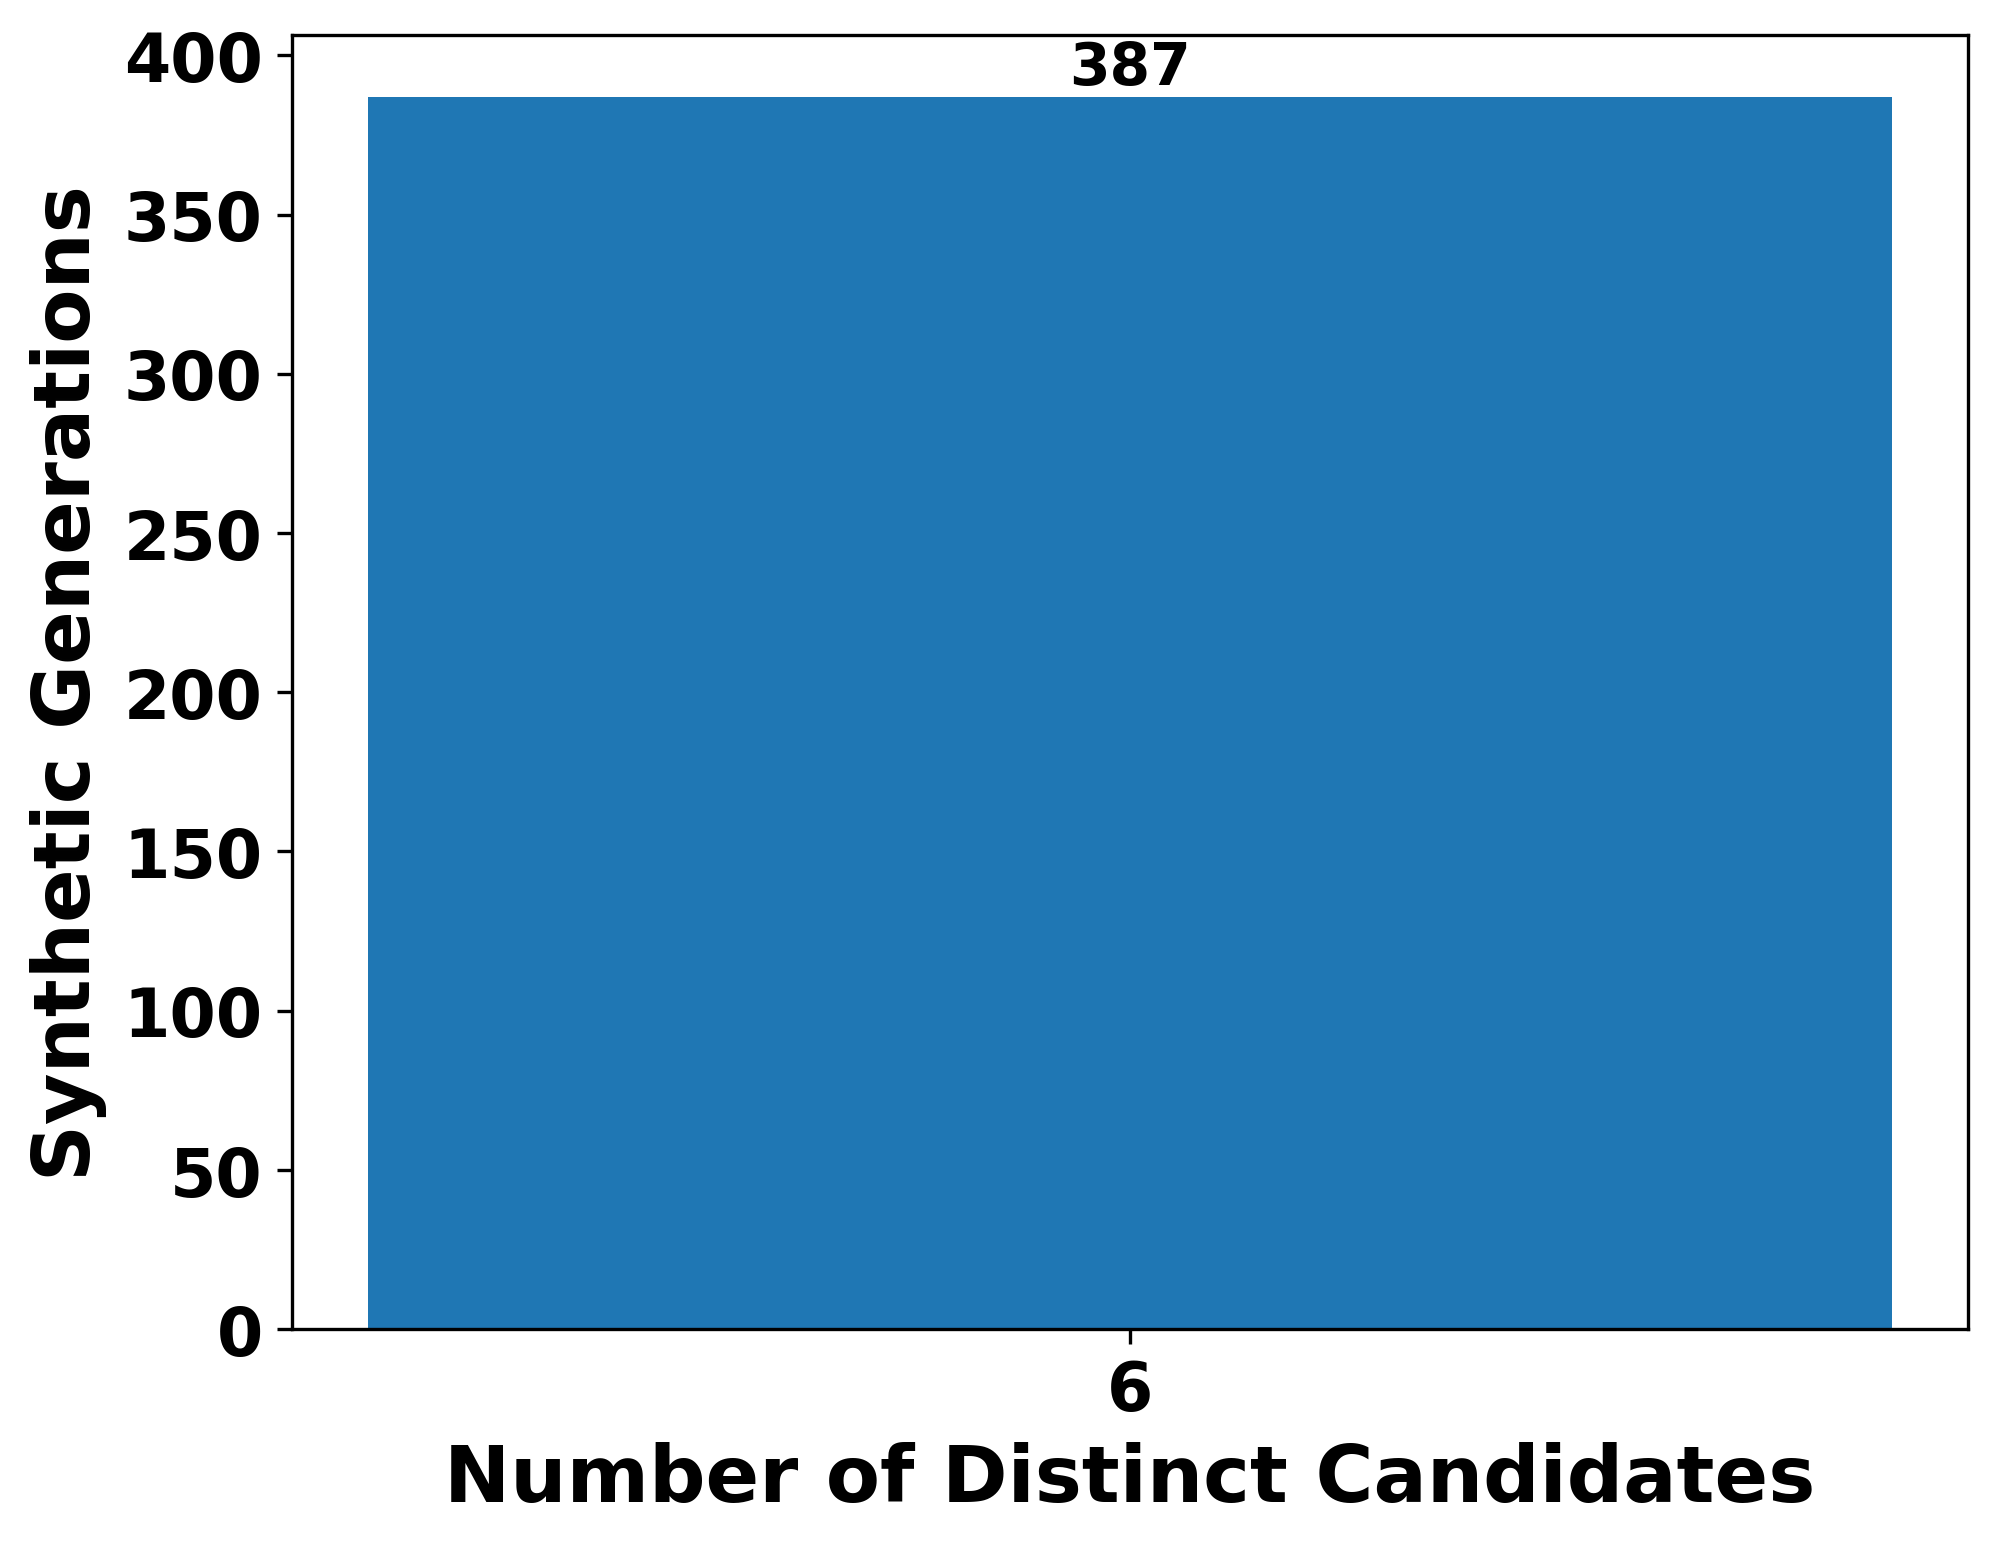

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# ============================================================
# RA-MDST DIVERSIFIED POOL SIZE DISTRIBUTION
# ============================================================

X_real = X_df.to_numpy(dtype=float)
y_real = np.asarray(y)

X_scaled = StandardScaler().fit_transform(X_real)

X_ra, y_ra, diag = apply_sampler(
    "RA-DI-MDST",
    X_scaled,
    y_real,
    seed=42
)

print(diag.head())
print(diag["pool_size"].value_counts().sort_index())

counts = (
    diag["pool_size"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 5.5))

bars = ax.bar(
    counts.index.astype(str),
    counts.values
)

ax.set_xlabel(
    "Number of Distinct Candidates",
    fontsize=19,
    fontweight="bold"
)

ax.set_ylabel(
    "Synthetic Generations",
    fontsize=19,
    fontweight="bold"
)

ax.tick_params(
    axis='both',
    labelsize=16
)

for bar in bars:
    h = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        h,
        str(int(h)),
        ha="center",
        va="bottom",
        fontsize=14
    )

plt.tight_layout()

plt.savefig(
    "Fig_RA_MDST_Pool_Size_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

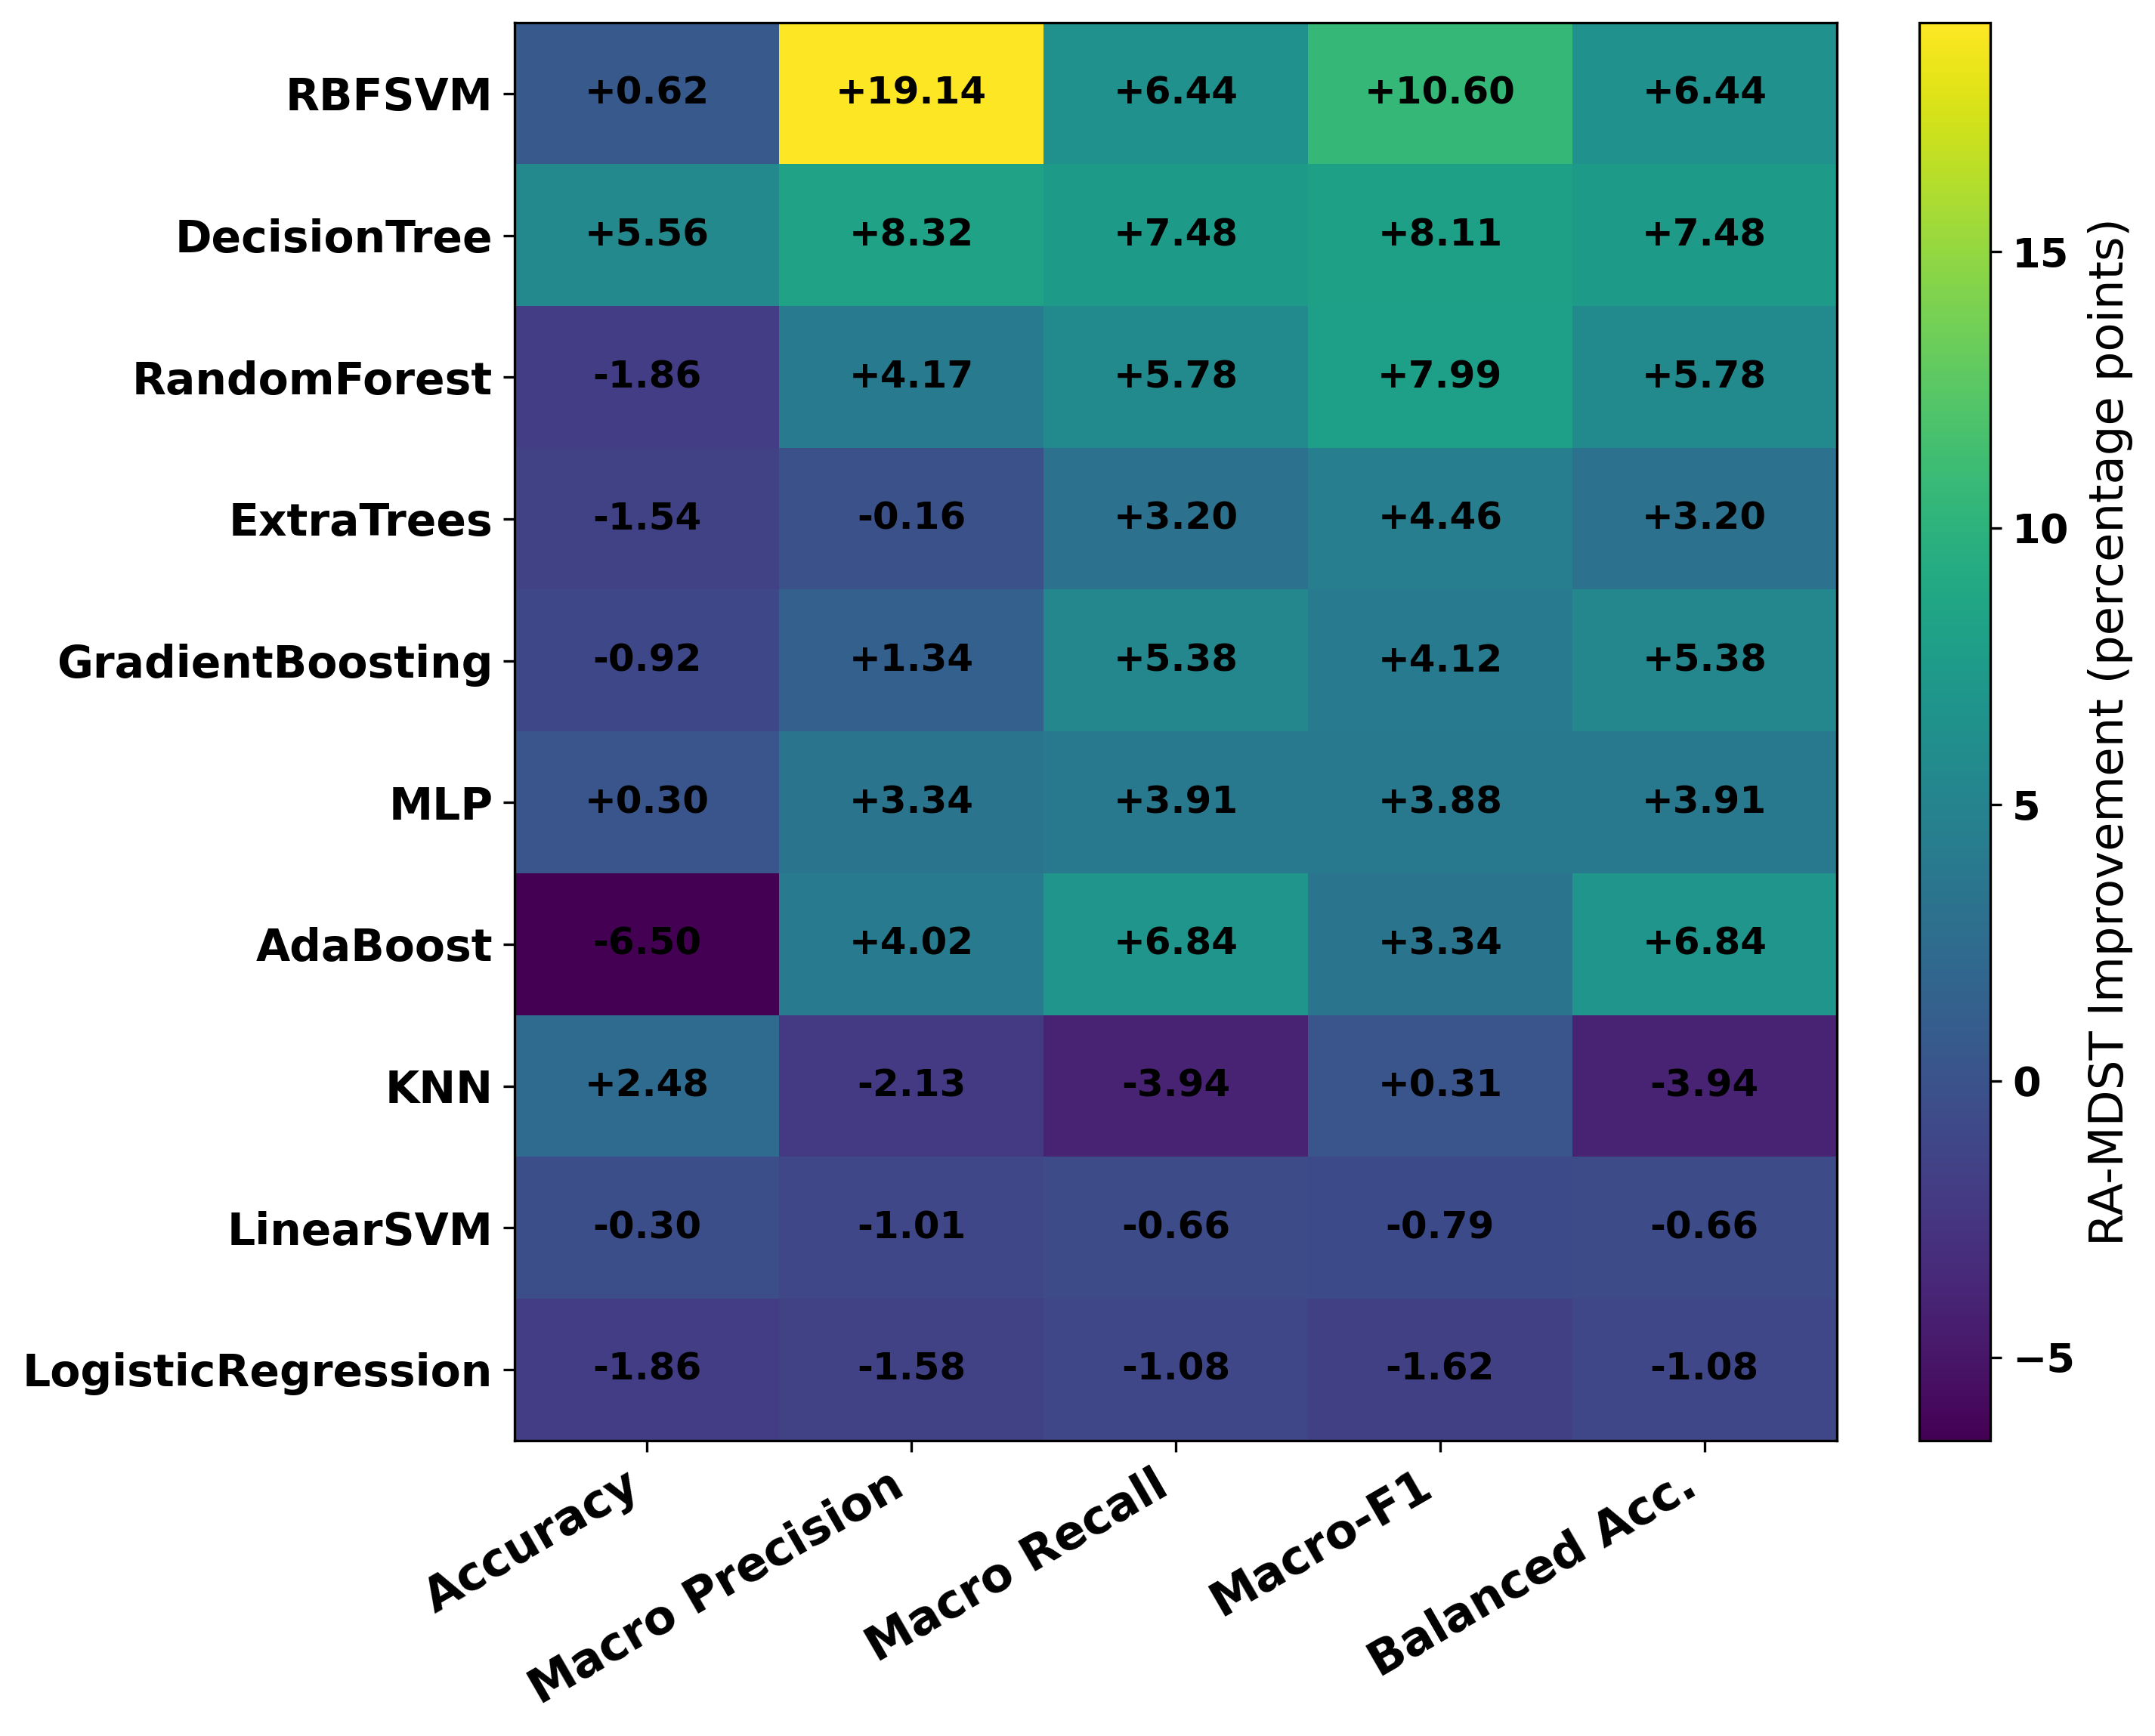

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PERFORMANCE-GAIN HEATMAP
# RA-MDST minus MDST
# ============================================================

plot_df = comparison_df.copy()

metrics = [
    "delta_accuracy",
    "delta_precision_macro",
    "delta_recall_macro",
    "delta_f1_macro",
    "delta_balanced_accuracy"
]

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro-F1",
    "Balanced Acc."
]

models = plot_df["model"].tolist()

data = (
    plot_df[metrics]
    .to_numpy(dtype=float)
    * 100
)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    data,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(metric_names))
)

ax.set_xticklabels(
    metric_names,
    rotation=30,
    ha="right",
    fontsize=15
)

ax.set_yticks(
    np.arange(len(models))
)

ax.set_yticklabels(
    models,
    fontsize=14
)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):

        ax.text(
            j,
            i,
            f"{data[i,j]:+.2f}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold"
        )

cbar = fig.colorbar(im, ax=ax)

cbar.set_label(
    "RA-MDST Improvement (percentage points)",
    fontsize=15
)

cbar.ax.tick_params(labelsize=13)

plt.tight_layout()

plt.savefig(
    "Fig_RA_MDST_Metric_Gain_Heatmap.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()